# Generalization Experiments

## Setup and Robustness Data Split

This notebook investigates why the MLP, Standard GRU, and PairwiseGRU perform substantially worse on the official test set than on validation data.

We examine potential generalization problems through controlled development experiments, including architecture adjustments, training configurations, and dataset characteristics.

We load the frozen 300-dimensional fastText embeddings and establish reproducible experimental settings using seed 42.

In [1]:
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from datasets import load_dataset

# Locate project
repo_root = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "project1/artifacts/fasttext_art.pt").exists()
    ),
    None
)

assert repo_root is not None, "Project root not found"

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from project1.src.models import (
    EmbeddingMLP,
    EmbeddingGRU,
    PairwiseGRU
)
from project1.src.preprocessing import tokenize
from project1.src.data_loader import create_dataloader

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

artifact_dir = repo_root / "project1/artifacts"
output_dir = artifact_dir / "generalization_07"
output_dir.mkdir(parents=True, exist_ok=True)

saved = torch.load(
    artifact_dir / "fasttext_art.pt",
    map_location="cpu",
    weights_only=True
)

vocab = saved["vocab"]
embedding_weights = saved["embedding_weights"]

print("Device:", device)
print("Vocabulary:", len(vocab))
print("Embedding shape:", embedding_weights.shape)


C:\Users\kimbo\anaconda3\envs\nlp-art-hs26\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
Vocabulary: 15038
Embedding shape: torch.Size([15038, 300])


In [2]:
train_data = load_dataset(
    "amarfurt/art-nlp-hs26",
    split="train"
)

def similarity(example):
    h1 = set(tokenize(example["hypothesis_1"]))
    h2 = set(tokenize(example["hypothesis_2"]))

    union = h1 | h2
    return len(h1 & h2) / len(union) if union else 1.0


train_similarities = np.array([
    similarity(ex) for ex in train_data
])

# Lowest-similarity 10%
n_hard = int(len(train_data) * 0.10)

hard_indices = np.argsort(
    train_similarities,
    kind="stable"
)[:n_hard]

rng = np.random.default_rng(42)

hard_pool = np.array(hard_indices, dtype=int).copy()
rng.shuffle(hard_pool)

hard_dev_indices = hard_pool[:840]
hard_train_indices = hard_pool[840:]

other_indices = np.setdiff1d(
    np.arange(len(train_data)),
    hard_pool
)

normal_dev_indices = rng.choice(
    other_indices,
    size=840,
    replace=False
)

excluded = set(
    hard_dev_indices.tolist()
    + normal_dev_indices.tolist()
)

development_train_indices = [
    i for i in range(len(train_data))
    if i not in excluded
]

robust_train_data = train_data.select(
    development_train_indices
)

hard_dev_data = train_data.select(
    hard_dev_indices.tolist()
)

normal_dev_data = train_data.select(
    normal_dev_indices.tolist()
)

assert len(robust_train_data) == 15121
assert len(hard_dev_data) == 840
assert len(normal_dev_data) == 840

def describe_split(name, dataset):
    sims = np.array([similarity(ex) for ex in dataset])
    labels = np.array(dataset["label"])

    print(f"\n{name}")
    print("Samples:", len(dataset))
    print(f"Mean similarity: {sims.mean():.3f}")
    print(f"Median similarity: {np.median(sims):.3f}")
    print(f"H1 labels: {(labels == 1).mean():.2%}")

describe_split("Development training", robust_train_data)
describe_split("Hard holdout", hard_dev_data)
describe_split("Normal holdout", normal_dev_data)



Development training
Samples: 15121
Mean similarity: 0.623
Median similarity: 0.667
H1 labels: 50.33%

Hard holdout
Samples: 840
Mean similarity: 0.160
Median similarity: 0.167
H1 labels: 49.17%

Normal holdout
Samples: 840
Mean similarity: 0.657
Median similarity: 0.667
H1 labels: 52.14%


### Robustness Development Split

We divide the original training data into three subsets based on Jaccard similarity between the two candidate hypotheses.

| Split | Examples | Mean similarity |
|---|---:|---:|
| Development training | 15,121 | 0.623 |
| Normal holdout | 840 | 0.657 |
| Hard holdout | 840 | 0.160 |

The hard holdout contains low-similarity examples, while the normal holdout represents more typical training examples.

Both holdouts are excluded from training in the new robustness experiments.

**Important:** The original pretrained checkpoints were trained on the full original training split. Therefore, evaluations of these existing checkpoints on these subsets are descriptive diagnostics, not independent held-out generalization measurements.

The official test set remains separate from this development split.

## Baseline Checkpoint Diagnostics and Hypothesis Similarity

We evaluate the previously trained MLP, Standard GRU, and PairwiseGRU checkpoints on the development subsets.

We compare accuracy and loss across the development-training, normal, and hard subsets.

We also group examples into Jaccard similarity intervals to investigate how model accuracy relates to lexical overlap between hypotheses.

**Important:** These original checkpoints were trained on the full original training dataset, including the examples in the new normal and hard holdouts. Therefore, these results are descriptive diagnostics, not independent generalization estimates.

In [3]:
checkpoints = {
    "MLP": (
        "mlp_multiseed_s42_drop0p2_lr0p0003_"
        "t6fumkja_best.pt"
    ),
    "Standard GRU": (
        "gru_multiseed_h128_lr0p001_drop0p0_"
        "seed42_cuda_hvxtunb8_best.pt"
    ),
    "PairwiseGRU": (
        "pairwise_gru_h128_l2_lr0p001_drop0p0_"
        "seed42_cuda_z6d879wl_best.pt"
    )
}

def create_embedding():
    return nn.Embedding.from_pretrained(
        embedding_weights.detach().cpu().clone(),
        freeze=True,
        padding_idx=vocab["[PAD]"]
    )

def create_mlp():
    return EmbeddingMLP(
        embedding_layer=create_embedding(),
        pad_id=vocab["[PAD]"],
        sep_id=vocab["[SEP]"],
        hidden_dim=128,
        dropout=0.2
    ).to(device)

def create_gru():
    return EmbeddingGRU(
        embedding_layer=create_embedding(),
        pad_id=vocab["[PAD]"],
        hidden_dim=128,
        num_layers=2,
        dropout=0.0
    ).to(device)

def create_pairwise():
    return PairwiseGRU(
        embedding_layer=create_embedding(),
        pad_id=vocab["[PAD]"],
        sep_id=vocab["[SEP]"],
        hidden_dim=128,
        num_layers=2,
        dropout=0.0
    ).to(device)

factories = {
    "MLP": create_mlp,
    "Standard GRU": create_gru,
    "PairwiseGRU": create_pairwise
}

models = {}

for name, factory in factories.items():
    path = artifact_dir / checkpoints[name]
    assert path.exists(), f"Missing checkpoint: {path}"

    model = factory()

    model.load_state_dict(
        torch.load(
            path,
            map_location=device,
            weights_only=True
        ),
        strict=True
    )

    model.eval()
    assert not model.embedding.weight.requires_grad

    models[name] = model
    print("Loaded:", name)


Loaded: MLP
Loaded: Standard GRU
Loaded: PairwiseGRU


In [4]:
@torch.inference_mode()
def diagnose(model, dataset):
    loader = create_dataloader(
        dataset,
        vocab,
        batch_size=32,
        shuffle=False
    )

    predictions = []
    labels = []
    losses = []

    model.eval()

    for batch in loader:
        y = batch["labels"].to(device)

        logits = model(
            batch["input_ids"].to(device),
            lengths=batch["lengths"]
        )

        predictions.append(
            logits.argmax(dim=1).cpu().numpy()
        )
        labels.append(y.cpu().numpy())
        losses.append(
            nn.functional.cross_entropy(
                logits, y, reduction="none"
            ).cpu().numpy()
        )

    y = np.concatenate(labels)
    p = np.concatenate(predictions)
    loss = np.concatenate(losses)

    assert np.array_equal(
        y, np.array(dataset["label"]) - 1
    )

    return y, p, loss


summary = []
examples = []

splits = {
    "development_train": robust_train_data,
    "normal_holdout": normal_dev_data,
    "hard_holdout": hard_dev_data
}

for model_name, model in models.items():
    for split_name, dataset in splits.items():

        y, p, losses = diagnose(model, dataset)

        summary.append({
            "model": model_name,
            "split": split_name,
            "n": len(dataset),
            "accuracy": np.mean(y == p),
            "loss": np.mean(losses)
        })

        for i, ex in enumerate(dataset):
            examples.append({
                "model": model_name,
                "split": split_name,
                "similarity": similarity(ex),
                "correct": int(y[i] == p[i]),
                "loss": float(losses[i])
            })

summary_df = pd.DataFrame(summary)
examples_df = pd.DataFrame(examples)

display(summary_df)

summary_df.to_csv(
    output_dir / "step1_diagnostic_summary.csv",
    index=False
)


,model,split,n,accuracy,loss
0,MLP,development_train,15121,0.872627,0.346583
1,MLP,normal_holdout,840,0.886905,0.336920
2,MLP,hard_holdout,840,0.854762,0.318056
3,Standard GRU,development_train,15121,0.787580,0.455464
4,Standard GRU,normal_holdout,840,0.794048,0.461376
5,Standard GRU,hard_holdout,840,0.815476,0.417633
6,PairwiseGRU,development_train,15121,0.828583,0.373196
7,PairwiseGRU,normal_holdout,840,0.830952,0.370270
8,PairwiseGRU,hard_holdout,840,0.901190,0.249961


In [5]:
edges = [-0.000001, 0.2, 0.4, 0.6, 0.8, 1.000001]

labels = [
    "0-0.2",
    "0.2-0.4",
    "0.4-0.6",
    "0.6-0.8",
    "0.8-1.0"
]

examples_df["bin"] = pd.cut(
    examples_df["similarity"],
    bins=edges,
    labels=labels,
    include_lowest=True
)

bands = (
    examples_df
    .groupby(["model", "split", "bin"], observed=True)
    .agg(
        n=("correct", "size"),
        accuracy=("correct", "mean")
    )
    .reset_index()
)

display(bands)

bands.to_csv(
    output_dir / "step1_diagnostic_similarity_bands.csv",
    index=False
)


,model,split,bin,n,accuracy
0,MLP,development_train,0-0.2,625,0.873600
1,MLP,development_train,0.2-0.4,1743,0.875502
2,MLP,development_train,0.4-0.6,3729,0.869134
3,MLP,development_train,0.6-0.8,6601,0.877746
4,MLP,development_train,0.8-1.0,2423,0.861742
5,MLP,hard_holdout,0-0.2,637,0.861852
6,MLP,hard_holdout,0.2-0.4,203,0.832512
7,MLP,normal_holdout,0.2-0.4,85,0.858824
8,MLP,normal_holdout,0.4-0.6,208,0.870192
9,MLP,normal_holdout,0.6-0.8,383,0.895561


### Baseline Diagnostic Results

| Model | Development training | Normal subset | Hard subset |
|---|---:|---:|---:|
| MLP | 87.26% | 88.69% | 85.48% |
| Standard GRU | 78.76% | 79.40% | 81.55% |
| PairwiseGRU | 82.86% | 83.10% | 90.12% |

### Interpretation

The MLP achieves the highest overall accuracy on the development-training and normal subsets.

The PairwiseGRU achieves 90.12% on the hard subset, compared with 83.10% on the normal subset.

Similarity-band analysis shows that the PairwiseGRU performs better on low-similarity examples. Within the development-training subset, its accuracy decreases from 90.72% at similarity 0–0.2 to 78.21% at similarity 0.8–1.0.

However, these results cannot establish robustness to unseen examples because the evaluated checkpoints were already trained on this data.

### Conclusion

Hypothesis similarity is associated with differences in model accuracy, particularly for the PairwiseGRU.

To investigate generalization more reliably, subsequent experiments retrain models using only the development-training subset and evaluate them on the excluded holdouts.

## Development Vocabulary and Experiment Setup

We construct a separate vocabulary using only the development-training subset.

This prevents the two new holdout sets from contributing vocabulary entries to the robustness experiments.

We reuse the corresponding pretrained fastText vectors and keep the embeddings frozen.

The experiments use a PairwiseGRU with:
- Hidden dimension: 128
- GRU layers: 2
- Dropout: 0.0
- Frozen 300-dimensional fastText embeddings

The model is trained from scratch on the development-training subset.

In [6]:
from project1.src.preprocessing import FIELDS, tokenize
from project1.src.training import train_one_epoch, evaluate

# Build vocabulary from development training only
development_tokens = set()

for example in robust_train_data:
    for field in FIELDS:
        development_tokens.update(
            tokenize(example[field])
        )

special_tokens = {"[PAD]", "[UNK]", "[SEP]"}

ordered_tokens = sorted(
    vocab,
    key=lambda token: vocab[token]
)

allowed_tokens = [
    token for token in ordered_tokens
    if token in special_tokens
    or token in development_tokens
]

dev_vocab = {
    token: idx
    for idx, token in enumerate(allowed_tokens)
}

original_ids = [
    vocab[token] for token in allowed_tokens
]

dev_embedding_weights = (
    embedding_weights[original_ids]
    .detach()
    .cpu()
    .clone()
)

assert dev_vocab["[PAD]"] == 0
assert dev_vocab["[UNK]"] == 1
assert dev_vocab["[SEP]"] == 2

print("Original vocabulary:", len(vocab))
print("Development vocabulary:", len(dev_vocab))
print("Training samples:", len(robust_train_data))
print("Normal holdout:", len(normal_dev_data))
print("Hard holdout:", len(hard_dev_data))

def create_experiment_model():
    embedding = nn.Embedding.from_pretrained(
        dev_embedding_weights.clone(),
        freeze=True,
        padding_idx=dev_vocab["[PAD]"]
    )

    return PairwiseGRU(
        embedding_layer=embedding,
        pad_id=dev_vocab["[PAD]"],
        sep_id=dev_vocab["[SEP]"],
        hidden_dim=128,
        num_layers=2,
        dropout=0.0
    ).to(device)

print("Setup complete.")


Original vocabulary: 15038
Development vocabulary: 14440
Training samples: 15121
Normal holdout: 840
Hard holdout: 840
Setup complete.


In [8]:
import wandb

# Uses your existing W&B account
wandb.login()

WANDB_ENTITY = "kimbortis-hochschule-luzern"
WANDB_PROJECT = "nlp-art-hs26-project1"
WANDB_GROUP = "pairwise-batch-size"

print("W&B ready")
print("Entity:", WANDB_ENTITY)
print("Project:", WANDB_PROJECT)
print("Group:", WANDB_GROUP)

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from C:\Users\kimbo\_netrc.
wandb: Currently logged in as: kimbortis (kimbortis-hochschule-luzern) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


W&B ready
Entity: kimbortis-hochschule-luzern
Project: nlp-art-hs26-project1
Group: pairwise-batch-size


### Setup Verification

The development vocabulary contains 14,440 tokens, compared with 15,038 in the original vocabulary.

Both development holdouts remain excluded from training.

Weights & Biases is configured to track experimental settings, training metrics, and saved model checkpoints.

**Conclusion:** The setup provides a consistent foundation for comparing generalization experiments without using the official test set for training or model selection.

## PairwiseGRU Batch Size Experiments

We investigate whether batch size affects PairwiseGRU generalization.

We compare batch sizes 32, 64, and 128 while keeping the model architecture, learning rate (0.001), and random seed (42) fixed.

For each experiment, we save two checkpoints:
- Lowest normal-holdout validation loss
- Highest normal-holdout validation accuracy

The hard holdout is evaluated after checkpoint selection to assess robustness to low-similarity hypotheses.

Experiments are tracked using W&B.

In [9]:

import gc
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import wandb

from project1.src.training import train_one_epoch, evaluate

# ============================================================
# 1. Experiment configuration
# ============================================================

BATCH_SIZES = [32, 64, 128]

SEED = 42
MAX_EPOCHS = 60
PATIENCE = 15
LR = 0.001

criterion = nn.CrossEntropyLoss()

batch_history = []
batch_results = []

batch_dir = output_dir / "batch_size"
batch_dir.mkdir(parents=True, exist_ok=True)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ============================================================
# 2. Run each batch-size experiment
# ============================================================

for batch_size in BATCH_SIZES:

    print(f"\n{'=' * 60}")
    print(f"PAIRWISE GRU | Batch size {batch_size}")
    print(f"{'=' * 60}")

    set_seed(SEED)

    # Fresh model for every experiment
    model = create_experiment_model()

    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad],
        lr=LR,
        weight_decay=0.0
    )

    train_loader = create_dataloader(
        robust_train_data,
        dev_vocab,
        batch_size=batch_size,
        shuffle=True
    )

    normal_loader = create_dataloader(
        normal_dev_data,
        dev_vocab,
        batch_size=batch_size,
        shuffle=False
    )

    hard_loader = create_dataloader(
        hard_dev_data,
        dev_vocab,
        batch_size=batch_size,
        shuffle=False
    )

    train_eval_loader = create_dataloader(
        robust_train_data,
        dev_vocab,
        batch_size=batch_size,
        shuffle=False
    )

    steps_per_epoch = len(train_loader)

    # ========================================================
    # 3. Initialize W&B
    # ========================================================

    run_name = f"pairwise_bs{batch_size}_seed{SEED}"

    run = wandb.init(
        entity=WANDB_ENTITY,
        project=WANDB_PROJECT,
        group=WANDB_GROUP,
        job_type="batch-size-comparison",
        name=run_name,
        mode="online",
        config={
            "architecture": "PairwiseGRU",
            "hidden_dim": 128,
            "num_layers": 2,
            "dropout": 0.0,
            "learning_rate": LR,
            "weight_decay": 0.0,
            "batch_size": batch_size,
            "seed": SEED,
            "max_epochs": MAX_EPOCHS,
            "patience": PATIENCE,
            "optimizer": "Adam",
            "embedding": "fasttext-wiki-news-subwords-300",
            "embedding_frozen": True,
            "vocabulary_size": len(dev_vocab),
            "train_samples": len(robust_train_data),
            "normal_samples": len(normal_dev_data),
            "hard_samples": len(hard_dev_data),
            "steps_per_epoch": steps_per_epoch,
            "checkpoint_selection": "normal_dev_loss",
            "device": str(device)
        }
    )

    run.define_metric("epoch")
    run.define_metric("train/*", step_metric="epoch")
    run.define_metric("normal_dev/*", step_metric="epoch")
    run.define_metric("generalization/*", step_metric="epoch")
    run.define_metric("optimization/*", step_metric="epoch")

    # ========================================================
    # 4. Checkpoint paths
    # ========================================================

    loss_path = (
        batch_dir /
        f"{run_name}_{run.id}_best_loss.pt"
    )

    accuracy_path = (
        batch_dir /
        f"{run_name}_{run.id}_best_accuracy.pt"
    )

    best_loss = float("inf")
    best_accuracy = -1.0
    best_accuracy_loss = float("inf")

    best_loss_epoch = 0
    best_accuracy_epoch = 0

    no_improvement = 0
    last_epoch = 0

    # Same RNG convention as notebook 05
    set_seed(SEED + 1)

    try:

        # ====================================================
        # 5. Training loop
        # ====================================================

        for epoch in range(1, MAX_EPOCHS + 1):

            last_epoch = epoch

            train_metrics = train_one_epoch(
                model,
                train_loader,
                optimizer,
                criterion,
                device
            )

            normal_metrics = evaluate(
                model,
                normal_loader,
                criterion,
                device
            )

            train_acc = float(train_metrics["accuracy"])
            train_loss = float(train_metrics["loss"])

            normal_acc = float(normal_metrics["accuracy"])
            normal_loss = float(normal_metrics["loss"])

            total_steps = epoch * steps_per_epoch
            generalization_gap = train_acc - normal_acc

            # ================================================
            # 6. Log epoch metrics to W&B
            # ================================================

            run.log({
                "epoch": epoch,

                "train/loss": train_loss,
                "train/accuracy": train_acc,

                "normal_dev/loss": normal_loss,
                "normal_dev/accuracy": normal_acc,

                "generalization/train_normal_gap":
                    generalization_gap,

                "optimization/optimizer_steps": total_steps,
                "optimization/learning_rate": LR
            })

            batch_history.append({
                "batch_size": batch_size,
                "epoch": epoch,
                "optimizer_steps": total_steps,
                "train_accuracy": train_acc,
                "train_loss": train_loss,
                "normal_accuracy": normal_acc,
                "normal_loss": normal_loss,
                "generalization_gap": generalization_gap
            })

            # ================================================
            # 7. Best validation-loss checkpoint
            # ================================================

            if normal_loss < best_loss:

                best_loss = normal_loss
                best_loss_epoch = epoch
                no_improvement = 0

                torch.save(
                    model.state_dict(),
                    loss_path
                )

            else:
                no_improvement += 1

            # ================================================
            # 8. Best validation-accuracy checkpoint
            # ================================================

            if (
                normal_acc > best_accuracy
                or (
                    normal_acc == best_accuracy
                    and normal_loss < best_accuracy_loss
                )
            ):

                best_accuracy = normal_acc
                best_accuracy_loss = normal_loss
                best_accuracy_epoch = epoch

                torch.save(
                    model.state_dict(),
                    accuracy_path
                )

            # ================================================
            # 9. Console output
            # ================================================

            if epoch == 1 or epoch % 5 == 0:

                print(
                    f"Epoch {epoch:02d} | "
                    f"Steps {total_steps:5d} | "
                    f"Train {train_acc:.2%} | "
                    f"Normal {normal_acc:.2%} | "
                    f"Gap {generalization_gap:.2%} | "
                    f"Loss {normal_loss:.4f}"
                )

            # Early stopping on normal holdout loss
            if no_improvement >= PATIENCE:

                print(
                    f"Early stopping at epoch {epoch}"
                )
                break

        # ====================================================
        # 10. Evaluate both saved checkpoints
        # ====================================================

        for selection, path, selected_epoch in [
            ("loss", loss_path, best_loss_epoch),
            ("accuracy", accuracy_path, best_accuracy_epoch)
        ]:

            model.load_state_dict(
                torch.load(
                    path,
                    map_location=device,
                    weights_only=True
                ),
                strict=True
            )

            train_result = evaluate(
                model,
                train_eval_loader,
                criterion,
                device
            )

            normal_result = evaluate(
                model,
                normal_loader,
                criterion,
                device
            )

            # Hard holdout only AFTER training
            hard_result = evaluate(
                model,
                hard_loader,
                criterion,
                device
            )

            result = {
                "batch_size": batch_size,
                "selection": selection,
                "best_epoch": selected_epoch,
                "optimizer_steps": (
                    selected_epoch * steps_per_epoch
                ),
                "train_accuracy": train_result["accuracy"],
                "normal_accuracy": normal_result["accuracy"],
                "hard_accuracy": hard_result["accuracy"],
                "normal_loss": normal_result["loss"],
                "hard_loss": hard_result["loss"],
                "train_normal_gap": (
                    train_result["accuracy"]
                    - normal_result["accuracy"]
                ),
                "normal_hard_gap": (
                    normal_result["accuracy"]
                    - hard_result["accuracy"]
                ),
                "wandb_run_id": run.id
            }

            batch_results.append(result)

            # W&B summary metrics
            for key, value in result.items():

                if key not in [
                    "batch_size",
                    "selection",
                    "wandb_run_id"
                ]:
                    run.summary[f"{selection}/{key}"] = value

            print(
                f"\n{selection.upper()} checkpoint | "
                f"Epoch {selected_epoch} | "
                f"Train {train_result['accuracy']:.2%} | "
                f"Normal {normal_result['accuracy']:.2%} | "
                f"Hard {hard_result['accuracy']:.2%}"
            )

        # ====================================================
        # 11. Save model checkpoints to W&B Artifacts
        # ====================================================

        artifact = wandb.Artifact(
            name=f"pairwise-bs{batch_size}-seed{SEED}-{run.id}",
            type="model",
            metadata={
                "architecture": "PairwiseGRU",
                "batch_size": batch_size,
                "seed": SEED,
                "best_loss_epoch": best_loss_epoch,
                "best_accuracy_epoch": best_accuracy_epoch
            }
        )

        artifact.add_file(
            str(loss_path),
            name="best_loss.pt"
        )

        artifact.add_file(
            str(accuracy_path),
            name="best_accuracy.pt"
        )

        run.log_artifact(artifact)

        # ====================================================
        # 12. Final W&B summary
        # ====================================================

        run.summary["epochs_trained"] = last_epoch
        run.summary["steps_per_epoch"] = steps_per_epoch
        run.summary["best_loss_epoch"] = best_loss_epoch
        run.summary["best_accuracy_epoch"] = best_accuracy_epoch
        run.summary["best_normal_dev_loss"] = best_loss
        run.summary["best_normal_dev_accuracy"] = best_accuracy

        print("\nW&B Run:", run.url)

    finally:

        run.finish()

        del model, optimizer
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ============================================================
# 13. Final comparison
# ============================================================

batch_history_df = pd.DataFrame(batch_history)
batch_results_df = pd.DataFrame(batch_results)

batch_history_df.to_csv(
    batch_dir / "batch_history.csv",
    index=False
)

batch_results_df.to_csv(
    batch_dir / "batch_results.csv",
    index=False
)

print("\n=== BATCH SIZE COMPARISON ===")

display(
    batch_results_df.round(4)
)

print("\nAll experiments logged to W&B.")



PAIRWISE GRU | Batch size 32


Epoch 01 | Steps   473 | Train 62.62% | Normal 66.07% | Gap -3.45% | Loss 0.6087
Epoch 05 | Steps  2365 | Train 70.46% | Normal 68.57% | Gap 1.89% | Loss 0.5797
Epoch 10 | Steps  4730 | Train 78.65% | Normal 69.29% | Gap 9.37% | Loss 0.5923
Epoch 15 | Steps  7095 | Train 90.03% | Normal 69.52% | Gap 20.50% | Loss 0.8490
Epoch 20 | Steps  9460 | Train 96.89% | Normal 71.55% | Gap 25.34% | Loss 1.7506
Early stopping at epoch 21

LOSS checkpoint | Epoch 6 | Train 73.75% | Normal 68.57% | Hard 66.55%

ACCURACY checkpoint | Epoch 20 | Train 98.49% | Normal 71.55% | Hard 66.07%

W&B Run: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/tpsul1y0


epoch,▁▁▂▂▂▃▃▃▄▄▅▅▅▆▆▆▇▇▇██
generalization/train_normal_gap,▁▂▂▂▂▃▃▃▃▄▄▅▅▆▆▇▇▇█▇█
normal_dev/accuracy,▁▂▄▄▄▄▅▄▅▅▇▄▆▆▅▆▆▆▆█▅
normal_dev/loss,▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▄▄▅▅▆█
optimization/learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
optimization/optimizer_steps,▁▁▂▂▂▃▃▃▄▄▅▅▅▆▆▆▇▇▇██
train/accuracy,▁▂▂▂▃▃▃▃▄▄▅▅▆▆▆▇▇████
train/loss,█▇▇▇▇▇▆▆▆▅▅▅▄▃▃▂▂▂▁▁▁
accuracy/best_epoch,20
accuracy/hard_accuracy,0.66071
accuracy/hard_loss,3.69927



PAIRWISE GRU | Batch size 64


Epoch 01 | Steps   237 | Train 62.81% | Normal 65.12% | Gap -2.31% | Loss 0.6111
Epoch 05 | Steps  1185 | Train 69.88% | Normal 68.93% | Gap 0.95% | Loss 0.5888
Epoch 10 | Steps  2370 | Train 75.56% | Normal 68.57% | Gap 6.99% | Loss 0.5949
Epoch 15 | Steps  3555 | Train 85.05% | Normal 70.12% | Gap 14.93% | Loss 0.7563
Epoch 20 | Steps  4740 | Train 94.33% | Normal 69.64% | Gap 24.68% | Loss 1.5339
Early stopping at epoch 22

LOSS checkpoint | Epoch 7 | Train 72.86% | Normal 68.33% | Hard 68.21%

ACCURACY checkpoint | Epoch 19 | Train 95.25% | Normal 72.26% | Hard 63.45%

W&B Run: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/zcn6599h


epoch,▁▁▂▂▂▃▃▃▄▄▄▅▅▅▆▆▆▇▇▇██
generalization/train_normal_gap,▁▂▂▂▂▂▂▃▃▃▃▄▄▅▅▆▆▇▇▇██
normal_dev/accuracy,▁▃▂▄▅▄▄▄▄▄▅▅▅▄▆▅▆▅█▅▅▅
normal_dev/loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▃▃▄▄▆▇█
optimization/learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
optimization/optimizer_steps,▁▁▂▂▂▃▃▃▄▄▄▅▅▅▆▆▆▇▇▇██
train/accuracy,▁▂▂▂▂▃▃▃▃▄▄▄▅▅▆▆▇▇▇███
train/loss,█▇▇▇▇▇▇▇▆▆▆▅▅▄▄▃▃▂▂▂▁▁
accuracy/best_epoch,19
accuracy/hard_accuracy,0.63452
accuracy/hard_loss,2.47963


... (2 outputs left out)

epoch,▁▁▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇██
generalization/train_normal_gap,▁▂▂▂▂▂▃▃▃▃▄▄▄▄▅▅▆▆▇▇▇▇█
normal_dev/accuracy,▁▁▃▅▅▅▄▅▄▆▅▇▆▆▆▇▅▆▄▇██▇
normal_dev/loss,▂▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▃▃▃▄▅▅█
optimization/learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
optimization/optimizer_steps,▁▁▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇██
train/accuracy,▁▂▂▂▃▃▃▃▃▄▄▄▄▅▅▅▆▆▇▇▇██
train/loss,█▇▇▇▇▇▇▆▆▆▆▅▅▅▅▄▄▃▃▂▂▂▁
accuracy/best_epoch,21
accuracy/hard_accuracy,0.64762
accuracy/hard_loss,1.6921



=== BATCH SIZE COMPARISON ===


,batch_size,selection,best_epoch,optimizer_steps,train_accuracy,normal_accuracy,hard_accuracy,normal_loss,hard_loss,train_normal_gap,normal_hard_gap,wandb_run_id
0,32,loss,6,2838,0.7375,0.6857,0.6655,0.5707,0.6733,0.0518,0.0202,tpsul1y0
1,32,accuracy,20,9460,0.9849,0.7155,0.6607,1.7506,3.6993,0.2694,0.0548,tpsul1y0
2,64,loss,7,1659,0.7286,0.6833,0.6821,0.5830,0.6420,0.0453,0.0012,zcn6599h
3,64,accuracy,19,4503,0.9525,0.7226,0.6345,1.0993,2.4796,0.2298,0.0881,zcn6599h
4,128,loss,8,952,0.7255,0.6845,0.6571,0.5772,0.7375,0.0410,0.0274,p7i0ltw4
5,128,accuracy,21,2499,0.9189,0.7048,0.6476,0.9136,1.6921,0.2141,0.0571,p7i0ltw4



All experiments logged to W&B.


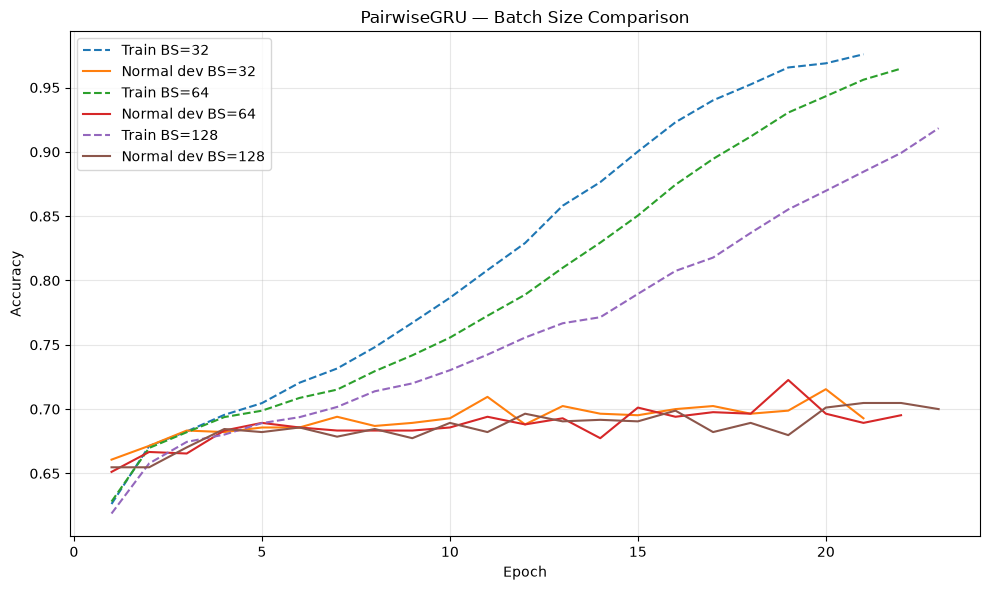

In [10]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for bs in BATCH_SIZES:

    history = batch_history_df[
        batch_history_df["batch_size"] == bs
    ]

    plt.plot(
        history["epoch"],
        history["train_accuracy"],
        linestyle="--",
        label=f"Train BS={bs}"
    )

    plt.plot(
        history["epoch"],
        history["normal_accuracy"],
        label=f"Normal dev BS={bs}"
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("PairwiseGRU — Batch Size Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Batch Size Results

| Batch size | Checkpoint | Normal holdout | Hard holdout |
|---|---|---:|---:|
| 32 | Lowest loss | 68.57% | 66.55% |
| 32 | Highest accuracy | 71.55% | 66.07% |
| 64 | Lowest loss | 68.33% | 68.21% |
| 64 | Highest accuracy | 72.26% | 63.45% |
| 128 | Lowest loss | 68.45% | 65.71% |
| 128 | Highest accuracy | 70.48% | 64.76% |

### Interpretation

Batch size 64 achieved the highest normal-holdout accuracy (72.26%), but its hard-holdout accuracy was considerably lower (63.45%).

In contrast, the lowest-loss checkpoint with batch size 64 achieved nearly identical accuracy on the normal (68.33%) and hard (68.21%) holdouts.

Accuracy-selected checkpoints generally showed larger train-validation gaps and higher validation losses, suggesting overfitting and overconfident predictions.

### Conclusion

Batch size 64 provided the best normal-holdout accuracy and the strongest hard-holdout performance among the lowest-loss checkpoints.

However, higher normal-holdout accuracy did not consistently translate into better robustness.

These findings are based on development experiments only and do not establish improved performance on the official test set.

## Layer Normalization Experiments

We investigate whether Layer Normalization improves PairwiseGRU training stability and generalization.

LayerNorm is applied to the GRU sequence outputs and hidden states using forward hooks. The underlying GRU and shared hypothesis-scoring network remain unchanged.

Training configuration:
- Batch size: 64
- Learning rate: 0.001
- Seed: 42
- Maximum epochs: 60
- Early stopping patience: 15
- Frozen fastText embeddings

We verify hypothesis-swap symmetry and evaluate checkpoints selected by normal-holdout loss and accuracy.

The hard holdout is used only for diagnostic evaluation.

In [11]:
from torch.nn.utils.rnn import PackedSequence

class LayerNormPairwiseGRU(nn.Module):
    """
    Adds post-GRU LayerNorm to the existing PairwiseGRU.

    The original GRU and candidate scorer remain unchanged.
    The same normalization modules are reused whenever
    the shared GRU is called.
    """

    def __init__(self, base_model):
        super().__init__()

        self.base = base_model
        self._hook_handles = []

        grus = [
            (name, module)
            for name, module in self.base.named_modules()
            if isinstance(module, nn.GRU)
        ]

        if not grus:
            raise ValueError(
                "No nn.GRU found in PairwiseGRU."
            )

        for i, (name, gru) in enumerate(grus):

            directions = 2 if gru.bidirectional else 1

            self.add_module(
                f"sequence_norm_{i}",
                nn.LayerNorm(gru.hidden_size * directions)
            )

            self.add_module(
                f"hidden_norm_{i}",
                nn.LayerNorm(gru.hidden_size)
            )

            handle = gru.register_forward_hook(
                lambda module, inputs, outputs, i=i:
                    self._normalize_gru_outputs(outputs, i)
            )

            self._hook_handles.append(handle)

        print("LayerNorm attached to:", [n for n, _ in grus])

    def _normalize_gru_outputs(self, outputs, index):

        sequence, hidden = outputs

        sequence_norm = getattr(
            self, f"sequence_norm_{index}"
        )

        hidden_norm = getattr(
            self, f"hidden_norm_{index}"
        )

        if isinstance(sequence, PackedSequence):

            sequence = PackedSequence(
                sequence_norm(sequence.data),
                sequence.batch_sizes,
                sequence.sorted_indices,
                sequence.unsorted_indices
            )

        else:
            sequence = sequence_norm(sequence)

        hidden = hidden_norm(hidden)

        return sequence, hidden

    def forward(self, *args, **kwargs):
        return self.base(*args, **kwargs)


def create_layernorm_model():

    base_model = create_experiment_model()

    return LayerNormPairwiseGRU(
        base_model
    ).to(device)


# Verify model construction and forward pass
set_seed(42)

ln_model = create_layernorm_model()

sample_loader = create_dataloader(
    normal_dev_data.select(range(16)),
    dev_vocab,
    batch_size=16,
    shuffle=False
)

sample_batch = next(iter(sample_loader))

ln_model.eval()

with torch.no_grad():
    logits = ln_model(
        sample_batch["input_ids"].to(device),
        lengths=sample_batch["lengths"]
    )

assert logits.shape == (16, 2)
assert torch.isfinite(logits).all()
assert not ln_model.base.embedding.weight.requires_grad

print("Forward pass: PASS")
print("Frozen embeddings: PASS")
print(
    "Trainable parameters:",
    sum(p.numel() for p in ln_model.parameters()
        if p.requires_grad)
)

del ln_model
torch.cuda.empty_cache()


LayerNorm attached to: ['gru']
Forward pass: PASS
Frozen embeddings: PASS
Trainable parameters: 281345


In [12]:
set_seed(42)

model = create_layernorm_model()
model.eval()

sample = normal_dev_data.select(range(16))

swapped = sample.map(
    lambda ex: {
        "hypothesis_1": ex["hypothesis_2"],
        "hypothesis_2": ex["hypothesis_1"]
    },
    load_from_cache_file=False
)

original_loader = create_dataloader(
    sample, dev_vocab, batch_size=16, shuffle=False
)

swapped_loader = create_dataloader(
    swapped, dev_vocab, batch_size=16, shuffle=False
)

original_batch = next(iter(original_loader))
swapped_batch = next(iter(swapped_loader))

with torch.inference_mode():

    original_logits = model(
        original_batch["input_ids"].to(device),
        lengths=original_batch["lengths"]
    )

    swapped_logits = model(
        swapped_batch["input_ids"].to(device),
        lengths=swapped_batch["lengths"]
    )

max_difference = (
    original_logits - swapped_logits.flip(dims=[1])
).abs().max().item()

print("Maximum swap difference:", max_difference)

assert torch.allclose(
    original_logits,
    swapped_logits.flip(dims=[1]),
    atol=1e-4,
    rtol=1e-4
), "Hypothesis-swap symmetry failed"

print("Hypothesis-swap symmetry: PASS")

del model
torch.cuda.empty_cache()


LayerNorm attached to: ['gru']


Map: 100%|██████████| 16/16 [00:00<00:00, 268.05 examples/s]


Maximum swap difference: 0.0
Hypothesis-swap symmetry: PASS


In [13]:
import wandb
import pandas as pd
import gc

# ============================================================
# Configuration
# ============================================================

SEED = 42
BATCH_SIZE = 64
LR = 0.001
MAX_EPOCHS = 60
PATIENCE = 15

ln_dir = output_dir / "layernorm"
ln_dir.mkdir(parents=True, exist_ok=True)

set_seed(SEED)

model = create_layernorm_model()

optimizer = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad],
    lr=LR,
    weight_decay=0.0
)

criterion = nn.CrossEntropyLoss()

train_loader = create_dataloader(
    robust_train_data, dev_vocab,
    batch_size=BATCH_SIZE, shuffle=True
)

train_eval_loader = create_dataloader(
    robust_train_data, dev_vocab,
    batch_size=BATCH_SIZE, shuffle=False
)

normal_loader = create_dataloader(
    normal_dev_data, dev_vocab,
    batch_size=BATCH_SIZE, shuffle=False
)

hard_loader = create_dataloader(
    hard_dev_data, dev_vocab,
    batch_size=BATCH_SIZE, shuffle=False
)

steps_per_epoch = len(train_loader)

# ============================================================
# W&B
# ============================================================

run = wandb.init(
    entity="kimbortis-hochschule-luzern",
    project="nlp-art-hs26-project1",
    group="pairwise-layernorm",
    job_type="normalization-experiment",
    name="pairwise_layernorm_bs64_seed42",
    mode="online",
    config={
        "architecture": "PairwiseGRU",
        "layernorm": True,
        "layernorm_position": "post_gru",
        "layernorm_targets": "sequence_and_hidden",
        "hidden_dim": 128,
        "num_layers": 2,
        "dropout": 0.0,
        "batch_size": BATCH_SIZE,
        "learning_rate": LR,
        "weight_decay": 0.0,
        "optimizer": "Adam",
        "seed": SEED,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "train_samples": len(robust_train_data),
        "normal_samples": len(normal_dev_data),
        "hard_samples": len(hard_dev_data),
        "embedding_frozen": True,
        "steps_per_epoch": steps_per_epoch
    }
)

run.define_metric("epoch")
run.define_metric("train/*", step_metric="epoch")
run.define_metric("normal_dev/*", step_metric="epoch")
run.define_metric("generalization/*", step_metric="epoch")

best_loss = float("inf")
best_accuracy = -1.0
best_accuracy_loss = float("inf")

best_loss_epoch = 0
best_accuracy_epoch = 0
no_improvement = 0

loss_path = ln_dir / f"ln_bs64_{run.id}_best_loss.pt"
accuracy_path = ln_dir / f"ln_bs64_{run.id}_best_accuracy.pt"

ln_history = []
ln_results = []

set_seed(SEED + 1)

try:

    # ========================================================
    # Training
    # ========================================================

    for epoch in range(1, MAX_EPOCHS + 1):

        train_metrics = train_one_epoch(
            model, train_loader, optimizer,
            criterion, device
        )

        normal_metrics = evaluate(
            model, normal_loader, criterion, device
        )

        train_acc = float(train_metrics["accuracy"])
        normal_acc = float(normal_metrics["accuracy"])
        normal_loss = float(normal_metrics["loss"])

        gap = train_acc - normal_acc

        run.log({
            "epoch": epoch,
            "train/accuracy": train_acc,
            "train/loss": float(train_metrics["loss"]),
            "normal_dev/accuracy": normal_acc,
            "normal_dev/loss": normal_loss,
            "generalization/train_normal_gap": gap,
            "optimization/optimizer_steps":
                epoch * steps_per_epoch
        })

        ln_history.append({
            "epoch": epoch,
            "train_accuracy": train_acc,
            "normal_accuracy": normal_acc,
            "train_loss": float(train_metrics["loss"]),
            "normal_loss": normal_loss,
            "generalization_gap": gap,
            "optimizer_steps": epoch * steps_per_epoch
        })

        # Best loss checkpoint
        if normal_loss < best_loss:

            best_loss = normal_loss
            best_loss_epoch = epoch
            no_improvement = 0

            torch.save(model.state_dict(), loss_path)

        else:
            no_improvement += 1

        # Best accuracy checkpoint
        if (
            normal_acc > best_accuracy
            or (
                normal_acc == best_accuracy
                and normal_loss < best_accuracy_loss
            )
        ):

            best_accuracy = normal_acc
            best_accuracy_loss = normal_loss
            best_accuracy_epoch = epoch

            torch.save(
                model.state_dict(), accuracy_path
            )

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Epoch {epoch:02d} | "
                f"Train {train_acc:.2%} | "
                f"Normal {normal_acc:.2%} | "
                f"Gap {gap:.2%} | "
                f"Loss {normal_loss:.4f}"
            )

        if no_improvement >= PATIENCE:
            print(f"Early stopping at epoch {epoch}")
            break

    # ========================================================
    # Evaluate saved checkpoints
    # ========================================================

    for selection, path, best_epoch in [
        ("loss", loss_path, best_loss_epoch),
        ("accuracy", accuracy_path, best_accuracy_epoch)
    ]:

        model.load_state_dict(
            torch.load(
                path,
                map_location=device,
                weights_only=True
            )
        )

        train_final = evaluate(
            model, train_eval_loader, criterion, device
        )

        normal_final = evaluate(
            model, normal_loader, criterion, device
        )

        hard_final = evaluate(
            model, hard_loader, criterion, device
        )

        result = {
            "selection": selection,
            "epoch": best_epoch,
            "train_accuracy": float(train_final["accuracy"]),
            "normal_accuracy": float(normal_final["accuracy"]),
            "hard_accuracy": float(hard_final["accuracy"]),
            "normal_loss": float(normal_final["loss"]),
            "hard_loss": float(hard_final["loss"]),
            "train_normal_gap": float(
                train_final["accuracy"]
                - normal_final["accuracy"]
            )
        }

        ln_results.append(result)

        for key, value in result.items():
            if key != "selection":
                run.summary[f"{selection}/{key}"] = value

        print(
            f"\n{selection.upper()} checkpoint | "
            f"Epoch {best_epoch} | "
            f"Train {result['train_accuracy']:.2%} | "
            f"Normal {result['normal_accuracy']:.2%} | "
            f"Hard {result['hard_accuracy']:.2%} | "
            f"Normal loss {result['normal_loss']:.4f}"
        )

    # ========================================================
    # Save to W&B Artifacts
    # ========================================================

    artifact = wandb.Artifact(
        name=f"pairwise-layernorm-bs64-{run.id}",
        type="model",
        metadata={
            "batch_size": BATCH_SIZE,
            "layernorm": True,
            "best_loss_epoch": best_loss_epoch,
            "best_accuracy_epoch": best_accuracy_epoch
        }
    )

    artifact.add_file(
        str(loss_path), name="best_loss.pt"
    )

    artifact.add_file(
        str(accuracy_path), name="best_accuracy.pt"
    )

    run.log_artifact(artifact)

    run.summary["best_normal_dev_loss"] = best_loss
    run.summary["best_normal_dev_accuracy"] = best_accuracy

    print("\nW&B Run:", run.url)

finally:
    run.finish()
    del model, optimizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# Results
# ============================================================

ln_history_df = pd.DataFrame(ln_history)
ln_results_df = pd.DataFrame(ln_results)

ln_history_df.to_csv(
    ln_dir / "layernorm_history.csv",
    index=False
)

ln_results_df.to_csv(
    ln_dir / "layernorm_results.csv",
    index=False
)

display(ln_results_df.round(4))


LayerNorm attached to: ['gru']


Epoch 01 | Train 62.53% | Normal 66.90% | Gap -4.38% | Loss 0.6109
Epoch 05 | Train 69.81% | Normal 67.50% | Gap 2.31% | Loss 0.5842
Epoch 10 | Train 77.08% | Normal 67.86% | Gap 9.23% | Loss 0.5744
Epoch 15 | Train 86.59% | Normal 70.48% | Gap 16.12% | Loss 0.7794
Epoch 20 | Train 95.00% | Normal 69.52% | Gap 25.48% | Loss 1.5357
Epoch 25 | Train 97.97% | Normal 68.93% | Gap 29.04% | Loss 2.7565
Early stopping at epoch 25

LOSS checkpoint | Epoch 10 | Train 80.23% | Normal 67.86% | Hard 67.98% | Normal loss 0.5744

ACCURACY checkpoint | Epoch 13 | Train 85.99% | Normal 70.60% | Hard 69.40% | Normal loss 0.6252

W&B Run: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/650oogmb


epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
generalization/train_normal_gap,▁▂▂▂▂▂▃▃▃▄▄▄▄▅▅▆▆▇▇▇█████
normal_dev/accuracy,▁▂▁▂▂▅▃▅▃▃▅▆█▆█▆█▆▆▆▄▅▇▄▅
normal_dev/loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▃▃▄▄▅▆▆█
optimization/optimizer_steps,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
train/accuracy,▁▂▂▂▂▃▃▃▄▄▄▅▅▅▆▆▆▇▇▇█████
train/loss,█▇▇▇▇▇▇▆▆▆▅▅▅▄▄▃▃▃▂▂▂▁▁▁▁
accuracy/epoch,13
accuracy/hard_accuracy,0.69405
accuracy/hard_loss,0.89821
accuracy/normal_accuracy,0.70595


,selection,epoch,train_accuracy,normal_accuracy,hard_accuracy,normal_loss,hard_loss,train_normal_gap
0,loss,10,0.8023,0.6786,0.6798,0.5744,0.7607,0.1238
1,accuracy,13,0.8599,0.7060,0.6940,0.6252,0.8982,0.1540


### Layer Normalization Results

| Model | Checkpoint | Normal holdout | Hard holdout |
|---|---|---:|---:|
| PairwiseGRU | Lowest loss | 68.33% | 68.21% |
| PairwiseGRU + LayerNorm | Lowest loss | 67.86% | 67.98% |
| PairwiseGRU | Highest accuracy | 72.26% | 63.45% |
| PairwiseGRU + LayerNorm | Highest accuracy | 70.60% | 69.40% |

### Interpretation

LayerNorm did not improve normal-holdout accuracy.

However, the accuracy-selected LayerNorm checkpoint achieved 69.40% on the hard holdout, compared with 63.45% without LayerNorm.

The normal-to-hard accuracy gap decreased from 8.81 to 1.19 percentage points.

LayerNorm also preserved hypothesis-swap symmetry, with a maximum score difference of 0.0 in the architectural test.

### Conclusion

LayerNorm reduced normal-holdout accuracy but improved hard-holdout performance for the accuracy-selected checkpoint.

This suggests a potential robustness benefit for low-similarity hypotheses.

However, the improvement is based on a single seed and development holdouts. It does not establish better generalization to the official test set.

## Similarity-Based Sampling Experiments

We investigate whether increasing the frequency of low-similarity training examples improves PairwiseGRU robustness.

We compare two sampling strategies:
- Uniform sampling with replacement
- Weighted sampling with 3× higher probability for examples with Jaccard similarity ≤ 0.20

Low-similarity examples represent 4.13% of the development-training data. Weighting increases their expected sampling frequency to 11.45%.

Both experiments use the same architecture, batch size (64), learning rate (0.001), and seed (42).

Checkpoints are selected using the normal holdout. The hard holdout is used for diagnostic evaluation.

In [14]:
import numpy as np
import torch
from torch.utils.data import DataLoader, Subset

BATCH_SIZE = 64
SEED = 42
LOW_SIM_THRESHOLD = 0.20
LOW_SIM_MULTIPLIER = 3.0

# Similarities from development training ONLY
train_similarity = np.array([
    similarity(row) for row in robust_train_data
])

low_mask = train_similarity <= LOW_SIM_THRESHOLD
train_h1_labels = np.array(robust_train_data["label"])

natural_low_rate = low_mask.mean()

weighted_low_rate = (
    LOW_SIM_MULTIPLIER * low_mask.sum()
    / (
        LOW_SIM_MULTIPLIER * low_mask.sum()
        + (~low_mask).sum()
    )
)

print(f"Training samples: {len(train_similarity):,}")
print(f"Low similarity: {low_mask.sum():,}")
print(f"Natural low-similarity fraction: {natural_low_rate:.2%}")
print(f"Expected fraction with 3x weighting: {weighted_low_rate:.2%}")

print(
    "H1 proportion, low similarity:",
    f"{(train_h1_labels[low_mask] == 1).mean():.2%}"
)
print(
    "H1 proportion, other examples:",
    f"{(train_h1_labels[~low_mask] == 1).mean():.2%}"
)

# Reuse existing encoded dataset and collation
base_train_loader = create_dataloader(
    robust_train_data,
    dev_vocab,
    batch_size=BATCH_SIZE,
    shuffle=False
)

assert len(base_train_loader.dataset) == len(robust_train_data)

# Check encoded example ordering
for i in range(min(20, len(robust_train_data))):
    assert (
        int(base_train_loader.dataset[i]["label"])
        == int(robust_train_data[i]["label"]) - 1
    )

print("Encoded dataset order: PASS")


Training samples: 15,121
Low similarity: 625
Natural low-similarity fraction: 4.13%
Expected fraction with 3x weighting: 11.45%
H1 proportion, low similarity: 50.88%
H1 proportion, other examples: 50.30%
Encoded dataset order: PASS


In [15]:

import gc
import pandas as pd
import torch.nn as nn
import wandb

from project1.src.training import train_one_epoch, evaluate

# ============================================================
# 1. Configurations
# ============================================================

SAMPLING_EXPERIMENTS = {
    "uniform_replacement": 1.0,
    "low_similarity_x3": 3.0,
}

MAX_EPOCHS = 60
PATIENCE = 15
LEARNING_RATE = 0.001

sampling_dir = output_dir / "similarity_sampling"
sampling_dir.mkdir(parents=True, exist_ok=True)

sampling_history = []
sampling_results = []

normal_loader = create_dataloader(
    normal_dev_data, dev_vocab,
    batch_size=BATCH_SIZE, shuffle=False
)

hard_loader = create_dataloader(
    hard_dev_data, dev_vocab,
    batch_size=BATCH_SIZE, shuffle=False
)

train_eval_loader = create_dataloader(
    robust_train_data, dev_vocab,
    batch_size=BATCH_SIZE, shuffle=False
)

criterion = nn.CrossEntropyLoss()

# ============================================================
# 2. Run experiments
# ============================================================

for sampling_name, low_multiplier in SAMPLING_EXPERIMENTS.items():

    set_seed(SEED)

    # Original PairwiseGRU - NO LayerNorm
    model = create_experiment_model()

    optimizer = torch.optim.Adam(
        (p for p in model.parameters() if p.requires_grad),
        lr=LEARNING_RATE,
        weight_decay=0.0
    )

    example_weights = torch.tensor(
        np.where(low_mask, low_multiplier, 1.0),
        dtype=torch.double
    )

    expected_low_fraction = (
        low_multiplier * low_mask.sum()
        / (
            low_multiplier * low_mask.sum()
            + (~low_mask).sum()
        )
    )

    # Independent generator for reproducible sampling
    sample_generator = torch.Generator().manual_seed(
        SEED + 1
    )

    # ========================================================
    # 3. W&B setup
    # ========================================================

    run = wandb.init(
        entity=WANDB_ENTITY,
        project=WANDB_PROJECT,
        group="pairwise-similarity-sampling",
        job_type="controlled-sampling-experiment",
        name=f"pairwise_{sampling_name}_bs{BATCH_SIZE}_seed{SEED}",
        mode="online",
        config={
            "architecture": "PairwiseGRU",
            "layernorm": False,
            "hidden_dim": 128,
            "num_layers": 2,
            "dropout": 0.0,
            "learning_rate": LEARNING_RATE,
            "weight_decay": 0.0,
            "batch_size": BATCH_SIZE,
            "seed": SEED,
            "max_epochs": MAX_EPOCHS,
            "patience": PATIENCE,
            "sampling": sampling_name,
            "sampling_with_replacement": True,
            "low_similarity_threshold": LOW_SIM_THRESHOLD,
            "low_similarity_multiplier": low_multiplier,
            "natural_low_similarity_fraction": float(natural_low_rate),
            "expected_low_similarity_fraction": float(expected_low_fraction),
            "samples_drawn_per_epoch": len(robust_train_data),
            "vocabulary_size": len(dev_vocab),
            "frozen_fasttext": True,
            "checkpoint_selection": "normal_dev_only"
        }
    )

    run.define_metric("epoch")

    for prefix in [
        "train/*",
        "normal_dev/*",
        "sampling/*",
        "generalization/*"
    ]:
        run.define_metric(prefix, step_metric="epoch")

    loss_path = (
        sampling_dir /
        f"{sampling_name}_{run.id}_best_loss.pt"
    )

    acc_path = (
        sampling_dir /
        f"{sampling_name}_{run.id}_best_accuracy.pt"
    )

    best_loss = float("inf")
    best_acc = -1.0
    acc_tie_loss = float("inf")

    best_loss_epoch = 0
    best_acc_epoch = 0
    patience_count = 0

    set_seed(SEED + 1)

    try:

        # ====================================================
        # 4. Training loop
        # ====================================================

        for epoch in range(1, MAX_EPOCHS + 1):

            # Draw same number of examples each epoch.
            # Only the probability weights differ.
            sampled_indices = torch.multinomial(
                example_weights,
                num_samples=len(robust_train_data),
                replacement=True,
                generator=sample_generator
            ).tolist()

            sampled_indices_np = np.asarray(
                sampled_indices, dtype=np.int64
            )

            # Reuse existing encoded examples
            epoch_loader = DataLoader(
                Subset(
                    base_train_loader.dataset,
                    sampled_indices
                ),
                batch_size=BATCH_SIZE,
                shuffle=False,
                collate_fn=base_train_loader.collate_fn,
                num_workers=base_train_loader.num_workers,
                pin_memory=base_train_loader.pin_memory
            )

            train_stats = train_one_epoch(
                model,
                epoch_loader,
                optimizer,
                criterion,
                device
            )

            normal_stats = evaluate(
                model,
                normal_loader,
                criterion,
                device
            )

            train_acc = float(train_stats["accuracy"])
            normal_acc = float(normal_stats["accuracy"])
            normal_loss = float(normal_stats["loss"])

            actual_low_fraction = float(
                low_mask[sampled_indices_np].mean()
            )

            unique_fraction = (
                len(set(sampled_indices))
                / len(sampled_indices)
            )

            # ================================================
            # 5. Log metrics
            # ================================================

            run.log({
                "epoch": epoch,

                "train/accuracy": train_acc,
                "train/loss": float(train_stats["loss"]),

                "normal_dev/accuracy": normal_acc,
                "normal_dev/loss": normal_loss,

                "generalization/sample_train_normal_gap":
                    train_acc - normal_acc,

                "sampling/low_fraction": actual_low_fraction,

                "sampling/mean_similarity": float(
                    train_similarity[sampled_indices_np].mean()
                ),

                "sampling/unique_fraction": unique_fraction,

                "sampling/h1_fraction": float(
                    (train_h1_labels[sampled_indices_np] == 1).mean()
                ),

                "sampling/optimizer_steps": (
                    epoch * len(epoch_loader)
                )
            })

            sampling_history.append({
                "sampling": sampling_name,
                "epoch": epoch,
                "train_accuracy": train_acc,
                "normal_accuracy": normal_acc,
                "normal_loss": normal_loss,
                "low_fraction": actual_low_fraction,
                "unique_fraction": unique_fraction
            })

            # ================================================
            # 6. Checkpoint selection
            # ================================================

            if normal_loss < best_loss:

                best_loss = normal_loss
                best_loss_epoch = epoch
                patience_count = 0

                torch.save(model.state_dict(), loss_path)

            else:
                patience_count += 1

            if (
                normal_acc > best_acc
                or (
                    normal_acc == best_acc
                    and normal_loss < acc_tie_loss
                )
            ):

                best_acc = normal_acc
                acc_tie_loss = normal_loss
                best_acc_epoch = epoch

                torch.save(model.state_dict(), acc_path)

            if epoch == 1 or epoch % 5 == 0:

                print(
                    f"{sampling_name} | Epoch {epoch:02d} | "
                    f"Train {train_acc:.2%} | "
                    f"Normal {normal_acc:.2%} | "
                    f"Loss {normal_loss:.4f} | "
                    f"Low-sim {actual_low_fraction:.1%}"
                )

            if patience_count >= PATIENCE:

                print(f"Early stopping at epoch {epoch}")
                break

        # ====================================================
        # 7. Evaluate saved checkpoints
        # ====================================================

        for selection, path, selected_epoch in [
            ("loss", loss_path, best_loss_epoch),
            ("accuracy", acc_path, best_acc_epoch)
        ]:

            model.load_state_dict(
                torch.load(
                    path,
                    map_location=device,
                    weights_only=True
                ),
                strict=True
            )

            # Full, unweighted development training set
            train_final = evaluate(
                model, train_eval_loader, criterion, device
            )

            normal_final = evaluate(
                model, normal_loader, criterion, device
            )

            # Diagnostic only - not used for selection
            hard_final = evaluate(
                model, hard_loader, criterion, device
            )

            result = {
                "sampling": sampling_name,
                "selection": selection,
                "epoch": selected_epoch,
                "train_accuracy": float(train_final["accuracy"]),
                "normal_accuracy": float(normal_final["accuracy"]),
                "hard_accuracy": float(hard_final["accuracy"]),
                "normal_loss": float(normal_final["loss"]),
                "hard_loss": float(hard_final["loss"]),
                "train_normal_gap": float(
                    train_final["accuracy"]
                    - normal_final["accuracy"]
                ),
                "run_id": run.id
            }

            sampling_results.append(result)

            for key, value in result.items():
                if key not in {"sampling", "selection", "run_id"}:
                    run.summary[f"{selection}/{key}"] = value

            print(
                f"\n{sampling_name} / {selection.upper()} | "
                f"Epoch {selected_epoch} | "
                f"Normal {result['normal_accuracy']:.2%} | "
                f"Hard {result['hard_accuracy']:.2%} | "
                f"Loss {result['normal_loss']:.4f}"
            )

        # ====================================================
        # 8. W&B checkpoints
        # ====================================================

        artifact = wandb.Artifact(
            name=f"pairwise-sampling-{sampling_name}-{run.id}",
            type="model"
        )

        artifact.add_file(
            str(loss_path),
            name="best_loss.pt"
        )

        artifact.add_file(
            str(acc_path),
            name="best_accuracy.pt"
        )

        run.log_artifact(artifact)

        run.summary["epochs_trained"] = epoch
        run.summary["best_normal_dev_loss"] = best_loss
        run.summary["best_normal_dev_accuracy"] = best_acc

        print("\nW&B:", run.url)

    finally:

        run.finish()

        del model, optimizer
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# ============================================================
# 9. Save comparison
# ============================================================

sampling_history_df = pd.DataFrame(sampling_history)
sampling_results_df = pd.DataFrame(sampling_results)

sampling_history_df.to_csv(
    sampling_dir / "sampling_history.csv",
    index=False
)

sampling_results_df.to_csv(
    sampling_dir / "sampling_results.csv",
    index=False
)

print("\n=== SIMILARITY SAMPLING COMPARISON ===")

display(sampling_results_df.round(4))


uniform_replacement | Epoch 01 | Train 64.23% | Normal 65.95% | Loss 0.6106 | Low-sim 4.0%
uniform_replacement | Epoch 05 | Train 70.99% | Normal 68.21% | Loss 0.5887 | Low-sim 4.3%


Failed to export metrics batch due to timeout, max retries or shutdown.


uniform_replacement | Epoch 10 | Train 77.24% | Normal 66.55% | Loss 0.6707 | Low-sim 4.3%
uniform_replacement | Epoch 15 | Train 86.22% | Normal 68.45% | Loss 0.8643 | Low-sim 4.0%
uniform_replacement | Epoch 20 | Train 93.37% | Normal 68.10% | Loss 1.2710 | Low-sim 4.3%
Early stopping at epoch 22

uniform_replacement / LOSS | Epoch 7 | Normal 67.02% | Hard 67.38% | Loss 0.5823

uniform_replacement / ACCURACY | Epoch 13 | Normal 69.76% | Hard 66.79% | Loss 0.7031

W&B: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/q6brq5m9


epoch,▁▁▂▂▂▃▃▃▄▄▄▅▅▅▆▆▆▇▇▇██
generalization/sample_train_normal_gap,▁▂▁▂▂▃▃▃▃▄▄▄▄▅▆▆▇▇▇███
normal_dev/accuracy,▁▁▆▆▅▄▃▄▂▂▇▆█▇▆▆▅▅▅▅▅▇
normal_dev/loss,▁▁▁▁▁▁▁▁▁▂▁▁▂▂▃▃▄▄▅▅██
sampling/h1_fraction,█▇▆█▅▂▄▆▂▄▃▄▆▆▃▇▆▆▁▆█▂
sampling/low_fraction,▃▂▇▁▇▁▆▃▄▇▄▄▄▄▄▇██▅▇▆▇
sampling/mean_similarity,▄█▆▇▁▆▇▄▅▄▇▅▂▅▆▄▂▂▄▁▁▂
sampling/optimizer_steps,▁▁▂▂▂▃▃▃▄▄▄▅▅▅▆▆▆▇▇▇██
sampling/unique_fraction,▄▃▂▆▁▂▆▄▄▂▂▃▃▁▃▅█▄█▂▄█
train/accuracy,▁▂▂▂▃▃▃▃▃▄▄▄▅▅▆▆▇▇▇▇██
+1,...


low_similarity_x3 | Epoch 01 | Train 63.43% | Normal 65.71% | Loss 0.6195 | Low-sim 11.5%
low_similarity_x3 | Epoch 05 | Train 70.89% | Normal 68.21% | Loss 0.5879 | Low-sim 11.9%
low_similarity_x3 | Epoch 10 | Train 78.19% | Normal 66.90% | Loss 0.6453 | Low-sim 11.2%
low_similarity_x3 | Epoch 15 | Train 87.65% | Normal 67.62% | Loss 0.8971 | Low-sim 12.0%
low_similarity_x3 | Epoch 20 | Train 94.03% | Normal 67.26% | Loss 1.4101 | Low-sim 11.5%
Early stopping at epoch 21

low_similarity_x3 / LOSS | Epoch 6 | Normal 68.45% | Hard 68.93% | Loss 0.5814

low_similarity_x3 / ACCURACY | Epoch 6 | Normal 68.45% | Hard 68.93% | Loss 0.5814

W&B: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/h9krs7uq


epoch,▁▁▂▂▂▃▃▃▄▄▅▅▅▆▆▆▇▇▇██
generalization/sample_train_normal_gap,▁▁▂▂▂▂▃▄▃▄▄▅▅▆▆▆▇▇███
normal_dev/accuracy,▁▆▄█▇█▅▃▆▄▆█▃▄▆▆▆▅▅▅▆
normal_dev/loss,▁▁▁▁▁▁▁▁▁▁▁▂▂▂▃▄▄▅▆▇█
sampling/h1_fraction,▃▂▁▃▁█▂▂▇▄▅▃█▇▃▂▇▄▄▄▆
sampling/low_fraction,▄▄▄▅▇▆▄▂▃▂▂▆▄▃█▃▂▆█▄▁
sampling/mean_similarity,▅▅▅▄▂▄▆▇▇██▄▆▄▂▆█▄▁▂█
sampling/optimizer_steps,▁▁▂▂▂▃▃▃▄▄▅▅▅▆▆▆▇▇▇██
sampling/unique_fraction,▅▃▃▅▁▃▃█▃▄▃▂▂▃▁▃▆▂▂▅▅
train/accuracy,▁▂▂▂▃▃▃▄▄▄▅▅▅▆▆▇▇▇███
+1,...



=== SIMILARITY SAMPLING COMPARISON ===


,sampling,selection,epoch,train_accuracy,normal_accuracy,hard_accuracy,normal_loss,hard_loss,train_normal_gap,run_id
0,uniform_replacement,loss,7,0.7390,0.6702,0.6738,0.5823,0.6726,0.0688,q6brq5m9
1,uniform_replacement,accuracy,13,0.8304,0.6976,0.6679,0.7031,1.1268,0.1328,q6brq5m9
2,low_similarity_x3,loss,6,0.7195,0.6845,0.6893,0.5814,0.6692,0.0350,h9krs7uq
3,low_similarity_x3,accuracy,6,0.7195,0.6845,0.6893,0.5814,0.6692,0.0350,h9krs7uq


### Similarity-Based Sampling Results

| Sampling | Checkpoint | Normal holdout | Hard holdout |
|---|---|---:|---:|
| Uniform | Lowest loss | 67.02% | 67.38% |
| Uniform | Highest accuracy | 69.76% | 66.79% |
| Low-similarity ×3 | Lowest loss | 68.45% | 68.93% |
| Low-similarity ×3 | Highest accuracy | 68.45% | 68.93% |

### Interpretation

Weighted sampling increased the expected proportion of low-similarity examples from 4.13% to 11.45%.

Compared with uniform sampling:
- Hard-holdout accuracy improved by 1.55 percentage points for the lowest-loss checkpoints.
- Hard-holdout accuracy improved by 2.14 percentage points for the highest-accuracy checkpoints.
- The weighted experiment selected the same checkpoint (epoch 6) for both loss and accuracy.

However, the weighted model's highest normal-holdout accuracy (68.45%) was lower than the uniform model's (69.76%).

### Conclusion

Similarity-weighted sampling improved performance on the low-similarity hard holdout in this experiment, but did not improve the highest normal-holdout accuracy.

This suggests a possible robustness benefit from emphasizing underrepresented low-similarity examples.

The experiment uses only one random seed and development data, so the results do not establish improved official test performance.

## Checkpoint Comparison and Generalization Evaluation

We compare the original GRU and PairwiseGRU against five experimental PairwiseGRU checkpoints.

The experimental checkpoints were selected using development data, based on validation accuracy or loss.

We evaluate:
- Test accuracy and cross-entropy loss
- Macro-F1
- Accuracy differences relative to the original GRU

The original models use the full training vocabulary, while the experimental models use the development-only vocabulary.

**Important:** Since the official test set was already evaluated in Notebook 06, this comparison is exploratory. Test results are not used for additional training or checkpoint selection.

In [16]:

from pathlib import Path
import torch
import pandas as pd
import wandb
import gc

# Existing notebook variables:
# artifact_dir, output_dir, vocab, dev_vocab
# create_gru, create_pairwise
# create_experiment_model, create_layernorm_model

# ------------------------------------------------------------
# Checkpoints chosen BEFORE evaluating the test set
# ------------------------------------------------------------

candidates = {
    "Original GRU": {
        "factory": create_gru,
        "vocab": vocab,
        "path": artifact_dir /
            "gru_multiseed_h128_lr0p001_drop0p0_seed42_cuda_hvxtunb8_best.pt",
        "normal_dev_accuracy": None,
        "training_split": "original_full_train"
    },

    "Original PairwiseGRU": {
        "factory": create_pairwise,
        "vocab": vocab,
        "path": artifact_dir /
            "pairwise_gru_h128_l2_lr0p001_drop0p0_seed42_cuda_z6d879wl_best.pt",
        "normal_dev_accuracy": None,
        "training_split": "original_full_train"
    },

    "Pairwise BS32": {
        "factory": create_experiment_model,
        "vocab": dev_vocab,
        "path": output_dir / "batch_size" /
            "pairwise_bs32_seed42_tpsul1y0_best_accuracy.pt",
        "normal_dev_accuracy": 0.7155,
        "training_split": "development_train"
    },

    "Pairwise BS64": {
        "factory": create_experiment_model,
        "vocab": dev_vocab,
        "path": output_dir / "batch_size" /
            "pairwise_bs64_seed42_zcn6599h_best_accuracy.pt",
        "normal_dev_accuracy": 0.7226,
        "training_split": "development_train"
    },

    "Pairwise BS64 Best Loss": {
        "factory": create_experiment_model,
        "vocab": dev_vocab,
        "path": output_dir / "batch_size" /
            "pairwise_bs64_seed42_zcn6599h_best_loss.pt",
        "normal_dev_accuracy": 0.6833,
        "training_split": "development_train"
    },

    "Pairwise LayerNorm BS64": {
        "factory": create_layernorm_model,
        "vocab": dev_vocab,
        "path": output_dir / "layernorm" /
            "ln_bs64_650oogmb_best_accuracy.pt",
        "normal_dev_accuracy": 0.7060,
        "training_split": "development_train"
    },

    "Pairwise Similarity x3": {
        "factory": create_experiment_model,
        "vocab": dev_vocab,
        "path": output_dir / "similarity_sampling" /
            "low_similarity_x3_h9krs7uq_best_accuracy.pt",
        "normal_dev_accuracy": 0.6845,
        "training_split": "development_train"
    }
}

# ------------------------------------------------------------
# Verify every checkpoint exists
# ------------------------------------------------------------

for name, cfg in candidates.items():
    path = cfg["path"]

    assert path.is_file(), (
        f"Checkpoint missing for {name}:\n{path}"
    )

    print(f"PASS: {name}")

print(f"\n{len(candidates)} checkpoints ready.")


PASS: Original GRU
PASS: Original PairwiseGRU
PASS: Pairwise BS32
PASS: Pairwise BS64
PASS: Pairwise BS64 Best Loss
PASS: Pairwise LayerNorm BS64
PASS: Pairwise Similarity x3

7 checkpoints ready.


In [17]:

import torch.nn.functional as F
from datasets import load_dataset
from project1.src.data_loader import create_dataloader

# ============================================================
# 1. Official test dataset
# ============================================================

test_data = load_dataset(
    "amarfurt/art-nlp-hs26",
    split="test"
)

assert "label" in test_data.column_names
assert set(test_data["label"]) == {1, 2}

print("Test samples:", len(test_data))

# Separate loaders because the original and new models
# use DIFFERENT vocabularies.
test_loader_original = create_dataloader(
    test_data, vocab,
    batch_size=64, shuffle=False
)

test_loader_development = create_dataloader(
    test_data, dev_vocab,
    batch_size=64, shuffle=False
)


# ============================================================
# 2. Test evaluation function
# ============================================================

@torch.inference_mode()
def evaluate_on_test(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    total_loss = 0.0
    total_count = 0

    for batch in loader:

        input_ids = batch["input_ids"].to(device)
        labels = batch["labels"].to(device)

        logits = model(
            input_ids,
            lengths=batch["lengths"]
        )

        preds = logits.argmax(dim=1)

        total_loss += F.cross_entropy(
            logits, labels,
            reduction="sum"
        ).item()

        total_count += len(labels)

        all_preds.append(preds.cpu())
        all_labels.append(labels.cpu())

    y_pred = torch.cat(all_preds)
    y_true = torch.cat(all_labels)

    # Ensure examples were not reordered
    expected = (
        torch.tensor(test_data["label"]) - 1
    )

    assert torch.equal(y_true, expected)

    accuracy = (
        (y_pred == y_true).float().mean().item()
    )

    confusion = torch.bincount(
        y_true * 2 + y_pred,
        minlength=4
    ).reshape(2, 2)

    correct = confusion.diag().float()

    precision = (
        correct / confusion.sum(dim=0).clamp(min=1)
    )

    recall = (
        correct / confusion.sum(dim=1).clamp(min=1)
    )

    f1 = (
        2 * precision * recall
        / (precision + recall).clamp(min=1e-12)
    )

    return {
        "test_accuracy": accuracy,
        "test_loss": total_loss / total_count,
        "balanced_accuracy": recall.mean().item(),
        "macro_f1": f1.mean().item(),
        "h1_recall": recall[0].item(),
        "h2_recall": recall[1].item()
    }


# ============================================================
# 3. Start W&B evaluation run
# ============================================================

run = wandb.init(
    entity=WANDB_ENTITY,
    project=WANDB_PROJECT,
    group="07-test-comparison",
    job_type="evaluation",
    name="selected_checkpoints_test_comparison",
    mode="online",
    config={
        "experiment": "generalization_07",
        "test_dataset": "amarfurt/art-nlp-hs26",
        "test_split": "test",
        "checkpoint_selection": "development_only",
        "models": list(candidates.keys()),
        "training": False,
        "seed": 42,
        "exploratory_repeated_test": True
    }
)

results = []

try:

    # ========================================================
    # 4. Evaluate every checkpoint
    # ========================================================

    for name, cfg in candidates.items():

        print(f"\n{'=' * 60}")
        print("Evaluating:", name)
        print(f"{'=' * 60}")

        model = cfg["factory"]()

        state = torch.load(
            cfg["path"],
            map_location=device,
            weights_only=True
        )

        model.load_state_dict(
            state,
            strict=True
        )

        model.eval()

        # Check frozen embeddings
        embedding_params = [
            p for n, p in model.named_parameters()
            if "embedding.weight" in n
        ]

        assert embedding_params
        assert all(
            not p.requires_grad
            for p in embedding_params
        )

        if cfg["vocab"] is vocab:
            loader = test_loader_original
        else:
            loader = test_loader_development

        metrics = evaluate_on_test(
            model, loader
        )

        row = {
            "model": name,
            "training_split": cfg["training_split"],
            "normal_dev_accuracy":
                cfg["normal_dev_accuracy"],
            **metrics
        }

        results.append(row)

        print(
            f"Test accuracy: "
            f"{metrics['test_accuracy']:.2%}"
        )
        print(
            f"Test loss: "
            f"{metrics['test_loss']:.4f}"
        )
        print(
            f"Macro F1: "
            f"{metrics['macro_f1']:.4f}"
        )

        # Store results in W&B summary
        for key, value in metrics.items():
            run.summary[f"{name}/{key}"] = value

        del model
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # ========================================================
    # 5. Compare against original model
    # ========================================================

    results_df = pd.DataFrame(results)

    original_gru_accuracy = results_df.loc[
        results_df["model"] == "Original GRU",
        "test_accuracy"
    ].iloc[0]

    original_pairwise_accuracy = results_df.loc[
        results_df["model"] == "Original PairwiseGRU",
        "test_accuracy"
    ].iloc[0]

    results_df["delta_vs_original_gru_pp"] = (
        results_df["test_accuracy"]
        - original_gru_accuracy
    ) * 100

    results_df["delta_vs_original_pairwise_pp"] = (
        results_df["test_accuracy"]
        - original_pairwise_accuracy
    ) * 100

    # Sort only for reporting, not further tuning
    results_df = results_df.sort_values(
        "test_accuracy",
        ascending=False
    ).reset_index(drop=True)

    # ========================================================
    # 6. Save and log comparison
    # ========================================================

    results_path = (
        output_dir / "selected_models_test_comparison.csv"
    )

    results_df.to_csv(
        results_path,
        index=False
    )

    run.log({
        "test/comparison": wandb.Table(
            dataframe=results_df
        )
    })

    run.summary["test_samples"] = len(test_data)
    run.summary["models_evaluated"] = len(candidates)
    run.summary["baseline_original_gru"] = (
        original_gru_accuracy
    )
    run.summary["baseline_original_pairwise"] = (
        original_pairwise_accuracy
    )

    print("\n=== TEST COMPARISON ===")

    display(
        results_df[[
            "model",
            "normal_dev_accuracy",
            "test_accuracy",
            "test_loss",
            "macro_f1",
            "delta_vs_original_gru_pp"
        ]].round(4)
    )

    print("\nSaved:", results_path)
    print("W&B:", run.url)

finally:
    run.finish()


Test samples: 1532



Evaluating: Original GRU
Test accuracy: 54.05%
Test loss: 0.9039
Macro F1: 0.5404

Evaluating: Original PairwiseGRU
Test accuracy: 53.98%
Test loss: 1.2057
Macro F1: 0.5398

Evaluating: Pairwise BS32
Test accuracy: 52.81%
Test loss: 5.6399
Macro F1: 0.5279

Evaluating: Pairwise BS64
Test accuracy: 53.26%
Test loss: 3.3926
Macro F1: 0.5325

Evaluating: Pairwise BS64 Best Loss
Test accuracy: 52.55%
Test loss: 0.8794
Macro F1: 0.5254

Evaluating: Pairwise LayerNorm BS64
LayerNorm attached to: ['gru']
Test accuracy: 53.59%
Test loss: 1.4109
Macro F1: 0.5358

Evaluating: Pairwise Similarity x3
Test accuracy: 54.31%
Test loss: 0.9657
Macro F1: 0.5429

=== TEST COMPARISON ===


,model,normal_dev_accuracy,test_accuracy,test_loss,macro_f1,delta_vs_original_gru_pp
0,Pairwise Similarity x3,0.6845,0.5431,0.9657,0.5429,0.2611
1,Original GRU,NaN,0.5405,0.9039,0.5404,0.0000
2,Original PairwiseGRU,NaN,0.5398,1.2057,0.5398,-0.0653
3,Pairwise LayerNorm BS64,0.7060,0.5359,1.4109,0.5358,-0.4569
4,Pairwise BS64,0.7226,0.5326,3.3926,0.5325,-0.7833
5,Pairwise BS32,0.7155,0.5281,5.6399,0.5279,-1.2402
6,Pairwise BS64 Best Loss,0.6833,0.5255,0.8794,0.5254,-1.5013



Saved: C:\Users\kimbo\Documents\HSLU\Sem 5\NLP\nlp-art-hs26-kim\project1\artifacts\generalization_07\selected_models_test_comparison.csv
W&B: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/wuzghe2e


Original GRU/balanced_accuracy,0.54091
Original GRU/h1_recall,0.51857
Original GRU/h2_recall,0.56325
Original GRU/macro_f1,0.54041
Original GRU/test_accuracy,0.54047
Original GRU/test_loss,0.90394
Original PairwiseGRU/balanced_accuracy,0.53983
Original PairwiseGRU/h1_recall,0.53905
Original PairwiseGRU/h2_recall,0.54061
Original PairwiseGRU/macro_f1,0.53977
+36,...


### Checkpoint Comparison Results

| Model | Normal holdout | Test accuracy |
|---|---:|---:|
| Original GRU | — | 54.05% |
| Original PairwiseGRU | — | 53.98% |
| Pairwise BS32 | 71.55% | 52.81% |
| Pairwise BS64 | 72.26% | 53.26% |
| Pairwise BS64 (lowest loss) | 68.33% | 52.55% |
| Pairwise LayerNorm BS64 | 70.60% | 53.59% |
| Pairwise Similarity ×3 | 68.45% | 54.31% |

### Interpretation

The similarity-weighted PairwiseGRU achieved the highest observed test accuracy (54.31%), exceeding the original GRU by only 0.26 percentage points.

However, this difference is very small and does not establish a meaningful improvement.

The PairwiseGRU with batch size 64 achieved the highest normal-holdout accuracy (72.26%) but only 53.26% on the test set.

This demonstrates that higher development accuracy does not necessarily translate into better test performance.

The original models and experimental models were trained on different training subsets and vocabularies, which limits direct comparisons.

### Conclusion

Similarity-weighted sampling showed promising exploratory results, but none of the experiments demonstrated a convincing improvement over the original GRU.

The substantial generalization gap remains unresolved.

Because the official test set has been examined repeatedly, these results should be treated as exploratory rather than an independent final evaluation.

## Additional Generalization Diagnostics — Dataset Shift and Dropout

We extend the analysis with additional development experiments:

- Compare hypothesis similarity, vocabulary coverage, and label balance across dataset splits.
- Compare MLP dropout (0.2 versus 0.4) and GRU dropout (0.0 versus 0.2).
- Repeat the dropout experiments across seeds 42, 43, and 44.
- Diagnose prediction collapse in an unstable GRU run.
- Compare the resulting checkpoints on the official test set.

The models are trained using the isolated development-training subset, and checkpoints are selected using the normal holdout.

Official test comparisons are exploratory because the test set has already been examined.

In [18]:

import numpy as np
import pandas as pd

# Compare all dataset splits
datasets_to_compare = {
    "Development train": robust_train_data,
    "Normal holdout": normal_dev_data,
    "Hard holdout": hard_dev_data,
    "Official test": test_data
}

def dataset_statistics(name, dataset):

    similarities = []
    hypothesis_lengths = []
    unknown_counts = []
    token_counts = []

    for example in dataset:

        # Hypothesis similarity
        similarities.append(similarity(example))

        h1 = tokenize(example["hypothesis_1"])
        h2 = tokenize(example["hypothesis_2"])

        hypothesis_lengths.append(
            (len(h1) + len(h2)) / 2
        )

        # OOV coverage across all model input fields
        all_tokens = []

        for field in FIELDS:
            all_tokens.extend(tokenize(example[field]))

        unknown_counts.append(
            sum(token not in dev_vocab for token in all_tokens)
        )

        token_counts.append(len(all_tokens))

    similarities = np.asarray(similarities)
    hypothesis_lengths = np.asarray(hypothesis_lengths)

    labels = np.asarray(dataset["label"])

    return {
        "split": name,
        "samples": len(dataset),
        "mean_similarity": similarities.mean(),
        "median_similarity": np.median(similarities),
        "low_similarity_pct": (
            similarities <= 0.2
        ).mean() * 100,
        "mean_hypothesis_length": hypothesis_lengths.mean(),
        "oov_token_pct": (
            sum(unknown_counts)
            / max(sum(token_counts), 1)
        ) * 100,
        "h1_label_pct": (labels == 1).mean() * 100
    }


distribution_df = pd.DataFrame([
    dataset_statistics(name, dataset)
    for name, dataset in datasets_to_compare.items()
])

print("=== DATASET DISTRIBUTION COMPARISON ===")

display(distribution_df.round(3))

distribution_df.to_csv(
    output_dir / "dataset_distribution_comparison.csv",
    index=False
)


=== DATASET DISTRIBUTION COMPARISON ===


,split,samples,mean_similarity,median_similarity,low_similarity_pct,mean_hypothesis_length,oov_token_pct,h1_label_pct
0,Development train,15121,0.623,0.667,4.133,9.641,0.380,50.327
1,Normal holdout,840,0.657,0.667,0.000,9.942,1.700,52.143
2,Hard holdout,840,0.160,0.167,75.833,9.099,1.595,49.167
3,Official test,1532,0.225,0.167,61.554,9.848,1.742,50.979


In [19]:

from project1.src.models import EmbeddingMLP, EmbeddingGRU
from project1.src.training import train_one_epoch, evaluate

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import wandb
import gc

# Use the existing isolated development vocabulary
assert len(robust_train_data) == 15121
assert len(normal_dev_data) == 840
assert len(hard_dev_data) == 840

SEED = 42
BATCH_SIZE = 32
MAX_EPOCHS = 60
PATIENCE = 15

experiment_dir = output_dir / "mlp_gru_regularization"
experiment_dir.mkdir(parents=True, exist_ok=True)


def create_mlp_experiment(dropout):

    embedding = nn.Embedding.from_pretrained(
        dev_embedding_weights.clone(),
        freeze=True,
        padding_idx=dev_vocab["[PAD]"]
    )

    return EmbeddingMLP(
        embedding_layer=embedding,
        pad_id=dev_vocab["[PAD]"],
        sep_id=dev_vocab["[SEP]"],
        hidden_dim=128,
        dropout=dropout
    ).to(device)


def create_gru_experiment(dropout):

    embedding = nn.Embedding.from_pretrained(
        dev_embedding_weights.clone(),
        freeze=True,
        padding_idx=dev_vocab["[PAD]"]
    )

    return EmbeddingGRU(
        embedding_layer=embedding,
        pad_id=dev_vocab["[PAD]"],
        hidden_dim=128,
        num_layers=2,
        dropout=dropout
    ).to(device)


EXPERIMENTS = [
    {
        "name": "mlp_baseline",
        "architecture": "MLP",
        "dropout": 0.2,
        "lr": 0.0003
    },
    {
        "name": "mlp_dropout04",
        "architecture": "MLP",
        "dropout": 0.4,
        "lr": 0.0003
    },
    {
        "name": "gru_baseline",
        "architecture": "GRU",
        "dropout": 0.0,
        "lr": 0.001
    },
    {
        "name": "gru_dropout02",
        "architecture": "GRU",
        "dropout": 0.2,
        "lr": 0.001
    }
]

print("Experiments:", len(EXPERIMENTS))
print("Device:", device)
print("Training samples:", len(robust_train_data))
print("Development vocabulary:", len(dev_vocab))


Experiments: 4
Device: cuda
Training samples: 15121
Development vocabulary: 14440


In [20]:

criterion = nn.CrossEntropyLoss()

results = []
histories = []

for exp in EXPERIMENTS:

    name = exp["name"]
    architecture = exp["architecture"]
    dropout = exp["dropout"]
    lr = exp["lr"]

    print(f"\n{'=' * 60}")
    print(f"TRAINING: {name}")
    print(f"{'=' * 60}")

    set_seed(SEED)

    if architecture == "MLP":
        model = create_mlp_experiment(dropout)
    else:
        model = create_gru_experiment(dropout)

    # Check frozen embeddings
    assert not model.embedding.weight.requires_grad

    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad],
        lr=lr,
        weight_decay=0.0
    )

    train_loader = create_dataloader(
        robust_train_data,
        dev_vocab,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    normal_loader = create_dataloader(
        normal_dev_data,
        dev_vocab,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    hard_loader = create_dataloader(
        hard_dev_data,
        dev_vocab,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    train_eval_loader = create_dataloader(
        robust_train_data,
        dev_vocab,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # W&B
    run = wandb.init(
        entity=WANDB_ENTITY,
        project=WANDB_PROJECT,
        group="07-mlp-gru-regularization",
        job_type="dropout-experiment",
        name=f"{name}_seed{SEED}",
        mode="online",
        config={
            "architecture": architecture,
            "hidden_dim": 128,
            "num_layers": 2 if architecture == "GRU" else None,
            "dropout": dropout,
            "learning_rate": lr,
            "weight_decay": 0.0,
            "batch_size": BATCH_SIZE,
            "seed": SEED,
            "max_epochs": MAX_EPOCHS,
            "patience": PATIENCE,
            "frozen_fasttext": True,
            "training_samples": len(robust_train_data),
            "vocab_size": len(dev_vocab),
            "checkpoint_selection": "normal_dev_only"
        }
    )

    run.define_metric("epoch")
    run.define_metric("train/*", step_metric="epoch")
    run.define_metric("normal_dev/*", step_metric="epoch")
    run.define_metric("generalization/*", step_metric="epoch")

    best_loss = float("inf")
    best_accuracy = -1.0
    best_accuracy_loss = float("inf")

    best_loss_epoch = 0
    best_accuracy_epoch = 0
    patience_counter = 0

    loss_path = (
        experiment_dir /
        f"{name}_{run.id}_best_loss.pt"
    )

    accuracy_path = (
        experiment_dir /
        f"{name}_{run.id}_best_accuracy.pt"
    )

    set_seed(SEED + 1)

    try:

        for epoch in range(1, MAX_EPOCHS + 1):

            train_metrics = train_one_epoch(
                model, train_loader,
                optimizer, criterion, device
            )

            normal_metrics = evaluate(
                model, normal_loader,
                criterion, device
            )

            train_acc = float(train_metrics["accuracy"])
            normal_acc = float(normal_metrics["accuracy"])
            normal_loss = float(normal_metrics["loss"])

            gap = train_acc - normal_acc

            run.log({
                "epoch": epoch,
                "train/accuracy": train_acc,
                "train/loss": float(train_metrics["loss"]),
                "normal_dev/accuracy": normal_acc,
                "normal_dev/loss": normal_loss,
                "generalization/train_normal_gap": gap,
                "optimization/optimizer_steps":
                    epoch * len(train_loader)
            })

            histories.append({
                "model": name,
                "epoch": epoch,
                "train_accuracy": train_acc,
                "normal_accuracy": normal_acc,
                "train_loss": float(train_metrics["loss"]),
                "normal_loss": normal_loss,
                "gap": gap
            })

            # Best validation loss
            if normal_loss < best_loss:

                best_loss = normal_loss
                best_loss_epoch = epoch
                patience_counter = 0

                torch.save(
                    model.state_dict(),
                    loss_path
                )

            else:
                patience_counter += 1

            # Best validation accuracy
            if (
                normal_acc > best_accuracy
                or (
                    normal_acc == best_accuracy
                    and normal_loss < best_accuracy_loss
                )
            ):

                best_accuracy = normal_acc
                best_accuracy_loss = normal_loss
                best_accuracy_epoch = epoch

                torch.save(
                    model.state_dict(),
                    accuracy_path
                )

            if epoch == 1 or epoch % 5 == 0:
                print(
                    f"Epoch {epoch:02d} | "
                    f"Train {train_acc:.2%} | "
                    f"Normal {normal_acc:.2%} | "
                    f"Gap {gap:.2%} | "
                    f"Loss {normal_loss:.4f}"
                )

            if patience_counter >= PATIENCE:
                print(f"Early stopping at epoch {epoch}")
                break

        # Evaluate both selected checkpoints
        for selection, path, selected_epoch in [
            ("loss", loss_path, best_loss_epoch),
            ("accuracy", accuracy_path, best_accuracy_epoch)
        ]:

            model.load_state_dict(
                torch.load(
                    path,
                    map_location=device,
                    weights_only=True
                ),
                strict=True
            )

            train_final = evaluate(
                model, train_eval_loader,
                criterion, device
            )

            normal_final = evaluate(
                model, normal_loader,
                criterion, device
            )

            # Diagnostic only, never used for model selection
            hard_final = evaluate(
                model, hard_loader,
                criterion, device
            )

            result = {
                "model": name,
                "architecture": architecture,
                "dropout": dropout,
                "selection": selection,
                "epoch": selected_epoch,
                "train_accuracy": float(train_final["accuracy"]),
                "normal_accuracy": float(normal_final["accuracy"]),
                "hard_accuracy": float(hard_final["accuracy"]),
                "normal_loss": float(normal_final["loss"]),
                "hard_loss": float(hard_final["loss"]),
                "train_normal_gap": float(
                    train_final["accuracy"] -
                    normal_final["accuracy"]
                ),
                "run_id": run.id
            }

            results.append(result)

            for key, value in result.items():
                if key not in {
                    "model", "architecture",
                    "selection", "run_id"
                }:
                    run.summary[f"{selection}/{key}"] = value

            print(
                f"{selection.upper()} | "
                f"Epoch {selected_epoch} | "
                f"Train {result['train_accuracy']:.2%} | "
                f"Normal {result['normal_accuracy']:.2%} | "
                f"Hard {result['hard_accuracy']:.2%}"
            )

        # Upload saved checkpoints to W&B
        artifact = wandb.Artifact(
            name=f"07-{name}-{run.id}",
            type="model",
            metadata={
                "architecture": architecture,
                "dropout": dropout,
                "seed": SEED,
                "best_loss_epoch": best_loss_epoch,
                "best_accuracy_epoch": best_accuracy_epoch
            }
        )

        artifact.add_file(
            str(loss_path),
            name="best_loss.pt"
        )

        artifact.add_file(
            str(accuracy_path),
            name="best_accuracy.pt"
        )

        run.log_artifact(artifact)

        run.summary["epochs_trained"] = epoch
        print("W&B:", run.url)

    finally:

        run.finish()

        del model, optimizer
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# Save experiment results
mlp_gru_results = pd.DataFrame(results)
mlp_gru_history = pd.DataFrame(histories)

mlp_gru_results.to_csv(
    experiment_dir / "dropout_results.csv",
    index=False
)

mlp_gru_history.to_csv(
    experiment_dir / "dropout_history.csv",
    index=False
)

print("\n=== MLP AND GRU COMPARISON ===")

display(mlp_gru_results.round(4))



TRAINING: mlp_baseline


Epoch 01 | Train 51.35% | Normal 53.93% | Gap -2.58% | Loss 0.6909
Epoch 05 | Train 60.99% | Normal 59.40% | Gap 1.59% | Loss 0.6663
Epoch 10 | Train 65.60% | Normal 60.95% | Gap 4.65% | Loss 0.6498
Epoch 15 | Train 66.92% | Normal 62.14% | Gap 4.78% | Loss 0.6445
Epoch 20 | Train 68.59% | Normal 63.21% | Gap 5.38% | Loss 0.6416
Epoch 25 | Train 70.48% | Normal 64.17% | Gap 6.31% | Loss 0.6340
Epoch 30 | Train 72.33% | Normal 65.12% | Gap 7.21% | Loss 0.6419
Epoch 35 | Train 73.82% | Normal 64.05% | Gap 9.77% | Loss 0.6332
Epoch 40 | Train 75.58% | Normal 65.12% | Gap 10.46% | Loss 0.6466
Epoch 45 | Train 76.97% | Normal 64.05% | Gap 12.92% | Loss 0.6509
Epoch 50 | Train 79.55% | Normal 64.76% | Gap 14.79% | Loss 0.6537
Early stopping at epoch 52
LOSS | Epoch 37 | Train 76.62% | Normal 65.36% | Hard 65.95%
ACCURACY | Epoch 47 | Train 80.64% | Normal 65.60% | Hard 66.31%
W&B: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/6sigoxcx


epoch,▁▁▁▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇███
generalization/train_normal_gap,▁▂▂▄▃▃▄▃▄▄▄▄▄▃▃▄▄▄▄▄▅▅▅▆▅▆▆▆▅▆▆▆▆▆▇▇▇███
normal_dev/accuracy,▁▂▄▂▄▅▄▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇██▇▇█████▇▇█▇▇█▇
normal_dev/loss,█▇▇▅▄▄▄▃▃▃▂▃▂▂▂▃▂▂▁▁▁▁▂▂▃▁▂▁▁▁▂▃▃▂▂▃▃▃▄▃
optimization/optimizer_steps,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇██
train/accuracy,▁▂▂▃▃▄▄▄▅▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇█████
train/loss,███▇▇▇▆▆▆▆▅▅▅▅▅▅▅▅▄▄▄▄▄▄▄▃▃▃▃▃▃▂▂▂▂▂▂▁▁▁
accuracy/dropout,0.2
accuracy/epoch,47
accuracy/hard_accuracy,0.6631
accuracy/hard_loss,0.68274



TRAINING: mlp_dropout04


Epoch 01 | Train 50.92% | Normal 52.74% | Gap -1.82% | Loss 0.6914
Epoch 05 | Train 59.74% | Normal 59.40% | Gap 0.34% | Loss 0.6729
Epoch 10 | Train 64.28% | Normal 60.24% | Gap 4.04% | Loss 0.6550
Epoch 15 | Train 66.09% | Normal 62.62% | Gap 3.47% | Loss 0.6435
Epoch 20 | Train 67.75% | Normal 64.05% | Gap 3.71% | Loss 0.6379
Epoch 25 | Train 69.40% | Normal 64.05% | Gap 5.35% | Loss 0.6340
Epoch 30 | Train 70.72% | Normal 65.83% | Gap 4.89% | Loss 0.6367
Epoch 35 | Train 72.18% | Normal 64.76% | Gap 7.42% | Loss 0.6301
Epoch 40 | Train 73.53% | Normal 65.00% | Gap 8.53% | Loss 0.6405
Epoch 45 | Train 74.71% | Normal 63.57% | Gap 11.14% | Loss 0.6426
Epoch 50 | Train 76.58% | Normal 64.05% | Gap 12.53% | Loss 0.6443
Early stopping at epoch 51
LOSS | Epoch 36 | Train 75.10% | Normal 64.88% | Hard 65.83%
ACCURACY | Epoch 33 | Train 73.85% | Normal 66.19% | Hard 64.52%
W&B: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/3vgdus92


epoch,▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇███
generalization/train_normal_gap,▁▁▃▄▂▃▄▄▃▄▄▄▅▃▄▄▅▅▅▄▅▅▄▅▄▅▄▆▅▆▆▆▆▇▇█▇███
normal_dev/accuracy,▁▃▂▂▄▄▄▅▅▆▆▆▆▅▇▇▇▆▆▇▇▇▇█▇█▇▇▇█▇▇▇▇▇█▇▇▇▇
normal_dev/loss,██▇▇▆▅▄▄▄▃▃▂▃▃▂▂▂▃▂▂▂▂▁▂▂▁▁▁▁▁▁▂▂▂▁▂▁▁▂▂
optimization/optimizer_steps,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇██
train/accuracy,▁▂▂▃▃▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇█████
train/loss,███▇▇▇▆▆▆▆▆▅▅▅▅▅▅▄▄▄▄▄▄▄▄▃▃▃▃▃▃▂▂▂▂▂▂▁▁▁
accuracy/dropout,0.4
accuracy/epoch,33
accuracy/hard_accuracy,0.64524
accuracy/hard_loss,0.63452


... (5 outputs left out)

epoch,▁▁▂▂▂▃▃▃▄▄▅▅▅▆▆▆▇▇▇██
generalization/train_normal_gap,▂▁▁▁▂▂▂▂▃▃▃▄▅▅▆▆▇▇███
normal_dev/accuracy,▁▅▇▇▇█▇█▇███▇█▇▇▇▇▇▇▇
normal_dev/loss,▂▁▁▁▁▁▁▁▁▁▁▂▂▂▃▄▅▆▅▇█
optimization/optimizer_steps,▁▁▂▂▂▃▃▃▄▄▅▅▅▆▆▆▇▇▇██
train/accuracy,▁▃▃▄▄▄▄▅▅▅▅▆▆▆▇▇▇▇███
train/loss,██▇▇▇▆▆▆▆▅▅▅▄▄▃▃▂▂▂▁▁
accuracy/dropout,0.2
accuracy/epoch,6
accuracy/hard_accuracy,0.67857
accuracy/hard_loss,0.65939



=== MLP AND GRU COMPARISON ===


,model,architecture,dropout,selection,epoch,train_accuracy,normal_accuracy,hard_accuracy,normal_loss,hard_loss,train_normal_gap,run_id
0,mlp_baseline,MLP,0.2,loss,37,0.7662,0.6536,0.6595,0.6326,0.6464,0.1126,6sigoxcx
1,mlp_baseline,MLP,0.2,accuracy,47,0.8064,0.6560,0.6631,0.6505,0.6827,0.1505,6sigoxcx
2,mlp_dropout04,MLP,0.4,loss,36,0.7510,0.6488,0.6583,0.6299,0.6355,0.1022,3vgdus92
3,mlp_dropout04,MLP,0.4,accuracy,33,0.7385,0.6619,0.6452,0.6313,0.6345,0.0766,3vgdus92
4,gru_baseline,GRU,0.0,loss,6,0.7507,0.6881,0.6750,0.5795,0.6807,0.0626,keh5ahep
5,gru_baseline,GRU,0.0,accuracy,6,0.7507,0.6881,0.6750,0.5795,0.6807,0.0626,keh5ahep
6,gru_dropout02,GRU,0.2,loss,6,0.7351,0.6869,0.6786,0.5769,0.6594,0.0482,24udie48
7,gru_dropout02,GRU,0.2,accuracy,6,0.7351,0.6869,0.6786,0.5769,0.6594,0.0482,24udie48


Transient error Service Unavailable encountered while exporting metrics batch, retrying in 0.99s.


In [21]:

import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import wandb

# Reuse the EXPERIMENTS and model factories from Cell 18.
# Seed 42 has already been trained in Cell 19.

NEW_SEEDS = [43, 44]
MAX_EPOCHS = 60
PATIENCE = 15
BATCH_SIZE = 32

multiseed_dir = output_dir / "mlp_gru_multiseed"
multiseed_dir.mkdir(parents=True, exist_ok=True)

new_results = []
criterion = nn.CrossEntropyLoss()

normal_loader = create_dataloader(
    normal_dev_data, dev_vocab,
    batch_size=BATCH_SIZE, shuffle=False
)

hard_loader = create_dataloader(
    hard_dev_data, dev_vocab,
    batch_size=BATCH_SIZE, shuffle=False
)

train_eval_loader = create_dataloader(
    robust_train_data, dev_vocab,
    batch_size=BATCH_SIZE, shuffle=False
)

for seed in NEW_SEEDS:
    for exp in EXPERIMENTS:

        name = exp["name"]
        architecture = exp["architecture"]
        dropout = exp["dropout"]
        lr = exp["lr"]

        print(f"\n{'=' * 60}")
        print(f"{name} | Seed {seed}")
        print(f"{'=' * 60}")

        set_seed(seed)

        if architecture == "MLP":
            model = create_mlp_experiment(dropout)
        else:
            model = create_gru_experiment(dropout)

        optimizer = torch.optim.Adam(
            (p for p in model.parameters() if p.requires_grad),
            lr=lr,
            weight_decay=0.0
        )

        train_loader = create_dataloader(
            robust_train_data,
            dev_vocab,
            batch_size=BATCH_SIZE,
            shuffle=True
        )

        run = wandb.init(
            entity=WANDB_ENTITY,
            project=WANDB_PROJECT,
            group="07-mlp-gru-dropout-multiseed",
            job_type="dropout-multiseed",
            name=f"{name}_seed{seed}",
            mode="online",
            config={
                "architecture": architecture,
                "dropout": dropout,
                "seed": seed,
                "batch_size": BATCH_SIZE,
                "learning_rate": lr,
                "weight_decay": 0.0,
                "max_epochs": MAX_EPOCHS,
                "patience": PATIENCE,
                "hidden_dim": 128,
                "num_layers": (
                    2 if architecture == "GRU" else None
                ),
                "frozen_embeddings": True,
                "checkpoint_selection": "normal_dev"
            }
        )

        run.define_metric("epoch")
        run.define_metric("train/*", step_metric="epoch")
        run.define_metric("normal_dev/*", step_metric="epoch")

        best_loss = float("inf")
        best_acc = -1.0
        best_acc_loss = float("inf")

        best_loss_epoch = 0
        best_acc_epoch = 0
        no_improvement = 0

        loss_path = (
            multiseed_dir /
            f"{name}_s{seed}_{run.id}_loss.pt"
        )

        acc_path = (
            multiseed_dir /
            f"{name}_s{seed}_{run.id}_accuracy.pt"
        )

        set_seed(seed + 1)

        try:
            for epoch in range(1, MAX_EPOCHS + 1):

                train_metrics = train_one_epoch(
                    model, train_loader,
                    optimizer, criterion, device
                )

                normal_metrics = evaluate(
                    model, normal_loader,
                    criterion, device
                )

                train_acc = float(train_metrics["accuracy"])
                normal_acc = float(normal_metrics["accuracy"])
                normal_loss = float(normal_metrics["loss"])

                run.log({
                    "epoch": epoch,
                    "train/accuracy": train_acc,
                    "train/loss": float(train_metrics["loss"]),
                    "normal_dev/accuracy": normal_acc,
                    "normal_dev/loss": normal_loss,
                    "generalization/gap": train_acc - normal_acc
                })

                # Best validation loss
                if normal_loss < best_loss:
                    best_loss = normal_loss
                    best_loss_epoch = epoch
                    no_improvement = 0

                    torch.save(model.state_dict(), loss_path)
                else:
                    no_improvement += 1

                # Best validation accuracy
                if (
                    normal_acc > best_acc
                    or (
                        normal_acc == best_acc
                        and normal_loss < best_acc_loss
                    )
                ):
                    best_acc = normal_acc
                    best_acc_loss = normal_loss
                    best_acc_epoch = epoch

                    torch.save(model.state_dict(), acc_path)

                if epoch == 1 or epoch % 5 == 0:
                    print(
                        f"Epoch {epoch:02d} | "
                        f"Train {train_acc:.2%} | "
                        f"Normal {normal_acc:.2%} | "
                        f"Loss {normal_loss:.4f}"
                    )

                if no_improvement >= PATIENCE:
                    print(f"Early stopping: {epoch}")
                    break

            # Evaluate both checkpoints
            for selection, path, selected_epoch in [
                ("loss", loss_path, best_loss_epoch),
                ("accuracy", acc_path, best_acc_epoch)
            ]:

                model.load_state_dict(
                    torch.load(
                        path,
                        map_location=device,
                        weights_only=True
                    ),
                    strict=True
                )

                train_final = evaluate(
                    model, train_eval_loader,
                    criterion, device
                )

                normal_final = evaluate(
                    model, normal_loader,
                    criterion, device
                )

                hard_final = evaluate(
                    model, hard_loader,
                    criterion, device
                )

                result = {
                    "model": name,
                    "architecture": architecture,
                    "dropout": dropout,
                    "seed": seed,
                    "selection": selection,
                    "epoch": selected_epoch,
                    "train_accuracy": float(
                        train_final["accuracy"]
                    ),
                    "normal_accuracy": float(
                        normal_final["accuracy"]
                    ),
                    "hard_accuracy": float(
                        hard_final["accuracy"]
                    ),
                    "normal_loss": float(
                        normal_final["loss"]
                    ),
                    "hard_loss": float(
                        hard_final["loss"]
                    ),
                    "train_normal_gap": float(
                        train_final["accuracy"]
                        - normal_final["accuracy"]
                    ),
                    "run_id": run.id
                }

                new_results.append(result)

                for key, value in result.items():
                    if key not in {
                        "model", "architecture",
                        "selection", "run_id"
                    }:
                        run.summary[f"{selection}/{key}"] = value

                print(
                    f"{selection.upper()} | "
                    f"Epoch {selected_epoch} | "
                    f"Normal {result['normal_accuracy']:.2%} | "
                    f"Hard {result['hard_accuracy']:.2%}"
                )

            artifact = wandb.Artifact(
                name=f"07-{name}-s{seed}-{run.id}",
                type="model"
            )

            artifact.add_file(
                str(loss_path), name="best_loss.pt"
            )
            artifact.add_file(
                str(acc_path), name="best_accuracy.pt"
            )

            run.log_artifact(artifact)
            print("W&B:", run.url)

        finally:
            run.finish()

            del model, optimizer
            gc.collect()

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

new_results_df = pd.DataFrame(new_results)

new_results_df.to_csv(
    multiseed_dir / "new_seed_results.csv",
    index=False
)

display(new_results_df.round(4))



mlp_baseline | Seed 43


Epoch 01 | Train 52.05% | Normal 54.40% | Loss 0.6902
Epoch 05 | Train 61.68% | Normal 58.21% | Loss 0.6690
Epoch 10 | Train 64.99% | Normal 60.48% | Loss 0.6523
Epoch 15 | Train 67.68% | Normal 61.19% | Loss 0.6587
Epoch 20 | Train 68.67% | Normal 63.33% | Loss 0.6429
Epoch 25 | Train 70.20% | Normal 64.64% | Loss 0.6353
Epoch 30 | Train 71.91% | Normal 64.17% | Loss 0.6372
Epoch 35 | Train 74.06% | Normal 63.69% | Loss 0.6400
Epoch 40 | Train 75.83% | Normal 64.88% | Loss 0.6488
Early stopping: 40
LOSS | Epoch 25 | Normal 64.64% | Hard 66.90%
ACCURACY | Epoch 29 | Normal 65.71% | Hard 66.19%
W&B: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/loxg58zn


epoch,▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███
generalization/gap,▁▂▂▃▄▄▄▄▅▅▄▄▄▄▆▄▄▄▅▅▅▆▅▅▅▆▅▆▅▆▆▆▇▇█▇████
normal_dev/accuracy,▁▂▃▃▃▅▄▄▅▅▆▆▇▆▅▇▇▇▆▇▆▆▇▇▇▇█▇█▇██▇█▇▇▇██▇
normal_dev/loss,█▇▆▅▅▄▄▄▃▃▂▂▂▂▄▂▂▂▂▂▂▄▁▂▁▂▁▂▁▁▁▁▂▂▂▂▁▂▂▃
train/accuracy,▁▂▃▃▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇█████
train/loss,██▇▇▇▆▆▆▆▅▅▅▅▅▅▄▄▄▄▄▄▄▄▃▃▃▃▃▃▃▃▂▂▂▂▂▂▁▁▁
accuracy/dropout,0.2
accuracy/epoch,29
accuracy/hard_accuracy,0.6619
accuracy/hard_loss,0.64298
accuracy/normal_accuracy,0.65714



mlp_dropout04 | Seed 43


Epoch 01 | Train 51.65% | Normal 52.14% | Loss 0.6909
Epoch 05 | Train 60.25% | Normal 58.33% | Loss 0.6724
Epoch 10 | Train 64.21% | Normal 59.88% | Loss 0.6561
Epoch 15 | Train 66.51% | Normal 60.24% | Loss 0.6573
Epoch 20 | Train 67.64% | Normal 62.50% | Loss 0.6396
Epoch 25 | Train 68.83% | Normal 63.45% | Loss 0.6381
Epoch 30 | Train 70.07% | Normal 63.93% | Loss 0.6400
Epoch 35 | Train 71.98% | Normal 63.57% | Loss 0.6406
Epoch 40 | Train 73.20% | Normal 63.33% | Loss 0.6460
Epoch 45 | Train 74.93% | Normal 63.93% | Loss 0.6469
Epoch 50 | Train 76.40% | Normal 64.88% | Loss 0.6424
Early stopping: 53
LOSS | Epoch 38 | Normal 64.52% | Hard 66.67%
ACCURACY | Epoch 34 | Normal 65.36% | Hard 66.79%
W&B: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/96bzmns3


epoch,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇███
generalization/gap,▁▂▁▁▂▂▃▃▃▂▃▃▄▄▃▃▄▄▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▇▇▇▇██
normal_dev/accuracy,▁▂▄▄▄▅▅▅▆▆▅▇▆▇▇▇▇▇▇▇▇▇▇▇▇▇█▇█▇▇██▇▇▇▇█▇█
normal_dev/loss,██▇▆▆▄▄▄▄▃▂▂▄▂▃▁▃▂▂▁▁▁▁▁▂▂▁▁▁▂▂▂▂▂▂▂▂▂▁▂
train/accuracy,▁▂▂▃▃▄▄▄▅▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▇▆▇▇▇▇▇▇▇▇████
train/loss,███▇▇▆▆▆▆▆▅▅▅▅▅▅▅▄▄▄▄▄▄▄▄▃▃▃▃▃▃▂▂▂▂▂▂▂▁▁
accuracy/dropout,0.4
accuracy/epoch,34
accuracy/hard_accuracy,0.66786
accuracy/hard_loss,0.64429
accuracy/normal_accuracy,0.65357


... (15 outputs left out)


gru_dropout02 | Seed 44


Epoch 01 | Train 51.00% | Normal 54.88% | Loss 0.6925
Epoch 05 | Train 69.76% | Normal 69.29% | Loss 0.5898
Epoch 10 | Train 77.01% | Normal 66.67% | Loss 0.6226
Epoch 15 | Train 87.60% | Normal 65.71% | Loss 0.9347
Epoch 20 | Train 95.44% | Normal 64.88% | Loss 1.6784
Early stopping: 23
LOSS | Epoch 8 | Normal 68.45% | Hard 66.79%
ACCURACY | Epoch 5 | Normal 69.29% | Hard 67.98%
W&B: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/2dlwhjs2


epoch,▁▁▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇██
generalization/gap,▁▁▂▂▂▂▃▃▃▄▄▄▅▆▆▆▆▇▇█▇██
normal_dev/accuracy,▁▄▆▆██▇██▇▆▇▇▆▆▆▇▆▆▆▇▅▆
normal_dev/loss,▁▁▁▁▁▁▁▁▁▁▁▁▂▂▃▃▃▄▅▆▆▆█
train/accuracy,▁▂▃▃▄▄▄▄▅▅▅▅▆▆▇▇▇▇█████
train/loss,██▇▇▇▆▆▆▆▆▅▅▄▄▃▃▃▂▂▂▁▁▁
accuracy/dropout,0.2
accuracy/epoch,5
accuracy/hard_accuracy,0.67976
accuracy/hard_loss,0.64835
accuracy/normal_accuracy,0.69286


,model,architecture,dropout,seed,selection,epoch,train_accuracy,normal_accuracy,hard_accuracy,normal_loss,hard_loss,train_normal_gap,run_id
0,mlp_baseline,MLP,0.2,43,loss,25,0.7179,0.6464,0.6690,0.6353,0.6256,0.0714,loxg58zn
1,mlp_baseline,MLP,0.2,43,accuracy,29,0.7366,0.6571,0.6619,0.6390,0.6430,0.0794,loxg58zn
2,mlp_dropout04,MLP,0.4,43,loss,38,0.7473,0.6452,0.6667,0.6366,0.6378,0.1021,96bzmns3
3,mlp_dropout04,MLP,0.4,43,accuracy,34,0.7316,0.6536,0.6679,0.6400,0.6443,0.0780,96bzmns3
4,gru_baseline,GRU,0.0,43,loss,8,0.7794,0.6631,0.6417,0.5932,0.7404,0.1164,mo5z6xsy
5,gru_baseline,GRU,0.0,43,accuracy,7,0.7490,0.6774,0.6952,0.6008,0.6309,0.0716,mo5z6xsy
6,gru_dropout02,GRU,0.2,43,loss,20,0.5033,0.5214,0.4917,0.6926,0.6935,-0.0182,wjjrf9ug
7,gru_dropout02,GRU,0.2,43,accuracy,20,0.5033,0.5214,0.4917,0.6926,0.6935,-0.0182,wjjrf9ug
8,mlp_baseline,MLP,0.2,44,loss,35,0.7533,0.6476,0.6571,0.6372,0.6497,0.1056,g5fmn4y1
9,mlp_baseline,MLP,0.2,44,accuracy,34,0.7404,0.6500,0.6560,0.6430,0.6524,0.0904,g5fmn4y1


In [22]:

# Previous results from Cell 19
seed42_results = mlp_gru_results.copy()
seed42_results["seed"] = 42

# New results from Cell 20
all_results = pd.concat(
    [seed42_results, new_results_df],
    ignore_index=True
)

assert len(all_results) == 24
assert set(all_results["seed"]) == {42, 43, 44}

summary = (
    all_results
    .groupby(
        ["architecture", "dropout", "selection"]
    )
    .agg(
        n_seeds=("seed", "nunique"),
        normal_mean=("normal_accuracy", "mean"),
        normal_std=("normal_accuracy", "std"),
        hard_mean=("hard_accuracy", "mean"),
        hard_std=("hard_accuracy", "std"),
        loss_mean=("normal_loss", "mean"),
        loss_std=("normal_loss", "std"),
        gap_mean=("train_normal_gap", "mean")
    )
    .reset_index()
)

print("=== MULTI-SEED DROPOUT RESULTS ===")
display(summary.round(4))

summary.to_csv(
    multiseed_dir / "dropout_multiseed_summary.csv",
    index=False
)

# Compare dropout configurations within each architecture
for architecture in ["MLP", "GRU"]:

    subset = all_results[
        (all_results["architecture"] == architecture)
        & (all_results["selection"] == "accuracy")
    ]

    paired = subset.pivot(
        index="seed",
        columns="dropout",
        values="normal_accuracy"
    )

    baseline_dropout = 0.2 if architecture == "MLP" else 0.0
    stronger_dropout = 0.4 if architecture == "MLP" else 0.2

    differences = (
        paired[stronger_dropout]
        - paired[baseline_dropout]
    ) * 100

    print(f"\n=== {architecture}: DROPOUT EFFECT ===")

    display(paired.round(4))

    print(
        "Mean improvement:",
        f"{differences.mean():+.2f} percentage points"
    )

    print(
        "Standard deviation of differences:",
        f"{differences.std():.2f} percentage points"
    )


=== MULTI-SEED DROPOUT RESULTS ===


,architecture,dropout,selection,n_seeds,normal_mean,normal_std,hard_mean,hard_std,loss_mean,loss_std,gap_mean
0,GRU,0.0,accuracy,3,0.6841,0.0059,0.6762,0.0185,0.5935,0.0121,0.0717
1,GRU,0.0,loss,3,0.6770,0.0127,0.6548,0.0178,0.5877,0.0073,0.0786
2,GRU,0.2,accuracy,3,0.6337,0.0973,0.6167,0.1083,0.6198,0.0634,0.0202
3,GRU,0.2,loss,3,0.6310,0.0949,0.6127,0.1050,0.6197,0.0634,0.0389
4,MLP,0.2,accuracy,3,0.6544,0.0038,0.6603,0.0038,0.6442,0.0058,0.1068
5,MLP,0.2,loss,3,0.6492,0.0038,0.6619,0.0063,0.6351,0.0023,0.0966
6,MLP,0.4,accuracy,3,0.6607,0.0066,0.6603,0.0131,0.6353,0.0044,0.1068
7,MLP,0.4,loss,3,0.6500,0.0055,0.6623,0.0042,0.6329,0.0034,0.1189



=== MLP: DROPOUT EFFECT ===


dropout,0.2,0.4
seed,,
42,0.6560,0.6619
43,0.6571,0.6536
44,0.6500,0.6667


Mean improvement: +0.63 percentage points
Standard deviation of differences: 1.01 percentage points

=== GRU: DROPOUT EFFECT ===


dropout,0.0,0.2
seed,,
42,0.6881,0.6869
43,0.6774,0.5214
44,0.6869,0.6929


Mean improvement: -5.04 percentage points
Standard deviation of differences: 9.15 percentage points


In [23]:

import numpy as np
import pandas as pd
import torch
import wandb

# ============================================================
# 1. Existing checkpoints
# ============================================================

CHECKPOINTS = {
    42: (
        experiment_dir /
        "gru_dropout02_24udie48_best_accuracy.pt"
    ),
    43: (
        multiseed_dir /
        "gru_dropout02_s43_wjjrf9ug_accuracy.pt"
    ),
    44: (
        multiseed_dir /
        "gru_dropout02_s44_2dlwhjs2_accuracy.pt"
    )
}

for seed, path in CHECKPOINTS.items():
    assert path.exists(), f"Missing checkpoint: {path}"

# ============================================================
# 2. Analyze predictions
# ============================================================

@torch.inference_mode()
def analyze_predictions(model, dataset, split_name, seed):

    loader = create_dataloader(
        dataset,
        dev_vocab,
        batch_size=32,
        shuffle=False
    )

    model.eval()

    predictions = []
    labels = []
    p_h1_values = []

    for batch in loader:

        logits = model(
            batch["input_ids"].to(device),
            lengths=batch["lengths"]
        )

        probabilities = torch.softmax(logits, dim=1)

        predictions.extend(
            logits.argmax(dim=1).cpu().tolist()
        )

        labels.extend(batch["labels"].tolist())

        p_h1_values.extend(
            probabilities[:, 0].cpu().tolist()
        )

    predictions = np.asarray(predictions)
    labels = np.asarray(labels)
    p_h1_values = np.asarray(p_h1_values)

    assert np.array_equal(
        labels,
        np.asarray(dataset["label"]) - 1
    )

    return {
        "seed": seed,
        "split": split_name,
        "accuracy": np.mean(predictions == labels),
        "predicted_h1_pct": (
            np.mean(predictions == 0) * 100
        ),
        "true_h1_pct": (
            np.mean(labels == 0) * 100
        ),
        "mean_h1_probability": np.mean(p_h1_values),
        "std_h1_probability": np.std(p_h1_values)
    }


# ============================================================
# 3. Evaluate all three seeds
# ============================================================

diagnostic_results = []

for seed, path in CHECKPOINTS.items():

    model = create_gru_experiment(dropout=0.2)

    model.load_state_dict(
        torch.load(
            path,
            map_location=device,
            weights_only=True
        ),
        strict=True
    )

    for split_name, dataset in {
        "train": robust_train_data,
        "normal": normal_dev_data,
        "hard": hard_dev_data
    }.items():

        diagnostic_results.append(
            analyze_predictions(
                model, dataset, split_name, seed
            )
        )

    del model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

diagnostic_df = pd.DataFrame(diagnostic_results)

print("=== GRU DROPOUT PREDICTION DIAGNOSTICS ===")
display(diagnostic_df.round(4))

# ============================================================
# 4. Log diagnostics to W&B
# ============================================================

run = wandb.init(
    entity=WANDB_ENTITY,
    project=WANDB_PROJECT,
    group="07-gru-diagnostics",
    job_type="evaluation",
    name="gru_dropout_seed_collapse_analysis",
    mode="online",
    config={
        "architecture": "GRU",
        "dropout": 0.2,
        "seeds": [42, 43, 44],
        "training": False
    }
)

try:
    run.log({
        "diagnostics/prediction_distribution":
            wandb.Table(dataframe=diagnostic_df)
    })

    print("W&B:", run.url)

finally:
    run.finish()

diagnostic_df.to_csv(
    output_dir / "gru_dropout_collapse_diagnostics.csv",
    index=False
)


=== GRU DROPOUT PREDICTION DIAGNOSTICS ===


,seed,split,accuracy,predicted_h1_pct,true_h1_pct,mean_h1_probability,std_h1_probability
0,42,train,0.7351,56.9208,50.3274,0.5306,0.2390
1,42,normal,0.6869,56.3095,52.1429,0.5287,0.2356
2,42,hard,0.6786,52.5000,49.1667,0.5190,0.3033
3,43,train,0.5033,100.0000,50.3274,0.5081,0.0000
4,43,normal,0.5214,100.0000,52.1429,0.5081,0.0000
5,43,hard,0.4917,100.0000,49.1667,0.5081,0.0000
6,44,train,0.7234,52.9066,50.3274,0.5021,0.2402
7,44,normal,0.6929,53.3333,52.1429,0.5003,0.2340
8,44,hard,0.6798,51.6667,49.1667,0.4928,0.3069


W&B: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/rtfvrzq9


In [24]:

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from datasets import load_dataset
from sklearn.metrics import f1_score

# ============================================================
# 1. Official test data
# ============================================================

test_data = load_dataset(
    "amarfurt/art-nlp-hs26",
    split="test"
)

test_loader = create_dataloader(
    test_data,
    dev_vocab,
    batch_size=64,
    shuffle=False
)

print("Test samples:", len(test_data))

# ============================================================
# 2. Saved W&B run IDs (local checkpoints only)
# ============================================================

RUN_IDS = {
    "mlp_baseline": {
        42: "6sigoxcx",
        43: "loxg58zn",
        44: "g5fmn4y1"
    },
    "mlp_dropout04": {
        42: "3vgdus92",
        43: "96bzmns3",
        44: "uer9div3"
    },
    "gru_baseline": {
        42: "keh5ahep",
        43: "mo5z6xsy",
        44: "dkgnh47n"
    },
    "gru_dropout02": {
        42: "24udie48",
        43: "wjjrf9ug",
        44: "2dlwhjs2"
    }
}

experiment_configs = {
    exp["name"]: exp for exp in EXPERIMENTS
}

def get_checkpoint(name, seed):

    run_id = RUN_IDS[name][seed]

    if seed == 42:
        return (
            experiment_dir /
            f"{name}_{run_id}_best_accuracy.pt"
        )

    return (
        multiseed_dir /
        f"{name}_s{seed}_{run_id}_accuracy.pt"
    )

# Verify all 12 checkpoints
for name in RUN_IDS:
    for seed in [42, 43, 44]:
        path = get_checkpoint(name, seed)
        assert path.is_file(), f"Missing: {path}"

print("All 12 checkpoints found.")

# ============================================================
# 3. Evaluation function
# ============================================================

@torch.inference_mode()
def evaluate_test_model(model):

    model.eval()

    all_predictions = []
    all_labels = []

    total_loss = 0.0
    total_samples = 0

    for batch in test_loader:

        inputs = batch["input_ids"].to(device)
        labels = batch["labels"].to(device)

        logits = model(
            inputs,
            lengths=batch["lengths"]
        )

        predictions = logits.argmax(dim=1)

        total_loss += F.cross_entropy(
            logits,
            labels,
            reduction="sum"
        ).item()

        total_samples += len(labels)

        all_predictions.extend(
            predictions.cpu().tolist()
        )

        all_labels.extend(
            labels.cpu().tolist()
        )

    y_true = np.array(all_labels)
    y_pred = np.array(all_predictions)

    assert np.array_equal(
        y_true,
        np.array(test_data["label"]) - 1
    )

    return {
        "test_accuracy": float(
            np.mean(y_true == y_pred)
        ),
        "test_loss": total_loss / total_samples,
        "macro_f1": float(
            f1_score(y_true, y_pred, average="macro")
        ),
        "correct_predictions": int(
            np.sum(y_true == y_pred)
        ),
        "predicted_h1_pct": float(
            np.mean(y_pred == 0) * 100
        )
    }

# ============================================================
# 4. Evaluate every model and seed
# ============================================================

test_results = []

for name, config in experiment_configs.items():

    for seed in [42, 43, 44]:

        if config["architecture"] == "MLP":
            model = create_mlp_experiment(
                config["dropout"]
            )
        else:
            model = create_gru_experiment(
                config["dropout"]
            )

        checkpoint = get_checkpoint(name, seed)

        model.load_state_dict(
            torch.load(
                checkpoint,
                map_location=device,
                weights_only=True
            ),
            strict=True
        )

        metrics = evaluate_test_model(model)

        test_results.append({
            "model": name,
            "architecture": config["architecture"],
            "dropout": config["dropout"],
            "seed": seed,
            **metrics
        })

        print(
            f"{name:18s} | "
            f"Seed {seed} | "
            f"Test {metrics['test_accuracy']:.2%} | "
            f"F1 {metrics['macro_f1']:.4f} | "
            f"Loss {metrics['test_loss']:.4f}"
        )

        del model

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# ============================================================
# 5. Save and display
# ============================================================

test_results_df = pd.DataFrame(test_results)

test_results_df.to_csv(
    output_dir / "mlp_gru_multiseed_test_results.csv",
    index=False
)

print("\n=== ALL TEST RESULTS ===")

display(
    test_results_df.sort_values(
        ["architecture", "dropout", "seed"]
    ).round(4)
)


Test samples: 1532
All 12 checkpoints found.
mlp_baseline       | Seed 42 | Test 51.04% | F1 0.5103 | Loss 0.9819
mlp_baseline       | Seed 43 | Test 50.85% | F1 0.5082 | Loss 0.8727
mlp_baseline       | Seed 44 | Test 52.42% | F1 0.5218 | Loss 0.8889
mlp_dropout04      | Seed 42 | Test 51.57% | F1 0.5155 | Loss 0.8484
mlp_dropout04      | Seed 43 | Test 50.85% | F1 0.5081 | Loss 0.8825
mlp_dropout04      | Seed 44 | Test 53.26% | F1 0.5315 | Loss 0.9425
gru_baseline       | Seed 42 | Test 53.59% | F1 0.5354 | Loss 0.9030
gru_baseline       | Seed 43 | Test 53.33% | F1 0.5333 | Loss 0.8921
gru_baseline       | Seed 44 | Test 52.28% | F1 0.5224 | Loss 0.9907
gru_dropout02      | Seed 42 | Test 53.39% | F1 0.5323 | Loss 0.8640
gru_dropout02      | Seed 43 | Test 50.98% | F1 0.3377 | Loss 0.6930
gru_dropout02      | Seed 44 | Test 53.13% | F1 0.5309 | Loss 0.8713

=== ALL TEST RESULTS ===


,model,architecture,dropout,seed,test_accuracy,test_loss,macro_f1,correct_predictions,predicted_h1_pct
6,gru_baseline,GRU,0.0,42,0.5359,0.9030,0.5354,821,52.2193
7,gru_baseline,GRU,0.0,43,0.5333,0.8921,0.5333,817,49.4778
8,gru_baseline,GRU,0.0,44,0.5228,0.9907,0.5224,801,51.9582
9,gru_dropout02,GRU,0.2,42,0.5339,0.8640,0.5323,818,54.8956
10,gru_dropout02,GRU,0.2,43,0.5098,0.6930,0.3377,781,100.0000
11,gru_dropout02,GRU,0.2,44,0.5313,0.8713,0.5309,814,52.1540
0,mlp_baseline,MLP,0.2,42,0.5104,0.9819,0.5103,782,50.4569
1,mlp_baseline,MLP,0.2,43,0.5085,0.8727,0.5082,779,46.7363
2,mlp_baseline,MLP,0.2,44,0.5242,0.8889,0.5218,803,56.0052
3,mlp_dropout04,MLP,0.4,42,0.5157,0.8484,0.5155,790,50.7180


In [25]:

# Original official test baselines
ORIGINAL_BASELINES = {
    "MLP": 0.5157,
    "GRU": 0.5405
}

summary = (
    test_results_df
    .groupby(["architecture", "dropout"])
    .agg(
        n_seeds=("seed", "nunique"),
        mean_accuracy=("test_accuracy", "mean"),
        std_accuracy=("test_accuracy", "std"),
        mean_f1=("macro_f1", "mean"),
        mean_loss=("test_loss", "mean"),
        min_accuracy=("test_accuracy", "min"),
        max_accuracy=("test_accuracy", "max")
    )
    .reset_index()
)

summary["original_baseline"] = (
    summary["architecture"].map(
        ORIGINAL_BASELINES
    )
)

summary["improvement_pp"] = (
    summary["mean_accuracy"]
    - summary["original_baseline"]
) * 100

summary = summary.sort_values(
    "mean_accuracy",
    ascending=False
)

print("=== MULTI-SEED TEST COMPARISON ===")

display(summary.round(4))

summary.to_csv(
    output_dir / "mlp_gru_test_summary.csv",
    index=False
)

# Individual seed comparison
print("\n=== TEST ACCURACY BY SEED ===")

pivot = test_results_df.pivot_table(
    index="seed",
    columns="model",
    values="test_accuracy"
)

display((pivot * 100).round(2))

print("\n=== ORIGINAL BASELINES ===")
print("MLP: 51.57%")
print("GRU: 54.05%")


=== MULTI-SEED TEST COMPARISON ===


,architecture,dropout,n_seeds,mean_accuracy,std_accuracy,mean_f1,mean_loss,min_accuracy,max_accuracy,original_baseline,improvement_pp
0,GRU,0.0,3,0.5307,0.0069,0.5304,0.9286,0.5228,0.5359,0.5405,-0.9821
1,GRU,0.2,3,0.5250,0.0133,0.4670,0.8094,0.5098,0.5339,0.5405,-1.5478
3,MLP,0.4,3,0.5189,0.0124,0.5184,0.8911,0.5085,0.5326,0.5157,0.3230
2,MLP,0.2,3,0.5144,0.0085,0.5135,0.9145,0.5085,0.5242,0.5157,-0.1340



=== TEST ACCURACY BY SEED ===


model,gru_baseline,gru_dropout02,mlp_baseline,mlp_dropout04
seed,,,,
42,53.59,53.39,51.04,51.57
43,53.33,50.98,50.85,50.85
44,52.28,53.13,52.42,53.26



=== ORIGINAL BASELINES ===
MLP: 51.57%
GRU: 54.05%


### Additional Diagnostic Findings

**Dataset distribution shift**

The official test set differs substantially from development training:
- Mean hypothesis similarity: 0.225 versus 0.623.
- Low-similarity examples: 61.55% versus 4.13%.

**Dropout experiments**

| Model | Dropout | Mean normal accuracy | Mean test accuracy |
|---|---:|---:|---:|
| MLP | 0.2 | 65.44% | 51.44% |
| MLP | 0.4 | 66.07% | 51.89% |
| Standard GRU | 0.0 | 68.41% | 53.07% |
| Standard GRU | 0.2 | 63.37% | 52.50% |

Results are averaged over three seeds using accuracy-selected checkpoints.

**GRU prediction collapse**

The GRU with dropout 0.2 and seed 43 predicted hypothesis 1 for every example in the analyzed development subsets and official test set.

Its official test accuracy was 50.98%, with macro-F1 of 0.3377.

This demonstrates instability in one training run and explains much of the poor average performance of the GRU dropout configuration.

### Conclusion

Increasing dropout did not consistently improve generalization.

The MLP showed small average gains, while GRU dropout introduced substantial variation between seeds.

None of these experiments demonstrated a convincing improvement over the original Standard GRU's 54.05% official test accuracy.

## Dataset Distribution Comparison — Hypothesis Length Bias

We investigate whether hypothesis length is associated with the correct answer and whether this relationship changes across dataset splits.

We compare:
- Mean absolute length difference between hypotheses
- Percentage of equal-length hypothesis pairs
- Percentage of examples where the correct hypothesis is longer
- Accuracy of choosing the longer or shorter hypothesis

The length-based heuristics are evaluated only on examples with unequal hypothesis lengths.

This diagnostic helps identify potential dataset shortcuts and distribution shifts that may affect model generalization.

In [26]:

import numpy as np
import pandas as pd
from datasets import load_dataset

validation_data = load_dataset(
    "amarfurt/art-nlp-hs26",
    split="validation"
)

splits = {
    "Development train": robust_train_data,
    "Normal holdout": normal_dev_data,
    "Hard holdout": hard_dev_data,
    "Original validation": validation_data,
    "Official test": test_data
}

rows = []

for name, dataset in splits.items():

    lengths_h1 = np.array([
        len(tokenize(ex["hypothesis_1"]))
        for ex in dataset
    ])

    lengths_h2 = np.array([
        len(tokenize(ex["hypothesis_2"]))
        for ex in dataset
    ])

    labels = np.asarray(dataset["label"])

    # Positive: H1 is longer
    # Negative: H2 is longer
    difference = lengths_h1 - lengths_h2

    non_ties = difference != 0

    # Correct hypothesis length relative to wrong one
    correct_minus_wrong = np.where(
        labels == 1,
        difference,
        -difference
    )

    # Length-only heuristic, evaluated on non-ties
    longer_prediction = np.where(
        difference > 0, 1, 2
    )

    shorter_prediction = np.where(
        difference < 0, 1, 2
    )

    rows.append({
        "split": name,
        "samples": len(dataset),
        "mean_abs_length_difference":
            np.abs(difference).mean(),
        "equal_length_pct":
            100 * np.mean(~non_ties),
        "correct_hypothesis_longer_pct":
            100 * np.mean(
                correct_minus_wrong[non_ties] > 0
            ) if non_ties.any() else np.nan,
        "longer_heuristic_accuracy":
            100 * np.mean(
                longer_prediction[non_ties]
                == labels[non_ties]
            ) if non_ties.any() else np.nan,
        "shorter_heuristic_accuracy":
            100 * np.mean(
                shorter_prediction[non_ties]
                == labels[non_ties]
            ) if non_ties.any() else np.nan,
    })

length_analysis = pd.DataFrame(rows)

print("=== HYPOTHESIS LENGTH BIAS ===")
display(length_analysis.round(2))

length_analysis.to_csv(
    output_dir / "hypothesis_length_bias.csv",
    index=False
)


=== HYPOTHESIS LENGTH BIAS ===


,split,samples,mean_abs_length_difference,equal_length_pct,correct_hypothesis_longer_pct,longer_heuristic_accuracy,shorter_heuristic_accuracy
0,Development train,15121,1.09,45.31,41.14,41.14,58.86
1,Normal holdout,840,0.97,48.33,41.94,41.94,58.06
2,Hard holdout,840,3.18,12.02,61.16,61.16,38.84
3,Original validation,1000,1.08,43.10,42.88,42.88,57.12
4,Official test,1532,3.10,13.51,49.96,49.96,50.04


### Hypothesis Length Bias Results

| Dataset | Mean length difference | Equal-length pairs | Correct answer longer* | Shorter heuristic* |
|---|---:|---:|---:|---:|
| Development train | 1.09 | 45.31% | 41.14% | 58.86% |
| Normal holdout | 0.97 | 48.33% | 41.94% | 58.06% |
| Hard holdout | 3.18 | 12.02% | 61.16% | 38.84% |
| Original validation | 1.08 | 43.10% | 42.88% | 57.12% |
| Official test | 3.10 | 13.51% | 49.96% | 50.04% |

*Calculated only for hypothesis pairs with unequal lengths.*

### Interpretation

The development-training, normal-holdout, and original-validation splits show similar characteristics:

- Approximately 43–48% of hypothesis pairs have equal lengths.
- When lengths differ, the shorter hypothesis is correct more frequently.
- A simple shorter-hypothesis heuristic achieves approximately 57–59% accuracy on unequal-length examples.

However, the hard holdout and official test set have much larger hypothesis length differences and far fewer equal-length pairs.

Importantly, the relationship between length and correctness also changes:
- In the hard holdout, the longer hypothesis is correct in 61.16% of unequal-length examples.
- In the official test set, the longer hypothesis is correct in only 49.96%, approximately chance level.

### Conclusion

Hypothesis length provides a weak but potentially exploitable shortcut in the original validation distribution.

This shortcut does not transfer to the official test set, where hypothesis length is approximately uninformative about the correct answer.

The changing relationship between hypothesis length and correctness is a plausible contributor to the validation-to-test performance gap.

However, this analysis does not prove that the trained models rely on length. The following model-level diagnostics investigate that possibility directly.

## Model-Level Hypothesis Length Bias Analysis

The previous section showed that hypothesis length is associated with the correct answer in the original validation distribution, but not in the official test set.

We now investigate whether trained models exhibit a preference for longer or shorter hypotheses.

We analyze two previously trained checkpoints:
- MLP with dropout 0.4 (seed 44)
- Standard GRU without dropout (seed 42)

For each dataset, we measure:
- Overall model accuracy
- Percentage of unequal-length pairs where the model predicts the longer hypothesis
- Percentage where the correct hypothesis is longer
- Accuracy when the correct hypothesis is longer or shorter
- Accuracy on equal-length pairs

The analysis is descriptive. The official test results are exploratory because the test set has already been examined in earlier experiments.

In [27]:

import numpy as np
import pandas as pd
import torch

# ============================================================
# 1. Models selected using development accuracy
# ============================================================

MODEL_CONFIGS = {
    "MLP_dropout04": {
        "factory": lambda: create_mlp_experiment(0.4),
        "checkpoint": get_checkpoint("mlp_dropout04", 44)
    },
    "GRU_baseline": {
        "factory": lambda: create_gru_experiment(0.0),
        "checkpoint": get_checkpoint("gru_baseline", 42)
    }
}

DATASETS = {
    "Development train": robust_train_data,
    "Normal holdout": normal_dev_data,
    "Hard holdout": hard_dev_data,
    "Official test": test_data
}

# ============================================================
# 2. Analyze model decisions against hypothesis length
# ============================================================

@torch.inference_mode()
def length_bias_audit(model, dataset, model_name, split_name):

    loader = create_dataloader(
        dataset,
        dev_vocab,
        batch_size=64,
        shuffle=False
    )

    model.eval()

    predictions = []
    targets = []

    for batch in loader:

        logits = model(
            batch["input_ids"].to(device),
            lengths=batch["lengths"]
        )

        predictions.extend(
            logits.argmax(dim=1).cpu().tolist()
        )

        targets.extend(
            batch["labels"].cpu().tolist()
        )

    predictions = np.asarray(predictions)
    targets = np.asarray(targets)

    assert np.array_equal(
        targets,
        np.asarray(dataset["label"]) - 1
    )

    # H1 length minus H2 length
    length_difference = np.asarray([
        len(tokenize(ex["hypothesis_1"]))
        - len(tokenize(ex["hypothesis_2"]))
        for ex in dataset
    ])

    unequal = length_difference != 0
    equal = ~unequal

    # Model predicts the longer hypothesis
    predicted_longer = (
        ((length_difference > 0) & (predictions == 0))
        |
        ((length_difference < 0) & (predictions == 1))
    )

    # Correct hypothesis is the longer one
    gold_longer = (
        ((length_difference > 0) & (targets == 0))
        |
        ((length_difference < 0) & (targets == 1))
    )

    correct = predictions == targets

    longer_cases = unequal & gold_longer
    shorter_cases = unequal & ~gold_longer

    def accuracy_for(mask):
        if mask.sum() == 0:
            return np.nan
        return 100 * correct[mask].mean()

    return {
        "model": model_name,
        "split": split_name,
        "overall_accuracy": 100 * correct.mean(),
        "unequal_pairs": int(unequal.sum()),
        "predicted_longer_pct":
            100 * predicted_longer[unequal].mean(),
        "gold_longer_pct":
            100 * gold_longer[unequal].mean(),
        "accuracy_gold_longer":
            accuracy_for(longer_cases),
        "accuracy_gold_shorter":
            accuracy_for(shorter_cases),
        "accuracy_equal_length":
            accuracy_for(equal)
    }


# ============================================================
# 3. Run diagnostics
# ============================================================

audit_results = []

for model_name, config in MODEL_CONFIGS.items():

    model = config["factory"]()

    model.load_state_dict(
        torch.load(
            config["checkpoint"],
            map_location=device,
            weights_only=True
        ),
        strict=True
    )

    for split_name, dataset in DATASETS.items():

        result = length_bias_audit(
            model,
            dataset,
            model_name,
            split_name
        )

        audit_results.append(result)

    del model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# 4. Display results
# ============================================================

length_bias_results = pd.DataFrame(audit_results)

print("=== MODEL LENGTH BIAS ===")

display(length_bias_results.round(2))

length_bias_results.to_csv(
    output_dir / "mlp_gru_length_bias_audit.csv",
    index=False
)


=== MODEL LENGTH BIAS ===


,model,split,overall_accuracy,unequal_pairs,predicted_longer_pct,gold_longer_pct,accuracy_gold_longer,accuracy_gold_shorter,accuracy_equal_length
0,MLP_dropout04,Development train,83.24,8269,39.92,41.14,78.60,87.12,82.79
1,MLP_dropout04,Normal holdout,66.67,434,41.47,41.94,62.09,73.41,64.53
2,MLP_dropout04,Hard holdout,66.79,739,54.67,61.16,67.26,65.16,69.31
3,MLP_dropout04,Official test,53.26,1325,48.30,49.96,51.21,54.60,55.56
4,GRU_baseline,Development train,75.07,8269,38.13,41.14,68.31,82.97,72.81
5,GRU_baseline,Normal holdout,68.81,434,40.09,41.94,63.19,76.59,66.50
6,GRU_baseline,Hard holdout,67.50,739,51.29,61.16,65.49,71.08,66.34
7,GRU_baseline,Official test,53.59,1325,44.08,49.96,47.73,59.58,53.14


### Model-Level Length Bias Results

| Model | Dataset | Predicts longer | Gold longer | Accuracy: correct longer | Accuracy: correct shorter |
|---|---|---:|---:|---:|---:|
| MLP | Normal holdout | 41.47% | 41.94% | 62.09% | 73.41% |
| MLP | Hard holdout | 54.67% | 61.16% | 67.26% | 65.16% |
| MLP | Official test | 48.30% | 49.96% | 51.21% | 54.60% |
| GRU | Normal holdout | 40.09% | 41.94% | 63.19% | 76.59% |
| GRU | Hard holdout | 51.29% | 61.16% | 65.49% | 71.08% |
| GRU | Official test | 44.08% | 49.96% | 47.73% | 59.58% |

*Percentages for predicted/gold longer are calculated on unequal-length pairs. Conditional accuracies are calculated separately for examples where the correct hypothesis is longer or shorter.*

### Interpretation

**1. Normal holdout**

Both models achieve higher accuracy when the correct hypothesis is shorter.

- MLP: 73.41% versus 62.09%
- GRU: 76.59% versus 63.19%

This is consistent with the shorter-hypothesis advantage observed in the dataset analysis.

**2. Hard holdout**

The correct hypothesis is longer in 61.16% of unequal-length examples.

However, both models predict the longer hypothesis less frequently than this:
- MLP: 54.67%
- GRU: 51.29%

This indicates that their predictions do not fully reflect the changed length distribution.

**3. Official test**

The correct hypothesis is longer in approximately half of unequal-length examples (49.96%).

The MLP predicts the longer hypothesis in 48.30% of cases, while the GRU does so in only 44.08%.

The GRU also shows substantially lower accuracy when the correct hypothesis is longer (47.73%) than when it is shorter (59.58%).

### Conclusion

The results indicate that model performance is associated with hypothesis length.

The Standard GRU exhibits a stronger tendency toward shorter-hypothesis predictions on the official test set than the MLP.

This provides evidence consistent with reliance on dataset-specific length patterns and may contribute to the observed generalization gap.

However, the diagnostic is observational and does not prove that hypothesis length directly causes the models' predictions.

A controlled training experiment with length-balanced examples can help investigate this relationship further.

## Hypothesis Length-Balanced Training Experiments

Previous diagnostics identified a relationship between hypothesis length and model predictions, particularly for the Standard GRU.

We investigate whether reducing this length-related training bias improves generalization.

Two training approaches are compared:
- **Uniform:** Standard cross-entropy loss with equal example weights.
- **Length-balanced:** Weighted cross-entropy that balances examples where the correct hypothesis is longer or shorter.

Weights are calculated separately for positive and negative hypothesis length differences. Equal-length examples retain weight 1.0.

We evaluate both the MLP (dropout 0.4, learning rate 0.0003) and Standard GRU (dropout 0.0, learning rate 0.001).

All experiments use seed 42 and select checkpoints using normal-holdout performance. The hard holdout is used for diagnostic evaluation.

In [28]:

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader

# H1 length minus H2 length
length_diff = np.array([
    len(tokenize(ex["hypothesis_1"]))
    - len(tokenize(ex["hypothesis_2"]))
    for ex in robust_train_data
])

gold_labels = np.asarray(
    robust_train_data["label"]
)

# Positive: correct hypothesis is longer
# Negative: correct hypothesis is shorter
correct_length_diff = np.where(
    gold_labels == 1,
    length_diff,
    -length_diff
)

correct_longer = correct_length_diff > 0
correct_shorter = correct_length_diff < 0
equal_length = correct_length_diff == 0

balanced_weights = np.ones(
    len(robust_train_data),
    dtype=np.float32
)

# Balance labels separately for both length directions
for direction in [-1, 1]:

    group = np.sign(length_diff) == direction

    longer_group = group & correct_longer
    shorter_group = group & correct_shorter

    n_long = longer_group.sum()
    n_short = shorter_group.sum()
    n_group = group.sum()

    assert n_long > 0 and n_short > 0

    balanced_weights[longer_group] = (
        n_group / (2 * n_long)
    )

    balanced_weights[shorter_group] = (
        n_group / (2 * n_short)
    )

assert np.isclose(balanced_weights.mean(), 1.0)
assert np.all(balanced_weights[equal_length] == 1.0)

print("=== LENGTH BALANCING SETUP ===")
print("Correct longer:", correct_longer.sum())
print("Correct shorter:", correct_shorter.sum())
print("Equal length:", equal_length.sum())
print("Mean weight:", balanced_weights.mean())
print("Weight range:",
      balanced_weights.min(),
      balanced_weights.max())

# ------------------------------------------------------------
# Wrap existing encoded dataset with per-example weights
# ------------------------------------------------------------

class WeightedTrainingDataset(Dataset):

    def __init__(self, encoded_dataset, weights):
        self.encoded_dataset = encoded_dataset
        self.weights = weights

    def __len__(self):
        return len(self.encoded_dataset)

    def __getitem__(self, idx):
        return (
            self.encoded_dataset[idx],
            float(self.weights[idx])
        )


def weighted_collate(batch):

    examples, weights = zip(*batch)

    result = base_train_loader.collate_fn(
        list(examples)
    )

    result["sample_weights"] = torch.tensor(
        weights,
        dtype=torch.float32
    )

    return result


def create_weighted_train_loader(weights, seed):

    dataset = WeightedTrainingDataset(
        base_train_loader.dataset,
        weights
    )

    return DataLoader(
        dataset,
        batch_size=32,
        shuffle=True,
        generator=torch.Generator().manual_seed(
            20000 + seed
        ),
        collate_fn=weighted_collate,
        num_workers=0
    )


print("Length-balanced loader ready.")


=== LENGTH BALANCING SETUP ===
Correct longer: 3402
Correct shorter: 4867
Equal length: 6852
Mean weight: 1.0
Weight range: 0.8493093 1.215698
Length-balanced loader ready.


In [29]:

import torch.nn.functional as F
import torch.nn as nn
import wandb
import gc

SEED = 42
MAX_EPOCHS = 60
PATIENCE = 15

length_dir = output_dir / "length_balancing"
length_dir.mkdir(parents=True, exist_ok=True)

LENGTH_EXPERIMENTS = [
    ("MLP", 0.4, 0.0003),
    ("GRU", 0.0, 0.001)
]

WEIGHT_MODES = {
    "uniform": np.ones(
        len(robust_train_data), dtype=np.float32
    ),
    "length_balanced": balanced_weights
}

criterion = nn.CrossEntropyLoss()

normal_loader = create_dataloader(
    normal_dev_data, dev_vocab,
    batch_size=32, shuffle=False
)

hard_loader = create_dataloader(
    hard_dev_data, dev_vocab,
    batch_size=32, shuffle=False
)

train_eval_loader = create_dataloader(
    robust_train_data, dev_vocab,
    batch_size=32, shuffle=False
)

length_results = []
length_history = []

for architecture, dropout, lr in LENGTH_EXPERIMENTS:
    for mode, weights in WEIGHT_MODES.items():

        print(f"\n{'=' * 60}")
        print(f"{architecture} | {mode} | Seed {SEED}")
        print(f"{'=' * 60}")

        set_seed(SEED)

        if architecture == "MLP":
            model = create_mlp_experiment(dropout)
        else:
            model = create_gru_experiment(dropout)

        assert not model.embedding.weight.requires_grad

        optimizer = torch.optim.Adam(
            (
                p for p in model.parameters()
                if p.requires_grad
            ),
            lr=lr,
            weight_decay=0.0
        )

        train_loader = create_weighted_train_loader(
            weights, SEED
        )

        run = wandb.init(
            entity=WANDB_ENTITY,
            project=WANDB_PROJECT,
            group="07-mlp-gru-length-balancing",
            name=f"{architecture.lower()}_{mode}_s{SEED}",
            job_type="length-balancing",
            mode="online",
            config={
                "architecture": architecture,
                "sampling": "no_replacement",
                "loss_weighting": mode,
                "dropout": dropout,
                "learning_rate": lr,
                "weight_decay": 0.0,
                "batch_size": 32,
                "seed": SEED,
                "max_epochs": MAX_EPOCHS,
                "patience": PATIENCE,
                "frozen_fasttext": True
            }
        )

        run.define_metric("epoch")
        run.define_metric(
            "normal_dev/*", step_metric="epoch"
        )
        run.define_metric(
            "train/*", step_metric="epoch"
        )

        best_loss = float("inf")
        best_accuracy = -1.0
        best_accuracy_loss = float("inf")

        best_loss_epoch = 0
        best_accuracy_epoch = 0
        patience_count = 0

        prefix = (
            f"{architecture.lower()}_{mode}"
            f"_s{SEED}_{run.id}"
        )

        loss_path = length_dir / f"{prefix}_loss.pt"
        acc_path = length_dir / f"{prefix}_accuracy.pt"

        # Identical dropout RNG start for paired runs
        set_seed(SEED + 1)

        try:
            for epoch in range(1, MAX_EPOCHS + 1):

                model.train()

                running_loss = 0.0
                running_correct = 0
                running_count = 0

                for batch in train_loader:

                    x = batch["input_ids"].to(device)
                    y = batch["labels"].to(device)

                    sample_weights = batch[
                        "sample_weights"
                    ].to(device)

                    optimizer.zero_grad(set_to_none=True)

                    logits = model(
                        x,
                        lengths=batch["lengths"]
                    )

                    individual_losses = F.cross_entropy(
                        logits,
                        y,
                        reduction="none"
                    )

                    loss = (
                        individual_losses * sample_weights
                    ).sum() / sample_weights.sum()

                    loss.backward()
                    optimizer.step()

                    running_loss += (
                        loss.item() * len(y)
                    )

                    running_correct += (
                        (logits.argmax(dim=1) == y)
                        .sum().item()
                    )

                    running_count += len(y)

                train_accuracy = (
                    running_correct / running_count
                )

                train_loss = (
                    running_loss / running_count
                )

                normal_metrics = evaluate(
                    model, normal_loader,
                    criterion, device
                )

                normal_accuracy = float(
                    normal_metrics["accuracy"]
                )

                normal_loss = float(
                    normal_metrics["loss"]
                )

                run.log({
                    "epoch": epoch,
                    "train/accuracy": train_accuracy,
                    "train/weighted_loss": train_loss,
                    "normal_dev/accuracy": normal_accuracy,
                    "normal_dev/loss": normal_loss
                })

                length_history.append({
                    "architecture": architecture,
                    "mode": mode,
                    "epoch": epoch,
                    "train_accuracy": train_accuracy,
                    "normal_accuracy": normal_accuracy,
                    "normal_loss": normal_loss
                })

                if normal_loss < best_loss:
                    best_loss = normal_loss
                    best_loss_epoch = epoch
                    patience_count = 0
                    torch.save(model.state_dict(), loss_path)
                else:
                    patience_count += 1

                if (
                    normal_accuracy > best_accuracy
                    or (
                        normal_accuracy == best_accuracy
                        and normal_loss < best_accuracy_loss
                    )
                ):
                    best_accuracy = normal_accuracy
                    best_accuracy_loss = normal_loss
                    best_accuracy_epoch = epoch

                    torch.save(model.state_dict(), acc_path)

                if epoch == 1 or epoch % 5 == 0:
                    print(
                        f"Epoch {epoch:02d} | "
                        f"Train {train_accuracy:.2%} | "
                        f"Normal {normal_accuracy:.2%} | "
                        f"Loss {normal_loss:.4f}"
                    )

                if patience_count >= PATIENCE:
                    print(f"Early stopping: {epoch}")
                    break

            # Evaluate both development-selected checkpoints
            for selection, path, selected_epoch in [
                ("loss", loss_path, best_loss_epoch),
                ("accuracy", acc_path, best_accuracy_epoch)
            ]:

                model.load_state_dict(
                    torch.load(
                        path,
                        map_location=device,
                        weights_only=True
                    ),
                    strict=True
                )

                train_final = evaluate(
                    model, train_eval_loader,
                    criterion, device
                )

                normal_final = evaluate(
                    model, normal_loader,
                    criterion, device
                )

                hard_final = evaluate(
                    model, hard_loader,
                    criterion, device
                )

                # Reuse Cell 26 diagnostic
                normal_audit = length_bias_audit(
                    model,
                    normal_dev_data,
                    architecture,
                    "Normal"
                )

                hard_audit = length_bias_audit(
                    model,
                    hard_dev_data,
                    architecture,
                    "Hard"
                )

                result = {
                    "architecture": architecture,
                    "mode": mode,
                    "selection": selection,
                    "epoch": selected_epoch,
                    "train_accuracy": float(
                        train_final["accuracy"]
                    ),
                    "normal_accuracy": float(
                        normal_final["accuracy"]
                    ),
                    "hard_accuracy": float(
                        hard_final["accuracy"]
                    ),
                    "normal_loss": float(
                        normal_final["loss"]
                    ),
                    "hard_loss": float(
                        hard_final["loss"]
                    ),
                    "normal_predicted_longer_pct":
                        normal_audit["predicted_longer_pct"],
                    "hard_predicted_longer_pct":
                        hard_audit["predicted_longer_pct"],
                    "normal_longer_accuracy":
                        normal_audit["accuracy_gold_longer"],
                    "normal_shorter_accuracy":
                        normal_audit["accuracy_gold_shorter"],
                    "hard_longer_accuracy":
                        hard_audit["accuracy_gold_longer"],
                    "hard_shorter_accuracy":
                        hard_audit["accuracy_gold_shorter"],
                    "run_id": run.id
                }

                length_results.append(result)

                for key, value in result.items():
                    if key not in {
                        "architecture", "mode",
                        "selection", "run_id"
                    }:
                        run.summary[f"{selection}/{key}"] = value

                print(
                    f"{selection.upper()} | "
                    f"Epoch {selected_epoch} | "
                    f"Normal {result['normal_accuracy']:.2%} | "
                    f"Hard {result['hard_accuracy']:.2%}"
                )

            artifact = wandb.Artifact(
                name=f"length-{prefix}",
                type="model"
            )

            artifact.add_file(
                str(loss_path), name="best_loss.pt"
            )
            artifact.add_file(
                str(acc_path), name="best_accuracy.pt"
            )

            run.log_artifact(artifact)
            print("W&B:", run.url)

        finally:
            run.finish()
            del model, optimizer
            gc.collect()

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

length_results_df = pd.DataFrame(length_results)
length_history_df = pd.DataFrame(length_history)

length_results_df.to_csv(
    length_dir / "length_results.csv",
    index=False
)

length_history_df.to_csv(
    length_dir / "length_history.csv",
    index=False
)

print("\n=== LENGTH BALANCING RESULTS ===")
display(length_results_df.round(4))



MLP | uniform | Seed 42


Epoch 01 | Train 51.71% | Normal 52.26% | Loss 0.6908
Epoch 05 | Train 60.15% | Normal 57.38% | Loss 0.6775
Epoch 10 | Train 64.45% | Normal 59.29% | Loss 0.6594
Epoch 15 | Train 65.98% | Normal 62.02% | Loss 0.6456
Epoch 20 | Train 67.83% | Normal 63.10% | Loss 0.6428
Epoch 25 | Train 68.62% | Normal 64.52% | Loss 0.6373
Epoch 30 | Train 69.75% | Normal 61.79% | Loss 0.6472
Epoch 35 | Train 71.56% | Normal 65.12% | Loss 0.6352
Epoch 40 | Train 72.87% | Normal 64.64% | Loss 0.6378
Epoch 45 | Train 74.18% | Normal 63.57% | Loss 0.6378
Epoch 50 | Train 76.03% | Normal 63.21% | Loss 0.6511
Epoch 55 | Train 77.07% | Normal 63.93% | Loss 0.6405
Early stopping: 57
LOSS | Epoch 42 | Normal 63.93% | Hard 64.88%
ACCURACY | Epoch 35 | Normal 65.12% | Hard 66.55%
W&B: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/8ouo9ycy


epoch,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇███
normal_dev/accuracy,▁▂▃▅▅▆▅▅▅▆▇▆▆▆▇█▆█▇█▆▇████████▇▇▇▇▇▇████
normal_dev/loss,███▇▆▅▅▄▄▄▃▃▃▃▃▂▂▂▂▂▂▃▂▁▁▁▂▂▂▁▃▂▂▁▁▁▃▂▂▂
train/accuracy,▁▂▂▃▃▄▄▄▅▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇█████
train/weighted_loss,███▇▇▇▇▆▆▆▅▅▅▅▅▅▅▄▄▄▄▄▄▄▄▃▃▃▃▃▂▂▂▂▂▂▂▁▁▁
accuracy/epoch,35
accuracy/hard_accuracy,0.66548
accuracy/hard_longer_accuracy,65.70796
accuracy/hard_loss,0.64148
accuracy/hard_predicted_longer_pct,52.77402
accuracy/hard_shorter_accuracy,67.59582



MLP | length_balanced | Seed 42


Epoch 01 | Train 51.56% | Normal 52.14% | Loss 0.6911
Epoch 05 | Train 59.08% | Normal 57.86% | Loss 0.6769
Epoch 10 | Train 63.49% | Normal 58.81% | Loss 0.6618
Epoch 15 | Train 65.19% | Normal 62.02% | Loss 0.6497
Epoch 20 | Train 66.80% | Normal 62.86% | Loss 0.6438
Epoch 25 | Train 68.32% | Normal 63.10% | Loss 0.6402
Epoch 30 | Train 69.25% | Normal 62.50% | Loss 0.6465
Epoch 35 | Train 70.99% | Normal 65.24% | Loss 0.6337
Epoch 40 | Train 72.27% | Normal 65.60% | Loss 0.6349
Epoch 45 | Train 73.84% | Normal 65.36% | Loss 0.6398
Epoch 50 | Train 75.25% | Normal 63.21% | Loss 0.6487
Epoch 55 | Train 76.38% | Normal 65.12% | Loss 0.6382
Epoch 60 | Train 77.98% | Normal 64.40% | Loss 0.6447
LOSS | Epoch 49 | Normal 65.24% | Hard 67.50%
ACCURACY | Epoch 56 | Normal 66.07% | Hard 67.50%
W&B: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/84s2i3h9


epoch,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇███
normal_dev/accuracy,▂▁▃▃▄▅▄▅▅▆▆▆▅▆▆▆▆▆▆▆▇▆▆▇██▇█▇▇▇▇▆█▆▇██▇█
normal_dev/loss,███▇▆▅▄▅▄▄▃▃▃▄▃▃▂▃▃▃▃▂▂▂▁▂▂▁▂▂▃▁▃▁▂▂▂▂▁▂
train/accuracy,▁▂▂▃▃▄▄▄▄▄▅▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇████
train/weighted_loss,███▇▇▆▆▆▆▆▆▆▅▅▅▅▅▄▄▄▄▄▄▄▄▃▃▃▃▃▃▃▂▂▂▂▂▁▁▁
accuracy/epoch,56
accuracy/hard_accuracy,0.675
accuracy/hard_longer_accuracy,71.90265
accuracy/hard_loss,0.65051
accuracy/hard_predicted_longer_pct,59.13396
accuracy/hard_shorter_accuracy,60.97561


... (4 outputs left out)

Epoch 01 | Train 50.48% | Normal 52.26% | Loss 0.6969
Epoch 05 | Train 69.53% | Normal 65.00% | Loss 0.6069
Epoch 10 | Train 78.30% | Normal 67.14% | Loss 0.6592
Epoch 15 | Train 90.04% | Normal 62.86% | Loss 1.0778
Early stopping: 19
LOSS | Epoch 4 | Normal 67.14% | Hard 67.74%
ACCURACY | Epoch 4 | Normal 67.14% | Hard 67.74%
W&B: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/34f8a689


epoch,▁▁▂▂▃▃▃▄▄▅▅▅▆▆▆▇▇██
normal_dev/accuracy,▁▅██▇▇▇███▇▇█▆▆▇▆▆▅
normal_dev/loss,▂▁▁▁▁▁▁▁▁▁▁▂▂▃▃▄▅▆█
train/accuracy,▁▂▃▄▄▄▄▅▅▅▆▆▆▇▇▇███
train/weighted_loss,██▇▇▇▆▆▆▆▅▅▄▄▃▃▂▂▁▁
accuracy/epoch,4
accuracy/hard_accuracy,0.67738
accuracy/hard_longer_accuracy,68.58407
accuracy/hard_loss,0.64148
accuracy/hard_predicted_longer_pct,54.39783
accuracy/hard_shorter_accuracy,67.94425



=== LENGTH BALANCING RESULTS ===


,architecture,mode,selection,epoch,train_accuracy,normal_accuracy,hard_accuracy,normal_loss,hard_loss,normal_predicted_longer_pct,hard_predicted_longer_pct,normal_longer_accuracy,normal_shorter_accuracy,hard_longer_accuracy,hard_shorter_accuracy,run_id
0,MLP,uniform,loss,42,0.7650,0.6393,0.6488,0.6325,0.6423,40.0922,53.4506,57.6923,72.6190,64.8230,64.4599,8ouo9ycy
1,MLP,uniform,accuracy,35,0.7361,0.6512,0.6655,0.6352,0.6415,38.7097,52.7740,57.6923,75.0000,65.7080,67.5958,8ouo9ycy
2,MLP,length_balanced,loss,49,0.7829,0.6524,0.6750,0.6301,0.6240,45.8525,60.7578,64.8352,67.8571,73.2301,58.8850,84s2i3h9
3,MLP,length_balanced,accuracy,56,0.7976,0.6607,0.6750,0.6366,0.6505,42.8571,59.1340,63.1868,71.8254,71.9027,60.9756,84s2i3h9
4,GRU,uniform,loss,4,0.7103,0.6774,0.6452,0.5976,0.6870,35.2535,44.7903,55.4945,79.3651,57.7434,75.6098,gfuqkpt3
5,GRU,uniform,accuracy,4,0.7103,0.6774,0.6452,0.5976,0.6870,35.2535,44.7903,55.4945,79.3651,57.7434,75.6098,gfuqkpt3
6,GRU,length_balanced,loss,4,0.7103,0.6714,0.6774,0.5936,0.6415,43.0876,54.3978,64.8352,72.6190,68.5841,67.9443,34f8a689
7,GRU,length_balanced,accuracy,4,0.7103,0.6714,0.6774,0.5936,0.6415,43.0876,54.3978,64.8352,72.6190,68.5841,67.9443,34f8a689


In [30]:

# Accuracy-selected checkpoints only
comparison = length_results_df[
    length_results_df["selection"] == "accuracy"
].copy()

comparison["normal_length_gap_pp"] = (
    comparison["normal_shorter_accuracy"]
    - comparison["normal_longer_accuracy"]
)

comparison["hard_length_gap_pp"] = (
    comparison["hard_shorter_accuracy"]
    - comparison["hard_longer_accuracy"]
)

print("=== MLP AND GRU: LENGTH BALANCING ===")

display(
    comparison[[
        "architecture",
        "mode",
        "epoch",
        "normal_accuracy",
        "hard_accuracy",
        "normal_loss",
        "normal_predicted_longer_pct",
        "normal_length_gap_pp",
        "hard_length_gap_pp"
    ]].round(3)
)

print("\n=== CHANGE CAUSED BY LENGTH BALANCING ===")

for architecture in ["MLP", "GRU"]:

    rows = comparison.set_index(
        ["architecture", "mode"]
    )

    uniform = rows.loc[(architecture, "uniform")]
    balanced = rows.loc[
        (architecture, "length_balanced")
    ]

    print(f"\n{architecture}")
    print(
        "Normal accuracy change:",
        f"{(balanced['normal_accuracy'] - uniform['normal_accuracy']) * 100:+.2f} pp"
    )
    print(
        "Hard accuracy change:",
        f"{(balanced['hard_accuracy'] - uniform['hard_accuracy']) * 100:+.2f} pp"
    )
    print(
        "Normal length-accuracy gap change:",
        f"{balanced['normal_length_gap_pp'] - uniform['normal_length_gap_pp']:+.2f} pp"
    )


=== MLP AND GRU: LENGTH BALANCING ===


,architecture,mode,epoch,normal_accuracy,hard_accuracy,normal_loss,normal_predicted_longer_pct,normal_length_gap_pp,hard_length_gap_pp
1,MLP,uniform,35,0.651,0.665,0.635,38.710,17.308,1.888
3,MLP,length_balanced,56,0.661,0.675,0.637,42.857,8.639,-10.927
5,GRU,uniform,4,0.677,0.645,0.598,35.253,23.871,17.866
7,GRU,length_balanced,4,0.671,0.677,0.594,43.088,7.784,-0.640



=== CHANGE CAUSED BY LENGTH BALANCING ===

MLP
Normal accuracy change: +0.95 pp
Hard accuracy change: +0.95 pp
Normal length-accuracy gap change: -8.67 pp

GRU
Normal accuracy change: -0.60 pp
Hard accuracy change: +3.21 pp
Normal length-accuracy gap change: -16.09 pp


### Length-Balanced Training Results

The development-training set contains:
- 3,402 examples where the correct hypothesis is longer
- 4,867 examples where the correct hypothesis is shorter
- 6,852 equal-length hypothesis pairs

The calculated example weights range from 0.8493 to 1.2157.

#### Accuracy-Selected Checkpoints

| Model | Training | Normal holdout | Hard holdout |
|---|---|---:|---:|
| MLP | Uniform | 65.12% | 66.55% |
| MLP | Length-balanced | 66.07% | 67.50% |
| GRU | Uniform | 67.74% | 64.52% |
| GRU | Length-balanced | 67.14% | 67.74% |

### Interpretation

**MLP**

Length balancing improved normal-holdout accuracy by 0.95 percentage points and hard-holdout accuracy by 0.95 percentage points.

The normal-holdout accuracy gap between correct-shorter and correct-longer examples decreased from 17.31 to 8.64 percentage points.

**Standard GRU**

Length balancing reduced normal-holdout accuracy by 0.60 percentage points but improved hard-holdout accuracy by 3.21 percentage points.

The normal-holdout length-related accuracy gap decreased substantially, from 23.87 to 7.78 percentage points.

The GRU also predicted the longer hypothesis more frequently after balancing (43.09% versus 35.25% on unequal-length normal-holdout examples).

### Conclusion

Length-balanced training reduced the models' performance differences between longer-correct and shorter-correct examples.

It also improved hard-holdout accuracy for both architectures, particularly the Standard GRU.

These findings support the hypothesis that length-related dataset shortcuts contribute to generalization difficulties.

However, the results come from a single seed and development holdouts. They do not establish that length balancing improves official test accuracy.

## Multi-Seed Length-Balanced Training Experiments

We extend the length-balanced training experiments to three random seeds (42, 43, and 44) to investigate whether the observed improvements are consistent across model initializations.

We compare uniform and length-balanced loss weighting for:
- MLP (dropout 0.4, learning rate 0.0003)
- Standard GRU (dropout 0.0, learning rate 0.001)

All experiments use batch size 32, frozen fastText embeddings, and the same development-training subset.

For each run, checkpoints are selected using normal-holdout accuracy or loss. The hard holdout is evaluated diagnostically.

We report mean accuracy, standard deviation, length-related accuracy gaps, and paired differences between training methods.

In [31]:

import gc
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torch.nn as nn
import wandb

NEW_SEEDS = [43, 44]

length_multiseed_dir = output_dir / "length_balancing_multiseed"
length_multiseed_dir.mkdir(parents=True, exist_ok=True)

new_length_results = []

# Reuse from Cells 27–28:
# LENGTH_EXPERIMENTS
# WEIGHT_MODES
# create_weighted_train_loader
# create_mlp_experiment
# create_gru_experiment
# length_bias_audit

criterion = nn.CrossEntropyLoss()

normal_loader = create_dataloader(
    normal_dev_data, dev_vocab,
    batch_size=32, shuffle=False
)

hard_loader = create_dataloader(
    hard_dev_data, dev_vocab,
    batch_size=32, shuffle=False
)

for architecture, dropout, lr in LENGTH_EXPERIMENTS:
    for seed in NEW_SEEDS:
        for mode, weights in WEIGHT_MODES.items():

            print(f"\n{'=' * 60}")
            print(f"{architecture} | {mode} | Seed {seed}")
            print(f"{'=' * 60}")

            set_seed(seed)

            if architecture == "MLP":
                model = create_mlp_experiment(dropout)
            else:
                model = create_gru_experiment(dropout)

            optimizer = torch.optim.Adam(
                (
                    p for p in model.parameters()
                    if p.requires_grad
                ),
                lr=lr,
                weight_decay=0.0
            )

            train_loader = create_weighted_train_loader(
                weights, seed
            )

            run = wandb.init(
                entity=WANDB_ENTITY,
                project=WANDB_PROJECT,
                group="07-length-balancing-multiseed",
                name=f"{architecture.lower()}_{mode}_s{seed}",
                job_type="length-balancing",
                mode="online",
                config={
                    "architecture": architecture,
                    "mode": mode,
                    "seed": seed,
                    "dropout": dropout,
                    "learning_rate": lr,
                    "batch_size": 32,
                    "weight_decay": 0.0,
                    "max_epochs": 60,
                    "patience": 15,
                    "frozen_fasttext": True
                }
            )

            prefix = (
                f"{architecture.lower()}_{mode}"
                f"_s{seed}_{run.id}"
            )

            loss_path = (
                length_multiseed_dir / f"{prefix}_loss.pt"
            )

            acc_path = (
                length_multiseed_dir / f"{prefix}_accuracy.pt"
            )

            best_loss = float("inf")
            best_accuracy = -1.0
            best_accuracy_loss = float("inf")
            best_loss_epoch = 0
            best_accuracy_epoch = 0
            patience_count = 0

            set_seed(seed + 1)

            try:
                for epoch in range(1, 61):

                    model.train()

                    correct = 0
                    total = 0
                    running_loss = 0.0

                    for batch in train_loader:

                        x = batch["input_ids"].to(device)
                        y = batch["labels"].to(device)

                        sample_weights = batch[
                            "sample_weights"
                        ].to(device)

                        optimizer.zero_grad(set_to_none=True)

                        logits = model(
                            x, lengths=batch["lengths"]
                        )

                        losses = F.cross_entropy(
                            logits, y, reduction="none"
                        )

                        loss = (
                            (losses * sample_weights).sum()
                            / sample_weights.sum()
                        )

                        loss.backward()
                        optimizer.step()

                        correct += (
                            (logits.argmax(dim=1) == y)
                            .sum().item()
                        )

                        total += len(y)
                        running_loss += loss.item() * len(y)

                    normal = evaluate(
                        model, normal_loader,
                        criterion, device
                    )

                    normal_acc = float(normal["accuracy"])
                    normal_loss = float(normal["loss"])

                    run.log({
                        "epoch": epoch,
                        "train/accuracy": correct / total,
                        "train/weighted_loss":
                            running_loss / total,
                        "normal_dev/accuracy": normal_acc,
                        "normal_dev/loss": normal_loss
                    })

                    if normal_loss < best_loss:

                        best_loss = normal_loss
                        best_loss_epoch = epoch
                        patience_count = 0

                        torch.save(
                            model.state_dict(), loss_path
                        )
                    else:
                        patience_count += 1

                    if (
                        normal_acc > best_accuracy
                        or (
                            normal_acc == best_accuracy
                            and normal_loss < best_accuracy_loss
                        )
                    ):
                        best_accuracy = normal_acc
                        best_accuracy_loss = normal_loss
                        best_accuracy_epoch = epoch

                        torch.save(
                            model.state_dict(), acc_path
                        )

                    if epoch == 1 or epoch % 5 == 0:
                        print(
                            f"Epoch {epoch:02d} | "
                            f"Train {correct / total:.2%} | "
                            f"Normal {normal_acc:.2%} | "
                            f"Loss {normal_loss:.4f}"
                        )

                    if patience_count >= 15:
                        print(f"Early stopping: {epoch}")
                        break

                for selection, path, selected_epoch in [
                    ("loss", loss_path, best_loss_epoch),
                    ("accuracy", acc_path, best_accuracy_epoch)
                ]:

                    model.load_state_dict(
                        torch.load(
                            path,
                            map_location=device,
                            weights_only=True
                        ),
                        strict=True
                    )

                    normal_final = evaluate(
                        model, normal_loader,
                        criterion, device
                    )

                    hard_final = evaluate(
                        model, hard_loader,
                        criterion, device
                    )

                    normal_audit = length_bias_audit(
                        model, normal_dev_data,
                        architecture, "Normal"
                    )

                    hard_audit = length_bias_audit(
                        model, hard_dev_data,
                        architecture, "Hard"
                    )

                    result = {
                        "architecture": architecture,
                        "mode": mode,
                        "seed": seed,
                        "selection": selection,
                        "epoch": selected_epoch,
                        "normal_accuracy":
                            float(normal_final["accuracy"]),
                        "hard_accuracy":
                            float(hard_final["accuracy"]),
                        "normal_loss":
                            float(normal_final["loss"]),
                        "hard_loss":
                            float(hard_final["loss"]),
                        "normal_length_gap_pp": (
                            normal_audit["accuracy_gold_shorter"]
                            - normal_audit["accuracy_gold_longer"]
                        ),
                        "hard_length_gap_pp": (
                            hard_audit["accuracy_gold_shorter"]
                            - hard_audit["accuracy_gold_longer"]
                        ),
                        "normal_predicted_longer_pct":
                            normal_audit["predicted_longer_pct"],
                        "hard_predicted_longer_pct":
                            hard_audit["predicted_longer_pct"],
                        "run_id": run.id
                    }

                    new_length_results.append(result)

                    for key, value in result.items():
                        if key not in {
                            "architecture", "mode",
                            "selection", "run_id"
                        }:
                            run.summary[
                                f"{selection}/{key}"
                            ] = value

                    print(
                        f"{selection.upper()} | "
                        f"Normal {result['normal_accuracy']:.2%} | "
                        f"Hard {result['hard_accuracy']:.2%}"
                    )

                artifact = wandb.Artifact(
                    name=f"length-multiseed-{prefix}",
                    type="model"
                )

                artifact.add_file(
                    str(loss_path), name="best_loss.pt"
                )

                artifact.add_file(
                    str(acc_path), name="best_accuracy.pt"
                )

                run.log_artifact(artifact)
                print("W&B:", run.url)

            finally:
                run.finish()
                del model, optimizer
                gc.collect()

                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

new_length_results_df = pd.DataFrame(new_length_results)

new_length_results_df.to_csv(
    length_multiseed_dir / "new_seed_results.csv",
    index=False
)

display(new_length_results_df.round(4))



MLP | uniform | Seed 43


Epoch 01 | Train 50.74% | Normal 54.17% | Loss 0.6920
Epoch 05 | Train 59.90% | Normal 58.10% | Loss 0.6759
Epoch 10 | Train 63.96% | Normal 61.43% | Loss 0.6516
Epoch 15 | Train 66.17% | Normal 62.98% | Loss 0.6462
Epoch 20 | Train 67.13% | Normal 62.02% | Loss 0.6441
Epoch 25 | Train 68.27% | Normal 63.33% | Loss 0.6421
Epoch 30 | Train 69.28% | Normal 63.21% | Loss 0.6386
Epoch 35 | Train 70.99% | Normal 64.29% | Loss 0.6393
Epoch 40 | Train 72.14% | Normal 63.69% | Loss 0.6401
Epoch 45 | Train 74.18% | Normal 63.93% | Loss 0.6405
Epoch 50 | Train 75.03% | Normal 64.52% | Loss 0.6407
Epoch 55 | Train 76.15% | Normal 64.17% | Loss 0.6432
Epoch 60 | Train 77.51% | Normal 63.57% | Loss 0.6581
LOSS | Normal 64.05% | Hard 66.31%
ACCURACY | Normal 65.48% | Hard 67.62%
W&B: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/xbtg43ok


epoch,▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███
normal_dev/accuracy,▁▂▂▄▄▄▅▅▄▆▆▅▅▆▆▆▆▇▇▆▆▆▇▇▇▆▇▇▇█▆▇▇▇▇▇▇█▇▇
normal_dev/loss,█▇▇▆▅▇▃▃▃▂▃▂▄▂▂▂▂▂▂▂▁▂▂▂▄▂▂▂▃▄▁▂▄▃▂▂▃▃▃▄
train/accuracy,▁▂▂▃▃▄▄▄▄▅▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇█████
train/weighted_loss,██▇▇▇▆▆▆▆▆▅▅▅▅▅▄▄▄▄▄▄▄▃▃▃▃▃▃▃▃▂▂▂▂▂▂▂▁▁▁
accuracy/epoch,53
accuracy/hard_accuracy,0.67619
accuracy/hard_length_gap_pp,0.68761
accuracy/hard_loss,0.66922
accuracy/hard_predicted_longer_pct,53.58593
accuracy/normal_accuracy,0.65476



MLP | length_balanced | Seed 43


Epoch 01 | Train 50.57% | Normal 52.98% | Loss 0.6923
Epoch 05 | Train 59.37% | Normal 57.86% | Loss 0.6765
Epoch 10 | Train 63.96% | Normal 61.79% | Loss 0.6543
Epoch 15 | Train 65.26% | Normal 62.26% | Loss 0.6508
Epoch 20 | Train 66.40% | Normal 62.62% | Loss 0.6477
Epoch 25 | Train 67.34% | Normal 63.57% | Loss 0.6463
Epoch 30 | Train 68.73% | Normal 62.50% | Loss 0.6414
Epoch 35 | Train 70.66% | Normal 63.81% | Loss 0.6423
Epoch 40 | Train 72.45% | Normal 63.33% | Loss 0.6414
Epoch 45 | Train 73.64% | Normal 64.29% | Loss 0.6437
Epoch 50 | Train 75.56% | Normal 63.57% | Loss 0.6438
Epoch 55 | Train 76.83% | Normal 64.88% | Loss 0.6461
Epoch 60 | Train 77.84% | Normal 65.48% | Loss 0.6641
LOSS | Normal 63.33% | Hard 67.50%
ACCURACY | Normal 65.48% | Hard 67.74%
W&B: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/4ma3mq7q


epoch,▁▁▁▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇███
normal_dev/accuracy,▁▂▃▃▄▅▅▅▆▅▆▇▇▆▆▇▇▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇█▇▇██▆▇█
normal_dev/loss,█▇▇▆▅▄▃▃▄▃▂▂▂▂▂▂▂▂▂▂▂▃▂▅▁▂▃▄▂▁▃▂▂▃▂▂▂▃▂▅
train/accuracy,▁▂▃▄▄▄▅▅▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇█████
train/weighted_loss,████▇▆▆▆▆▆▆▆▅▅▅▅▅▅▅▅▄▄▄▄▄▄▃▃▃▃▃▃▂▂▂▂▂▂▁▁
accuracy/epoch,60
accuracy/hard_accuracy,0.67738
accuracy/hard_length_gap_pp,-12.60291
accuracy/hard_loss,0.66282
accuracy/hard_predicted_longer_pct,60.08119
accuracy/normal_accuracy,0.65476


... (15 outputs left out)


GRU | length_balanced | Seed 44


Epoch 01 | Train 51.58% | Normal 55.71% | Loss 0.6893
Epoch 05 | Train 69.43% | Normal 67.26% | Loss 0.5960
Epoch 10 | Train 77.40% | Normal 67.38% | Loss 0.6323
Epoch 15 | Train 90.25% | Normal 67.50% | Loss 0.9531
Epoch 20 | Train 97.16% | Normal 64.05% | Loss 1.8588
Early stopping: 22
LOSS | Normal 68.57% | Hard 68.10%
ACCURACY | Normal 68.57% | Hard 68.10%
W&B: https://forge.coreweave.com/wandb/kimbortis-hochschule-luzern/nlp-art-hs26-project1/runs/4buf13j0


epoch,▁▁▂▂▂▃▃▃▄▄▄▅▅▅▆▆▆▇▇▇██
normal_dev/accuracy,▁▅▇▆▇██▇▆▇▆▆▆▇▇▆▆▆▇▆▆▆
normal_dev/loss,▂▁▁▁▁▁▁▁▁▁▁▂▂▂▃▄▅▆▇▇██
train/accuracy,▁▂▃▃▄▄▄▄▅▅▅▆▆▆▇▇▇█████
train/weighted_loss,██▇▇▇▆▆▆▆▅▅▄▄▃▃▂▂▂▁▁▁▁
accuracy/epoch,7
accuracy/hard_accuracy,0.68095
accuracy/hard_length_gap_pp,-5.19719
accuracy/hard_loss,0.63948
accuracy/hard_predicted_longer_pct,56.56292
accuracy/normal_accuracy,0.68571


,architecture,mode,seed,selection,epoch,normal_accuracy,hard_accuracy,normal_loss,hard_loss,normal_length_gap_pp,hard_length_gap_pp,normal_predicted_longer_pct,hard_predicted_longer_pct,run_id
0,MLP,uniform,43,loss,46,0.6405,0.6631,0.6351,0.6479,18.9560,0.5273,38.0184,53.4506,xbtg43ok
1,MLP,uniform,43,accuracy,53,0.6548,0.6762,0.6472,0.6692,19.4444,0.6876,37.5576,53.5859,xbtg43ok
2,MLP,length_balanced,43,loss,46,0.6333,0.6750,0.6370,0.6264,6.1661,-12.5089,44.4700,59.9459,4ma3mq7q
3,MLP,length_balanced,43,accuracy,60,0.6548,0.6774,0.6641,0.6628,7.8449,-12.6029,43.3180,60.0812,4ma3mq7q
4,MLP,uniform,44,loss,45,0.6345,0.6524,0.6297,0.6457,15.0183,-0.1087,39.8618,53.4506,oqma8zht
5,MLP,uniform,44,accuracy,55,0.6631,0.6631,0.6429,0.6627,13.1563,-2.3542,40.3226,54.6685,oqma8zht
6,MLP,length_balanced,44,loss,45,0.6429,0.6798,0.6318,0.6162,6.9597,-16.5906,44.0092,61.9756,0k9txl8a
7,MLP,length_balanced,44,accuracy,57,0.6679,0.6786,0.6437,0.6450,2.2589,-14.7875,45.8525,61.0284,0k9txl8a
8,GRU,uniform,43,loss,6,0.6750,0.6690,0.5827,0.6844,20.4823,6.8268,36.8664,50.6089,uxx8dvs7
9,GRU,uniform,43,accuracy,6,0.6750,0.6690,0.5827,0.6844,20.4823,6.8268,36.8664,50.6089,uxx8dvs7


In [32]:

# Add seed 42 from the previous experiment
seed42 = length_results_df.copy()
seed42["seed"] = 42

seed42["normal_length_gap_pp"] = (
    seed42["normal_shorter_accuracy"]
    - seed42["normal_longer_accuracy"]
)

seed42["hard_length_gap_pp"] = (
    seed42["hard_shorter_accuracy"]
    - seed42["hard_longer_accuracy"]
)

# Combine with seeds 43 and 44
all_length_results = pd.concat(
    [seed42, new_length_results_df],
    ignore_index=True
)

assert len(all_length_results) == 24

# Accuracy-selected checkpoints
selected = all_length_results[
    all_length_results["selection"] == "accuracy"
].copy()

summary = (
    selected
    .groupby(["architecture", "mode"])
    .agg(
        n_seeds=("seed", "nunique"),
        normal_mean=("normal_accuracy", "mean"),
        normal_std=("normal_accuracy", "std"),
        hard_mean=("hard_accuracy", "mean"),
        hard_std=("hard_accuracy", "std"),
        normal_length_gap_mean=(
            "normal_length_gap_pp", "mean"
        ),
        hard_length_gap_mean=(
            "hard_length_gap_pp", "mean"
        ),
        normal_predicted_longer_mean=(
            "normal_predicted_longer_pct", "mean"
        )
    )
    .reset_index()
)

print("=== MULTI-SEED LENGTH BALANCING ===")
display(summary.round(4))

for architecture in ["MLP", "GRU"]:

    subset = selected[
        selected["architecture"] == architecture
    ]

    paired_normal = subset.pivot(
        index="seed",
        columns="mode",
        values="normal_accuracy"
    )

    paired_hard = subset.pivot(
        index="seed",
        columns="mode",
        values="hard_accuracy"
    )

    comparison = pd.DataFrame({
        "normal_change_pp": (
            paired_normal["length_balanced"]
            - paired_normal["uniform"]
        ) * 100,
        "hard_change_pp": (
            paired_hard["length_balanced"]
            - paired_hard["uniform"]
        ) * 100
    })

    print(f"\n=== {architecture}: PAIRED DIFFERENCES ===")
    display(comparison.round(2))

    print(
        "Mean normal change:",
        f"{comparison['normal_change_pp'].mean():+.2f} pp"
    )

    print(
        "Mean hard change:",
        f"{comparison['hard_change_pp'].mean():+.2f} pp"
    )

summary.to_csv(
    length_multiseed_dir / "length_multiseed_summary.csv",
    index=False
)

selected.to_csv(
    length_multiseed_dir / "length_multiseed_selected.csv",
    index=False
)


=== MULTI-SEED LENGTH BALANCING ===


,architecture,mode,n_seeds,normal_mean,normal_std,hard_mean,hard_std,normal_length_gap_mean,hard_length_gap_mean,normal_predicted_longer_mean
0,GRU,length_balanced,3,0.6782,0.0072,0.6782,0.0025,5.7184,-3.8477,43.9324
1,GRU,uniform,3,0.6786,0.0043,0.6599,0.0128,19.8311,8.6391,37.0968
2,MLP,length_balanced,3,0.6611,0.0066,0.6770,0.0018,6.2475,-12.7725,44.0092
3,MLP,uniform,3,0.6563,0.0061,0.6683,0.0070,16.6361,0.0737,38.8633



=== MLP: PAIRED DIFFERENCES ===


,normal_change_pp,hard_change_pp
seed,,
42,0.95,0.95
43,0.00,0.12
44,0.48,1.55


Mean normal change: +0.48 pp
Mean hard change: +0.87 pp

=== GRU: PAIRED DIFFERENCES ===


,normal_change_pp,hard_change_pp
seed,,
42,-0.60,3.21
43,0.24,0.71
44,0.24,1.55


Mean normal change: -0.04 pp
Mean hard change: +1.83 pp


### Multi-Seed Length Balancing Results

The following results use accuracy-selected checkpoints averaged over three random seeds.

| Model | Training | Normal accuracy | Hard accuracy |
|---|---|---:|---:|
| MLP | Uniform | 65.63% | 66.83% |
| MLP | Length-balanced | 66.11% | 67.70% |
| GRU | Uniform | 67.86% | 65.99% |
| GRU | Length-balanced | 67.82% | 67.82% |

### Paired Accuracy Changes

| Model | Normal holdout | Hard holdout |
|---|---:|---:|
| MLP | +0.48 pp | +0.87 pp |
| GRU | -0.04 pp | +1.83 pp |

### Interpretation

**1. MLP**

Length balancing improved hard-holdout accuracy for all three seeds, with gains of +0.95, +0.12, and +1.55 percentage points.

Normal-holdout accuracy also improved slightly on average.

**2. Standard GRU**

Length balancing improved hard-holdout accuracy for all three seeds, with gains of +3.21, +0.71, and +1.55 percentage points.

Normal-holdout accuracy remained nearly unchanged on average.

**3. Length-related prediction bias**

Length balancing reduced the mean normal-holdout accuracy gap between correct-shorter and correct-longer examples:

- MLP: 16.64 to 6.25 percentage points
- GRU: 19.83 to 5.72 percentage points

The proportion of predictions favoring the longer hypothesis also increased for both models.

These findings are consistent with reduced reliance on hypothesis length.

### Conclusion

Across three seeds, length-balanced training consistently improved hard-holdout accuracy for both architectures.

The strongest average improvement was observed for the Standard GRU (+1.83 percentage points).

The results suggest that length-balanced loss weighting can reduce length-related prediction bias while preserving normal-holdout performance.

However, the improvements are modest, and three seeds are insufficient to establish statistical significance. Official test performance is evaluated separately and should be interpreted as exploratory.

## Multi-Seed Length Balancing Official Test Evaluation

We evaluate whether the improvements observed with length-balanced training on development holdouts also transfer to the official test set.

We compare uniform and length-balanced loss weighting for the MLP and Standard GRU across three random seeds (42, 43, and 44).

All 12 checkpoints were selected using normal-holdout accuracy before this evaluation.

We report:
- Test accuracy, macro-F1, and cross-entropy loss
- Mean and standard deviation across seeds
- Paired accuracy differences between uniform and length-balanced training

**Important:** The official test set was already examined in earlier notebook sections. Therefore, these results are exploratory and cannot be treated as a new independent held-out evaluation.

No additional training or checkpoint selection is performed using test results.

In [33]:
import numpy as np
import pandas as pd
import torch

# ============================================================
# 1. Existing checkpoint IDs
# ============================================================

LENGTH_RUN_IDS = {
    ("MLP", "uniform"): {
        42: "8ouo9ycy",
        43: "xbtg43ok",
        44: "oqma8zht"
    },
    ("MLP", "length_balanced"): {
        42: "84s2i3h9",
        43: "4ma3mq7q",
        44: "0k9txl8a"
    },
    ("GRU", "uniform"): {
        42: "gfuqkpt3",
        43: "uxx8dvs7",
        44: "4grpqucm"
    },
    ("GRU", "length_balanced"): {
        42: "34f8a689",
        43: "84n2kui0",
        44: "4buf13j0"
    }
}

def get_length_checkpoint(architecture, mode, seed):

    run_id = LENGTH_RUN_IDS[
        (architecture, mode)
    ][seed]

    directory = (
        length_dir if seed == 42
        else length_multiseed_dir
    )

    return directory / (
        f"{architecture.lower()}_{mode}"
        f"_s{seed}_{run_id}_accuracy.pt"
    )

# Verify all files before evaluating
for (architecture, mode), runs in LENGTH_RUN_IDS.items():
    for seed in runs:
        path = get_length_checkpoint(
            architecture, mode, seed
        )
        assert path.is_file(), f"Missing: {path}"

print("All 12 length-experiment checkpoints found.")

# ============================================================
# 2. Evaluate official test
# ============================================================

length_test_results = []

for architecture in ["MLP", "GRU"]:
    for mode in ["uniform", "length_balanced"]:
        for seed in [42, 43, 44]:

            if architecture == "MLP":
                model = create_mlp_experiment(0.4)
            else:
                model = create_gru_experiment(0.0)

            checkpoint = get_length_checkpoint(
                architecture, mode, seed
            )

            model.load_state_dict(
                torch.load(
                    checkpoint,
                    map_location=device,
                    weights_only=True
                ),
                strict=True
            )

            # Defined previously in Cell 23
            metrics = evaluate_test_model(model)

            result = {
                "architecture": architecture,
                "mode": mode,
                "seed": seed,
                **metrics
            }

            length_test_results.append(result)

            print(
                f"{architecture:3s} | "
                f"{mode:15s} | "
                f"Seed {seed} | "
                f"Accuracy {metrics['test_accuracy']:.2%} | "
                f"Macro F1 {metrics['macro_f1']:.4f}"
            )

            del model

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

length_test_df = pd.DataFrame(
    length_test_results
)

length_test_df.to_csv(
    output_dir / "length_balancing_test_results.csv",
    index=False
)

print("\n=== LENGTH BALANCING TEST RESULTS ===")

display(length_test_df.round(4))


All 12 length-experiment checkpoints found.
MLP | uniform         | Seed 42 | Accuracy 51.96% | Macro F1 0.5195
MLP | uniform         | Seed 43 | Accuracy 51.96% | Macro F1 0.5184
MLP | uniform         | Seed 44 | Accuracy 51.89% | Macro F1 0.5189
MLP | length_balanced | Seed 42 | Accuracy 53.07% | Macro F1 0.5298
MLP | length_balanced | Seed 43 | Accuracy 51.96% | Macro F1 0.5191
MLP | length_balanced | Seed 44 | Accuracy 52.74% | Macro F1 0.5273
GRU | uniform         | Seed 42 | Accuracy 52.55% | Macro F1 0.5247
GRU | uniform         | Seed 43 | Accuracy 52.87% | Macro F1 0.5286
GRU | uniform         | Seed 44 | Accuracy 53.72% | Macro F1 0.5371
GRU | length_balanced | Seed 42 | Accuracy 51.57% | Macro F1 0.5155
GRU | length_balanced | Seed 43 | Accuracy 53.79% | Macro F1 0.5358
GRU | length_balanced | Seed 44 | Accuracy 52.74% | Macro F1 0.5274

=== LENGTH BALANCING TEST RESULTS ===


,architecture,mode,seed,test_accuracy,test_loss,macro_f1,correct_predictions,predicted_h1_pct
0,MLP,uniform,42,0.5196,0.8669,0.5195,796,50.0653
1,MLP,uniform,43,0.5196,0.9331,0.5184,796,53.9817
2,MLP,uniform,44,0.5189,0.9320,0.5189,795,48.1723
3,MLP,length_balanced,42,0.5307,0.9515,0.5298,813,53.2637
4,MLP,length_balanced,43,0.5196,0.9749,0.5191,796,45.8877
5,MLP,length_balanced,44,0.5274,0.9387,0.5273,808,50.3264
6,GRU,uniform,42,0.5255,0.8779,0.5247,805,45.0392
7,GRU,uniform,43,0.5287,0.8862,0.5286,810,50.7180
8,GRU,uniform,44,0.5372,0.8736,0.5371,823,47.2585
9,GRU,length_balanced,42,0.5157,0.8625,0.5155,790,46.9321


In [34]:

# ============================================================
# 1. Average performance across seeds
# ============================================================

test_summary = (
    length_test_df
    .groupby(["architecture", "mode"])
    .agg(
        mean_accuracy=("test_accuracy", "mean"),
        std_accuracy=("test_accuracy", "std"),
        mean_f1=("macro_f1", "mean"),
        mean_loss=("test_loss", "mean")
    )
    .reset_index()
)

print("=== MULTI-SEED TEST SUMMARY ===")
display(test_summary.round(4))

# ============================================================
# 2. Paired differences
# ============================================================

for architecture in ["MLP", "GRU"]:

    subset = length_test_df[
        length_test_df["architecture"] == architecture
    ]

    paired = subset.pivot(
        index="seed",
        columns="mode",
        values="test_accuracy"
    )

    paired["change_pp"] = (
        paired["length_balanced"]
        - paired["uniform"]
    ) * 100

    print(f"\n=== {architecture}: TEST COMPARISON ===")
    display(paired.round(4))

    print(
        "Mean accuracy change:",
        f"{paired['change_pp'].mean():+.2f} pp"
    )

# ============================================================
# 3. Save results
# ============================================================

test_summary.to_csv(
    output_dir / "length_balancing_test_summary.csv",
    index=False
)


=== MULTI-SEED TEST SUMMARY ===


,architecture,mode,mean_accuracy,std_accuracy,mean_f1,mean_loss
0,GRU,length_balanced,0.5270,0.0111,0.5262,0.8560
1,GRU,uniform,0.5305,0.0061,0.5301,0.8793
2,MLP,length_balanced,0.5259,0.0057,0.5254,0.9550
3,MLP,uniform,0.5194,0.0004,0.5189,0.9107



=== MLP: TEST COMPARISON ===


mode,length_balanced,uniform,change_pp
seed,,,
42,0.5307,0.5196,1.1097
43,0.5196,0.5196,0.0000
44,0.5274,0.5189,0.8486


Mean accuracy change: +0.65 pp

=== GRU: TEST COMPARISON ===


mode,length_balanced,uniform,change_pp
seed,,,
42,0.5157,0.5255,-0.9791
43,0.5379,0.5287,0.9138
44,0.5274,0.5372,-0.9791


Mean accuracy change: -0.35 pp


### Multi-Seed Official Test Results

| Model | Training | Mean accuracy | Standard deviation | Mean macro-F1 |
|---|---|---:|---:|---:|
| MLP | Uniform | 51.94% | 0.04 pp | 0.5189 |
| MLP | Length-balanced | 52.59% | 0.57 pp | 0.5254 |
| GRU | Uniform | 53.05% | 0.61 pp | 0.5301 |
| GRU | Length-balanced | 52.70% | 1.11 pp | 0.5262 |

### Paired Test Accuracy Differences

| Model | Seed 42 | Seed 43 | Seed 44 | Mean change |
|---|---:|---:|---:|---:|
| MLP | +1.11 pp | 0.00 pp | +0.85 pp | +0.65 pp |
| GRU | -0.98 pp | +0.91 pp | -0.98 pp | -0.35 pp |

### Interpretation

**1. MLP**

Length-balanced training improved mean test accuracy from 51.94% to 52.59%.

Two seeds improved, while one remained unchanged. The average improvement was modest (+0.65 percentage points).

Mean macro-F1 also increased slightly, from 0.5189 to 0.5254.

**2. Standard GRU**

Length balancing reduced mean test accuracy from 53.05% to 52.70%.

Only one of three seeds improved. The other two showed decreases of approximately 0.98 percentage points.

Mean macro-F1 decreased slightly, from 0.5301 to 0.5262.

**3. Development versus test performance**

In Section 11, length balancing improved hard-holdout accuracy consistently for both architectures.

However, these improvements did not consistently transfer to the official test set.

The MLP showed a small average improvement, while the GRU showed a small average decrease.

### Conclusion

Length-balanced loss weighting reduced length-related prediction bias and improved hard-holdout performance during development.

On the official test set, however, the results were mixed:
- MLP: small average improvement (+0.65 pp)
- GRU: small average decrease (-0.35 pp)

The results do not provide convincing evidence that length balancing resolves the generalization gap.

Because this analysis includes only three seeds and reuses the previously examined official test set, these findings should be treated as exploratory rather than statistically conclusive.

## Qualitative Error Analysis

We investigate which official test examples remain difficult for the trained models and whether their errors are associated with hypothesis characteristics.

We analyze six checkpoints:
- Length-balanced MLP (seeds 42, 43, 44)
- Uniform Standard GRU (seeds 42, 43, 44)

For each architecture, we combine predictions using majority voting across three seeds.

We identify four categories:
- Both architectures correct
- MLP correct, GRU wrong
- GRU correct, MLP wrong
- Both architectures wrong

We additionally identify examples where all six individual checkpoints are incorrect.

To investigate possible error patterns, we examine hypothesis Jaccard similarity, length differences, and whether the correct hypothesis is longer or shorter.

The analysis also exports example-level predictions and a manual annotation sheet.

**Important:** These are exploratory diagnostics on the previously examined official test set. The two architectures also use different training strategies, so differences cannot be attributed solely to architecture.

In [35]:

import numpy as np
import pandas as pd
import torch

# ============================================================
# 1. Setup
# ============================================================

error_dir = output_dir / "error_analysis"
error_dir.mkdir(parents=True, exist_ok=True)

SEEDS = [42, 43, 44]

MODELS_TO_ANALYZE = {
    "MLP": {
        "factory": lambda: create_mlp_experiment(0.4),
        "mode": "length_balanced"
    },
    "GRU": {
        "factory": lambda: create_gru_experiment(0.0),
        "mode": "uniform"
    }
}

# Keep every original dataset field, including actual text.
df = pd.DataFrame({
    column: list(test_data[column])
    for column in test_data.column_names
})

df.insert(0, "row_id", np.arange(len(df)))
df = df.rename(columns={"label": "gold_label"})

gold = df["gold_label"].to_numpy()

assert set(gold) == {1, 2}

test_loader = create_dataloader(
    test_data,
    dev_vocab,
    batch_size=64,
    shuffle=False
)

# ============================================================
# 2. Predict for one checkpoint
# ============================================================

@torch.inference_mode()
def collect_predictions(model, loader):

    model.eval()

    predictions = []
    probabilities_h1 = []
    labels = []

    for batch in loader:

        logits = model(
            batch["input_ids"].to(device),
            lengths=batch["lengths"]
        )

        probabilities = torch.softmax(logits, dim=1)

        # Convert model classes 0/1 to dataset labels 1/2
        predictions.extend(
            (logits.argmax(dim=1) + 1)
            .cpu().tolist()
        )

        probabilities_h1.extend(
            probabilities[:, 0].cpu().tolist()
        )

        labels.extend(
            (batch["labels"] + 1).cpu().tolist()
        )

    assert np.array_equal(labels, gold)

    return (
        np.asarray(predictions),
        np.asarray(probabilities_h1)
    )

# ============================================================
# 3. Evaluate all six checkpoints
# ============================================================

for architecture, config in MODELS_TO_ANALYZE.items():

    for seed in SEEDS:

        model = config["factory"]()

        checkpoint = get_length_checkpoint(
            architecture,
            config["mode"],
            seed
        )

        model.load_state_dict(
            torch.load(
                checkpoint,
                map_location=device,
                weights_only=True
            ),
            strict=True
        )

        predictions, p_h1 = collect_predictions(
            model, test_loader
        )

        prefix = f"{architecture}_s{seed}"

        df[f"{prefix}_prediction"] = predictions
        df[f"{prefix}_correct"] = (
            predictions == gold
        ).astype(int)

        df[f"{prefix}_p_h1"] = p_h1

        df[f"{prefix}_p_gold"] = np.where(
            gold == 1,
            p_h1,
            1 - p_h1
        )

        print(
            f"{prefix}: "
            f"{(predictions == gold).mean():.2%}"
        )

        del model

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# ============================================================
# 4. Majority-vote predictions for each architecture
# ============================================================

for architecture in ["MLP", "GRU"]:

    prediction_cols = [
        f"{architecture}_s{s}_prediction"
        for s in SEEDS
    ]

    correct_cols = [
        f"{architecture}_s{s}_correct"
        for s in SEEDS
    ]

    probability_cols = [
        f"{architecture}_s{s}_p_gold"
        for s in SEEDS
    ]

    df[f"{architecture}_correct_seeds"] = (
        df[correct_cols].sum(axis=1)
    )

    # Three seeds means there cannot be a vote tie.
    h1_votes = (
        df[prediction_cols] == 1
    ).sum(axis=1)

    df[f"{architecture}_majority_prediction"] = (
        np.where(h1_votes >= 2, 1, 2)
    )

    df[f"{architecture}_majority_correct"] = (
        df[f"{architecture}_majority_prediction"]
        == gold
    )

    df[f"{architecture}_mean_p_gold"] = (
        df[probability_cols].mean(axis=1)
    )

# ============================================================
# 5. Group examples by success and failure
# ============================================================

mlp_correct = df["MLP_majority_correct"]
gru_correct = df["GRU_majority_correct"]

df["error_group"] = np.select(
    [
        mlp_correct & gru_correct,
        mlp_correct & ~gru_correct,
        ~mlp_correct & gru_correct,
        ~mlp_correct & ~gru_correct
    ],
    [
        "Both correct",
        "MLP correct, GRU wrong",
        "GRU correct, MLP wrong",
        "Both wrong"
    ],
    default="Unknown"
)

df["all_six_wrong"] = (
    (df["MLP_correct_seeds"] == 0)
    & (df["GRU_correct_seeds"] == 0)
)

df["all_six_correct"] = (
    (df["MLP_correct_seeds"] == 3)
    & (df["GRU_correct_seeds"] == 3)
)

# ============================================================
# 6. Add linguistic properties
# ============================================================

df["hypothesis_similarity"] = [
    similarity(ex)
    for ex in test_data
]

df["h1_length"] = [
    len(tokenize(ex["hypothesis_1"]))
    for ex in test_data
]

df["h2_length"] = [
    len(tokenize(ex["hypothesis_2"]))
    for ex in test_data
]

correct_length = np.where(
    gold == 1,
    df["h1_length"],
    df["h2_length"]
)

incorrect_length = np.where(
    gold == 1,
    df["h2_length"],
    df["h1_length"]
)

df["correct_length_relation"] = np.select(
    [
        correct_length > incorrect_length,
        correct_length < incorrect_length
    ],
    ["Correct longer", "Correct shorter"],
    default="Equal length"
)

df["length_gap"] = abs(
    df["h1_length"] - df["h2_length"]
)

df["similarity_bin"] = pd.cut(
    df["hypothesis_similarity"],
    bins=[-0.001, 0.2, 0.4, 0.6, 0.8, 1.001],
    labels=[
        "0.0-0.2",
        "0.2-0.4",
        "0.4-0.6",
        "0.6-0.8",
        "0.8-1.0"
    ]
)

df["combined_p_gold"] = (
    df["MLP_mean_p_gold"]
    + df["GRU_mean_p_gold"]
) / 2

# ============================================================
# 7. Save every example
# ============================================================

output_file = error_dir / "all_test_cases.csv"

df.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

print("\nSaved:", output_file)
print("Total examples:", len(df))

print("\n=== ERROR GROUPS ===")
display(
    df["error_group"]
    .value_counts()
    .rename_axis("group")
    .reset_index(name="examples")
)

print("All six wrong:", df["all_six_wrong"].sum())
print("All six correct:", df["all_six_correct"].sum())


MLP_s42: 53.07%
MLP_s43: 51.96%
MLP_s44: 52.74%
GRU_s42: 52.55%
GRU_s43: 52.87%
GRU_s44: 53.72%

Saved: C:\Users\kimbo\Documents\HSLU\Sem 5\NLP\nlp-art-hs26-kim\project1\artifacts\generalization_07\error_analysis\all_test_cases.csv
Total examples: 1532

=== ERROR GROUPS ===


,group,examples
0,Both correct,623
1,Both wrong,519
2,"GRU correct, MLP wrong",200
3,"MLP correct, GRU wrong",190


All six wrong: 404
All six correct: 475


In [36]:

# ============================================================
# 1. Select readable columns
# ============================================================

text_columns = [
    field for field in FIELDS
    if field in df.columns
]

review_columns = (
    ["row_id"]
    + text_columns
    + [
        "gold_label",
        "MLP_majority_prediction",
        "GRU_majority_prediction",
        "MLP_correct_seeds",
        "GRU_correct_seeds",
        "MLP_mean_p_gold",
        "GRU_mean_p_gold",
        "hypothesis_similarity",
        "correct_length_relation",
        "length_gap",
        "error_group"
    ]
)

# ============================================================
# 2. Most interesting: all six models wrong
# ============================================================

all_wrong = df[
    df["all_six_wrong"]
].sort_values(
    "combined_p_gold",
    ascending=True
)

print("\n=== ALL SIX MODELS WRONG ===")
print("Count:", len(all_wrong))

display(
    all_wrong[review_columns].head(20)
)

# ============================================================
# 3. Cases where MLP or GRU has an advantage
# ============================================================

mlp_better = df[
    df["error_group"] == "MLP correct, GRU wrong"
]

gru_better = df[
    df["error_group"] == "GRU correct, MLP wrong"
]

print("\n=== MLP CORRECT, GRU WRONG ===")
display(
    mlp_better[review_columns].head(15)
)

print("\n=== GRU CORRECT, MLP WRONG ===")
display(
    gru_better[review_columns].head(15)
)

# ============================================================
# 4. Check patterns in the errors
# ============================================================

pattern_summary = (
    df.groupby(
        ["similarity_bin", "correct_length_relation"],
        observed=True
    )
    .agg(
        examples=("row_id", "count"),
        mlp_accuracy=(
            "MLP_majority_correct", "mean"
        ),
        gru_accuracy=(
            "GRU_majority_correct", "mean"
        ),
        all_six_wrong_pct=(
            "all_six_wrong", "mean"
        )
    )
    .reset_index()
)

pattern_summary["all_six_wrong_pct"] *= 100

print("\n=== ERROR PATTERNS ===")
display(pattern_summary.round(3))

# ============================================================
# 5. Save subsets for manual review
# ============================================================

all_wrong[review_columns].to_csv(
    error_dir / "all_six_wrong.csv",
    index=False,
    encoding="utf-8-sig"
)

mlp_better[review_columns].to_csv(
    error_dir / "mlp_correct_gru_wrong.csv",
    index=False,
    encoding="utf-8-sig"
)

gru_better[review_columns].to_csv(
    error_dir / "gru_correct_mlp_wrong.csv",
    index=False,
    encoding="utf-8-sig"
)

pattern_summary.to_csv(
    error_dir / "error_pattern_summary.csv",
    index=False
)

# Create an annotation sheet for all wrong cases.
wrong_cases = df[
    df["error_group"] != "Both correct"
][review_columns].copy()

wrong_cases["human_error_category"] = ""
wrong_cases["gold_label_ambiguous"] = ""
wrong_cases["explanation"] = ""

wrong_cases.to_csv(
    error_dir / "manual_error_review.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nAll error-analysis files saved to:", error_dir)



=== ALL SIX MODELS WRONG ===
Count: 404


,row_id,observation_1,observation_2,hypothesis_1,hypothesis_2,gold_label,MLP_majority_prediction,GRU_majority_prediction,MLP_correct_seeds,GRU_correct_seeds,MLP_mean_p_gold,GRU_mean_p_gold,hypothesis_similarity,correct_length_relation,length_gap,error_group
577,577,Bill is a great football player.,Unlike most NFL players Bill is able to enjoy ...,He got injured in his thirties.,He played football in college but opted for pr...,2,1,1,0,0,0.003533,0.014010,0.200000,Correct longer,4,Both wrong
770,770,Scott has felt increasingly unhappy in his las...,"Driving out of New York, Scott feels both reli...",Scott found a job in New York.,"The daily grind, extreme traffic and rude city...",2,1,1,0,0,0.007291,0.015233,0.083333,Correct longer,10,Both wrong
87,87,"While I was in Hawaii, I was able to golf at K...",I had one of my best rounds and best experienc...,The weather was perfect and the course is away...,I got a hole in seven.,1,2,2,0,0,0.003308,0.025167,0.050000,Correct longer,10,Both wrong
642,642,Mary was signed up for a secret santa.,She had it sent to her match.,Mary went to the store for a makeup kit.,Mary was evil and put rattlesnakes in her gift...,2,1,1,0,0,0.005826,0.028282,0.100000,Correct longer,2,Both wrong
808,808,Fred woke up early.,Fred spent the rest of his day watching old mo...,Fred decided to call out sick.,Fred felt lazy and spent the day at home.,2,1,1,0,0,0.023809,0.020409,0.133333,Correct longer,3,Both wrong
1036,1036,Rufus has wanted to see his son Jonathan for s...,Rufus feels great that he finally got to see h...,rufus made a special trip.,"Rufus made the trek to see his son, and his so...",2,1,1,0,0,0.015369,0.036086,0.176471,Correct longer,12,Both wrong
753,753,Mike made homemade pasta one day.,Pasta is now a regular staple of Mike's diet.,Mike found pasta hard to make.,Mile loves italian food.,2,1,1,0,0,0.001701,0.050543,0.090909,Correct shorter,2,Both wrong
1046,1046,Steve wanted to start a new business.,Steve got paid $500 for the two snakes he caught.,Steve was unafraid of snakes people found in h...,He caught some snakes to buy.,1,2,2,0,0,0.025372,0.027018,0.133333,Correct longer,3,Both wrong
389,389,Dave's parents have a restaurant.,They decided to close the business.,They are getting more customers.,Dave's restaurant was no longer doing well.,2,1,1,0,0,0.034316,0.023785,0.071429,Correct longer,3,Both wrong
1012,1012,Kim's mother tricked her into eating deer meat.,Kim continued to yell as her mother walked out...,Kim gave her mother a huge kiss.,Kim hated eating animals.,2,1,1,0,0,0.007466,0.053924,0.181818,Correct shorter,3,Both wrong



=== MLP CORRECT, GRU WRONG ===


,row_id,observation_1,observation_2,hypothesis_1,hypothesis_2,gold_label,MLP_majority_prediction,GRU_majority_prediction,MLP_correct_seeds,GRU_correct_seeds,MLP_mean_p_gold,GRU_mean_p_gold,hypothesis_similarity,correct_length_relation,length_gap,error_group
8,8,Beth's brother Jake came to her house to check...,Jake slept on the couch to keep her safe.,Jake couldn't find the source of the noise so ...,Jake was scared to go to sleep alone in the ho...,1,1,2,3,1,0.700403,0.481583,0.142857,Correct longer,2,"MLP correct, GRU wrong"
9,9,Bob decided to hike in the jungles of Indonesia.,Bob had also forgotten his shoes.,Bob stopped in the middle of the hike because ...,Bob stopped in the middle of his hike to tie h...,1,1,2,2,0,0.485880,0.350779,0.444444,Correct longer,2,"MLP correct, GRU wrong"
42,42,Jason woke up and went to prepare his daily ce...,He compromised and ate his cereal dry.,When he stared pouring the milk he caught a na...,Jason incompleted he was out of milk.,1,1,2,2,0,0.515980,0.333460,0.210526,Correct longer,9,"MLP correct, GRU wrong"
50,50,Joe went to the movie theater to see the new m...,Joe casually walked into the movie and gave a ...,The movie theater didn't have tickets for the ...,Joe was full of lots of energy.,1,1,2,2,0,0.522289,0.259046,0.062500,Correct longer,4,"MLP correct, GRU wrong"
61,61,Maggie noticed a bat was flying around her cei...,It was the bat.,There was a screeching sound from below.,There was a screeching sound from above.,2,2,1,2,1,0.515804,0.439564,0.777778,Equal length,0,"MLP correct, GRU wrong"
70,70,Ora had always been overweight.,"With their help, Ora lost over twenty pounds!",Ora decided to eat healthy for a month.,Ora decided she wanted to maintainer her weight.,1,1,2,3,0,0.678319,0.191983,0.285714,Equal length,0,"MLP correct, GRU wrong"
77,77,Sara needed a prescription.,He had her prescription ready and handed it over.,Sara walked up to the pharmacy to see if her p...,Sara went to the library to talk to the pharma...,1,1,2,3,0,0.693516,0.244770,0.235294,Correct longer,3,"MLP correct, GRU wrong"
86,86,When I was sixteen I learned to drive.,"After that mistake, I became much more cautious.",I wasn't paying attention and I got into an ac...,"I stopped a red light, but got into a car acci...",1,1,2,2,0,0.527811,0.373288,0.277778,Correct shorter,1,"MLP correct, GRU wrong"
92,92,A scientist discovers that there is a disease ...,They feel foolish for having done so.,The scientist warns everyone then realizes he ...,They accidentally contamined themselves with t...,1,1,2,3,0,0.773916,0.175735,0.125000,Correct longer,2,"MLP correct, GRU wrong"
94,94,Adam hired a maid to clean his house.,The agency dismissed the thief at once.,The maid stole his silverware from the house.,That day Adam's house was robbed by the neighbor.,1,1,2,3,0,0.571647,0.294848,0.187500,Correct shorter,2,"MLP correct, GRU wrong"



=== GRU CORRECT, MLP WRONG ===


,row_id,observation_1,observation_2,hypothesis_1,hypothesis_2,gold_label,MLP_majority_prediction,GRU_majority_prediction,MLP_correct_seeds,GRU_correct_seeds,MLP_mean_p_gold,GRU_mean_p_gold,hypothesis_similarity,correct_length_relation,length_gap,error_group
1,1,Ada was emptying the trash one night.,Ada had to pick up all the trash from the floor.,the bag broke as Ada was walking out the door.,The trash bag ripped open from a hole in the top.,1,2,1,0,3,0.372793,0.895983,0.166667,Correct shorter,1,"GRU correct, MLP wrong"
10,10,Bob wanted to go to Paris.,Bob accepted the refund and never went to Paris.,"He booked a trip, but the tour company cancell...",Events caused Bob to speed up his trip.,1,2,1,0,2,0.212410,0.579667,0.105263,Correct longer,3,"GRU correct, MLP wrong"
16,16,Elizabeth is a very proper woman.,Elizabeth fell over and landed right in the pu...,She often sticks her hands in the air as if to...,Elizabeth wore high heels on a rainy day.,2,1,2,1,2,0.482212,0.540304,0.045455,Correct shorter,6,"GRU correct, MLP wrong"
19,19,Franklin was an only child and had never had a...,"They discovered they had a lot in common, and ...",Franklin talked to his roommate.,He had to get a nanny for college.,1,2,1,0,2,0.448480,0.544912,0.153846,Correct shorter,3,"GRU correct, MLP wrong"
30,30,I was really nervous before my first middle sc...,I drove her to iHop for pancakes and shakes.,My date wanted to get something to eat before ...,My date wanted to get something to eat before ...,1,2,1,0,2,0.420177,0.541601,0.687500,Correct shorter,5,"GRU correct, MLP wrong"
32,32,I was talking to my neighbor this morning.,The cat had been following me and got inside m...,I didn't notice the deceased cat outside while...,I left my neighbors gate open.,2,1,2,1,3,0.439977,0.827906,0.117647,Correct shorter,6,"GRU correct, MLP wrong"
34,34,I woke up at 7am.,He had really awful breath.,I leaned over in bed and kissed my husband.,The mailman man ignored me for a package deliv...,1,2,1,0,3,0.370821,0.656606,0.052632,Equal length,0,"GRU correct, MLP wrong"
39,39,Jane wanted to wear a shirt.,She returned it and apologized.,she bought a scarf that was the wrong size.,Jane realized the shirt was too small.,2,1,2,0,2,0.339678,0.538925,0.200000,Correct shorter,2,"GRU correct, MLP wrong"
46,46,Jess overheard an employee incriminate themsel...,The employee was confronted and dealt with acc...,Jess hid it from her manager who followed comp...,he knew thst against the regalastions.,2,1,2,0,3,0.409272,0.631942,0.058824,Correct shorter,4,"GRU correct, MLP wrong"
54,54,Kevin dressed in his big brother's hand-me-dow...,He looked down to see the pants pooled around ...,The pants Kevin wore were way too small on him.,They did not fit and was not happy.,2,1,2,0,2,0.065209,0.462242,0.055556,Correct shorter,2,"GRU correct, MLP wrong"



=== ERROR PATTERNS ===


,similarity_bin,correct_length_relation,examples,mlp_accuracy,gru_accuracy,all_six_wrong_pct
0,0.0-0.2,Correct longer,444,0.554,0.444,32.207
1,0.0-0.2,Correct shorter,408,0.490,0.650,23.039
2,0.0-0.2,Equal length,91,0.516,0.549,34.066
3,0.2-0.4,Correct longer,169,0.592,0.509,23.669
4,0.2-0.4,Correct shorter,193,0.477,0.580,21.244
5,0.2-0.4,Equal length,42,0.595,0.381,28.571
6,0.4-0.6,Correct longer,33,0.606,0.455,27.273
7,0.4-0.6,Correct shorter,40,0.525,0.600,20.000
8,0.4-0.6,Equal length,18,0.556,0.389,22.222
9,0.6-0.8,Correct longer,14,0.286,0.286,57.143



All error-analysis files saved to: C:\Users\kimbo\Documents\HSLU\Sem 5\NLP\nlp-art-hs26-kim\project1\artifacts\generalization_07\error_analysis


### Error Analysis Results

The analysis covers all 1,532 official test examples.

#### Majority-Vote Error Groups

| Category | Examples | Percentage |
|---|---:|---:|
| Both correct | 623 | 40.67% |
| Both wrong | 519 | 33.88% |
| GRU correct, MLP wrong | 200 | 13.05% |
| MLP correct, GRU wrong | 190 | 12.40% |

Additional findings:
- All six individual checkpoints wrong: 404 examples (26.37%)
- All six individual checkpoints correct: 475 examples (31.01%)

### Interpretation

**1. Shared model failures**

Both architectures make incorrect majority-vote predictions on 519 examples.

More importantly, all six individual checkpoints are incorrect on 404 examples, indicating substantial shared failure patterns despite differences in initialization, architecture, and training strategy.

These examples are particularly useful for manual inspection.

**2. Architecture-specific errors**

The GRU correctly predicts 200 examples that the MLP misses, while the MLP correctly predicts 190 examples that the GRU misses.

This indicates that the models have partially complementary error patterns. However, the difference in their training strategies limits architectural conclusions.

**3. Hypothesis length and similarity**

For low-similarity examples (Jaccard similarity 0.0–0.2), the models show different patterns:

| Correct hypothesis | Examples | MLP accuracy | GRU accuracy |
|---|---:|---:|---:|
| Longer | 444 | 55.4% | 44.4% |
| Shorter | 408 | 49.0% | 65.0% |
| Equal length | 91 | 51.6% | 54.9% |

The GRU performs substantially better when the correct hypothesis is shorter, while the length-balanced MLP performs better when it is longer.

This is consistent with the length-related prediction differences identified in earlier sections.

**4. Manual error review**

The notebook exports examples where all six checkpoints fail, examples where one architecture outperforms the other, and a summary of errors by similarity and length.

The manual annotation sheet includes empty fields for error categories, label ambiguity, and explanations.

These fields have not yet been manually annotated. Therefore, the current analysis identifies quantitative error patterns but does not establish specific semantic error categories.

### Conclusion

The analysis reveals substantial shared failures across the six checkpoints, with 26.37% of test examples incorrectly classified by every checkpoint.

Hypothesis length remains associated with prediction accuracy, particularly for the Standard GRU.

The results support the interpretation that dataset-specific patterns contribute to generalization difficulties.

However, identifying the precise linguistic or reasoning failures would require manual inspection and annotation of the exported examples.